# Assignment 06 - Recurrent Neural Networks for Time-Series Forecasting

## Technical Report and Executable Jupyter Notebook

This notebook is designed as a complete technical report for **Assignment 06 - RNN**.

The central idea of this assignment is that a time series is not a collection of independent rows. The order of observations matters. A recurrent neural network (RNN) explicitly models that temporal dependency by carrying a hidden state from one time step to the next.

The project uses two time-related datasets:

1. **E-commerce service process:** the Brazilian E-Commerce Public Dataset by Olist is transformed into a chronological order-fulfillment service-performance series. The notebook predicts the next observed service-period average delivery time from recent service-process behavior.
Source: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce
2. **Stock market:** daily Apple (`AAPL`) market data downloaded through `yfinance` is used to predict the next trading day's closing price from a recent lookback window.
Source: https://finance.yahoo.com/quote/AAPL/history

For each dataset, the same RNN learning problem is implemented at three abstraction levels:

```text
1. RNN from scratch with NumPy
2. RNN with TensorFlow / Keras
3. RNN with PyTorch
```

This produces **six controlled experiments**:

```text
E-commerce : Scratch RNN + Keras RNN + PyTorch RNN
Stock      : Scratch RNN + Keras RNN + PyTorch RNN
```

The comparison focuses on the learning concept rather than framework branding. The same recurrent equation, chronological split, lookback strategy, scaling policy, target definition, optimizer family, and evaluation protocol are used as closely as practical across implementations.

### Main learning objectives

By the end of the notebook, the reader should be able to:

- explain why sequential data requires temporal context;
- define a time series, time step, feature vector, target, window, and forecast horizon;
- derive and implement the vanilla RNN recurrence relation;
- explain the role of the hidden state and parameter sharing across time;
- understand `tanh`, matrix multiplication, bias addition, loss calculation, and parameter updates;
- implement forward propagation and BPTT manually with NumPy;
- understand why chronological splitting and train-only scaling are necessary;
- train the same RNN idea with Keras and PyTorch;
- compare models using MAE, RMSE, MAPE, and $R^2$;
- inspect residuals, error over time, prediction scatter, rolling error, and hidden-state behavior;
- compare parameter count, training time, and predictive performance;
- export trained artifacts for a separate web demonstration.

### Experimental philosophy

The notebook does **not** assume that a more complex model, a particular framework, or a higher-capacity implementation must perform better. The final technical interpretation is derived from measured validation and test evidence.


## Table of Contents

### Part A - Project, provenance, and RNN foundations
1. Project structure and reproducibility
2. Dataset provenance and task definitions
3. Time-series terminology and forecasting formulation
4. Vanilla RNN mathematics
5. RNN functions and operators
6. BPTT, gradient stability, and optimization
7. Time-series window construction and leakage prevention
8. Metrics and persistence baselines
9. Shared code utilities

### Part B - Dataset 1: E-commerce service process
10. Dataset loading and raw-data audit
11. Service-process feature engineering
12. Exploratory time-series visualization
12.1 Additional temporal diagnostics
13. Train / validation / test split and scaling
14. Scratch RNN: design and implementation
15. Scratch RNN training and evaluation
16. Keras RNN: implementation and training
17. Keras RNN evaluation
18. PyTorch RNN: implementation and training
19. PyTorch RNN evaluation
20. E-commerce experiment comparison

### Part C - Dataset 2: Stock market
21. Stock data acquisition and audit
22. Feature engineering and target construction
23. Exploratory time-series visualization
23.1 Additional market-risk diagnostics
24. Train / validation / test split and scaling
25. Scratch RNN: training and evaluation
26. Keras RNN: training and evaluation
27. PyTorch RNN: training and evaluation
28. Stock experiment comparison

### Part D - Unified technical analysis
29. Six-experiment comparison table
30. Training-curve comparison
31. Accuracy-equivalent regression diagnostics
32. Residual and error analysis
33. Parameter count and runtime analysis
34. Framework-level comparison: Scratch vs Keras vs PyTorch
35. Practical model summary
36. Limitations and responsible interpretation
37. Model artifact export and web-demo preparation
38. Final technical conclusion
39. Submission checklist and references


# Part A - Project structure, provenance, and RNN foundations

## 1. Project structure

The project keeps the same broad folder philosophy used in the previous assignments.

```text
assignment 6/
|
+-- notebooks/
|   +-- RNN_Assignment_A_to_Z.ipynb
|
+-- data/
|   +-- ecommerce/
|   |   +-- olist_orders_dataset.csv
|   +-- stock/
|       +-- AAPL_daily.csv
|
+-- models/
|   +-- ecommerce/
|   +-- stock/
|
+-- outputs/
|   +-- figures/
|   +-- metrics/
|   +-- predictions/
|
+-- web/
|   +-- app.py
|   +-- templates/index.html
|   +-- static/style.css
|   +-- static/app.js
|
+-- README.md
+-- requirements.txt
```

The separation is intentional:

- `data/` stores input datasets and cached downloads;
- `models/` stores trained model artifacts and preprocessing objects;
- `outputs/` stores reproducible evidence such as metrics, predictions, and figures;
- `web/` contains an inference-only demonstration application;
- `notebooks/` contains the technical report and executable experiment.

The web application does not retrain models. It loads the artifacts produced by this notebook and performs inference on stored recent sequences.


In [1]:
# Purpose: Load common libraries and establish portable project paths.
from pathlib import Path
import json
import math
import os
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

warnings.filterwarnings("ignore")

CURRENT = Path.cwd()
CANDIDATES = [CURRENT, CURRENT.parent, CURRENT.parent.parent]
PROJECT_ROOT = next((p for p in CANDIDATES if (p / "data").exists() and (p / "models").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from assignment 6/notebooks or update PROJECT_ROOT.")

DATA_DIR = PROJECT_ROOT / "data"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"
METRICS_DIR = OUTPUTS_DIR / "metrics"
PREDICTIONS_DIR = OUTPUTS_DIR / "predictions"
WEB_DIR = PROJECT_ROOT / "web"

for folder in [MODELS_DIR, FIGURES_DIR, METRICS_DIR, PREDICTIONS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42

print("Project root:", PROJECT_ROOT)
print("Python environment ready.")


Project root: C:\Users\ADMIN\Downloads\Intelligent System\assignment 6\DATA
Python environment ready.


In [2]:
# Purpose: Make NumPy and Python data operations deterministic where supported.
def set_global_seed(seed=42):
    """Set reproducible seeds for Python, NumPy, TensorFlow, and PyTorch when available."""
    random.seed(seed)
    np.random.seed(seed)

set_global_seed(SEED)
print("Global seed:", SEED)

# Optional framework imports are kept in one place so version information is documented.
try:
    import tensorflow as tf
    print("TensorFlow:", tf.__version__)
    try:
        tf.random.set_seed(SEED)
    except Exception:
        pass
except Exception as exc:
    tf = None
    print("TensorFlow import unavailable:", exc)

try:
    import torch
    print("PyTorch:", torch.__version__)
except Exception as exc:
    torch = None
    print("PyTorch import unavailable:", exc)

if torch is not None:
    torch.manual_seed(SEED)


Global seed: 42
TensorFlow: 2.21.0
PyTorch: 2.14.0+cpu


## 2. Dataset provenance and task definitions

### Dataset 1 - E-commerce service process

**Primary dataset:** Brazilian E-Commerce Public Dataset by Olist.

Primary source: https://www.kaggle.com/olistbr/brazilian-ecommerce

The Olist dataset contains approximately 100,000 orders with order lifecycle timestamps. The orders table includes purchase time, approval time, carrier handoff time, customer delivery time, and estimated delivery time. These timestamps allow the raw event-level records to be transformed into a chronological operational service-performance series.

For this assignment, the service process is defined as **order fulfillment / delivery service performance**. We aggregate delivered orders by their actual customer-delivery date. Each time step contains operational features measured for that service period, and the target is the average delivery duration for the next observed service day.

The transformation is therefore:

```text
Order lifecycle events
        ↓
Delivered-order filtering
        ↓
Service-time calculations
        ↓
Daily aggregation by delivery date
        ↓
Chronological feature matrix
        ↓
RNN windowing
        ↓
Next-service-day forecast
```

This interpretation is explicitly an **assignment-oriented transformation** of an e-commerce operational dataset. The source itself is a general e-commerce dataset rather than a dedicated RNN benchmark.

### Dataset 2 - Stock market

**Ticker:** AAPL (Apple Inc.)  
**Frequency:** Daily trading data  
Primary source: https://finance.yahoo.com/quote/AAPL/history/

The notebook caches the downloaded data as `data/stock/AAPL_daily.csv` so that the final experiment can be rerun without repeatedly downloading the same data.

Target definition:

$$
y_{t+1} = Close_{t+1}
$$

The model uses a fixed lookback window of recent trading days to predict the next trading day's closing price.

### Important reproducibility principle

The notebook fixes the stock period to `2010-01-01` through `2025-12-31` (with an exclusive download end date of `2026-01-01`). Using a fixed historical period avoids silently changing the experiment every time the notebook is executed.


## 3. Time-series terminology and forecasting formulation

A time series is an ordered sequence of observations:

$$x_1, x_2, \ldots, x_T$$

where the index $t$ represents chronological order.

For multivariate time series, each time step is a feature vector:

$$x_t \in \mathbb{R}^{F}$$

where $F$ is the number of input features.

A lookback window of length $L$ is:

$$X_t = [x_{t-L+1}, x_{t-L+2}, \ldots, x_t] \in \mathbb{R}^{L \times F}$$

The assignment uses a **sequence-to-one** formulation. The RNN reads the complete window and returns one prediction for the next time step:

$$\hat{y}_{t+1} = f_\theta(X_t)$$

This is different from independent tabular prediction. The model receives not only the current feature vector but also an ordered history of previous observations.

### Batch tensor shape

For a mini-batch of $B$ windows:

$$X \in \mathbb{R}^{B \times L \times F}$$

The three axes mean:

| Symbol | Meaning |
|---|---|
| $B$ | number of windows processed together |
| $L$ | number of historical time steps in each window |
| $F$ | number of features available at each time step |

The target tensor for sequence-to-one regression is:

$$y \in \mathbb{R}^{B \times 1}$$

### Forecast horizon

The primary horizon is one step ahead:

```text
History:   t-13 ... t-2  t-1  t
Target:                         t+1
```

The same window definition is used across Scratch, Keras, and PyTorch so that differences in reported performance are not created by different target alignment.


## 4. Vanilla RNN mathematics

The fundamental component is the recurrent hidden state. At time step $t$, the RNN receives the current input $x_t$ and the previous hidden state $h_{t-1}$.

For the standard tanh RNN used in this assignment, the notebook uses a **row-vector implementation convention**:

$$
z_t = x_t W_{xh} + h_{t-1} W_{hh} + b_h$$

$$
h_t = \tanh(z_t)$$

The final hidden state represents information accumulated across the input window. A linear regression head then maps the final hidden representation to the target:

$$\hat{y} = W_{hy}h_L + b_y$$

where:

- $x_t$ = input feature vector at time step $t$;
- $h_t$ = hidden state at time step $t$;
- $W_{xh}$ = input-to-hidden parameter matrix;
- $W_{hh}$ = hidden-to-hidden recurrent parameter matrix;
- $b_h$ = hidden bias;
- $W_{hy}$ = output weight matrix;
- $b_y$ = output bias.

### Why recurrence matters

Without the recurrent term $W_{hh}h_{t-1}$, the model would process each time step independently. The recurrence creates a chain:

```text
x1 → h1 → h2 → h3 → ... → hL → prediction
      ↑     ↑     ↑           ↑
     x2    x3    x4          xL
```

The same weights $W_{xh}$ and $W_{hh}$ are reused at every time step. Parameter sharing is one of the defining properties of recurrent computation.

### Non-linearity

The hyperbolic tangent is:

$$\tanh(z) = \frac{e^z-e^{-z}}{e^z+e^{-z}}$$

with derivative:

$$\frac{d\tanh(z)}{dz} = 1-\tanh^2(z)$$

The non-linearity prevents the sequence model from collapsing into a single linear transformation.


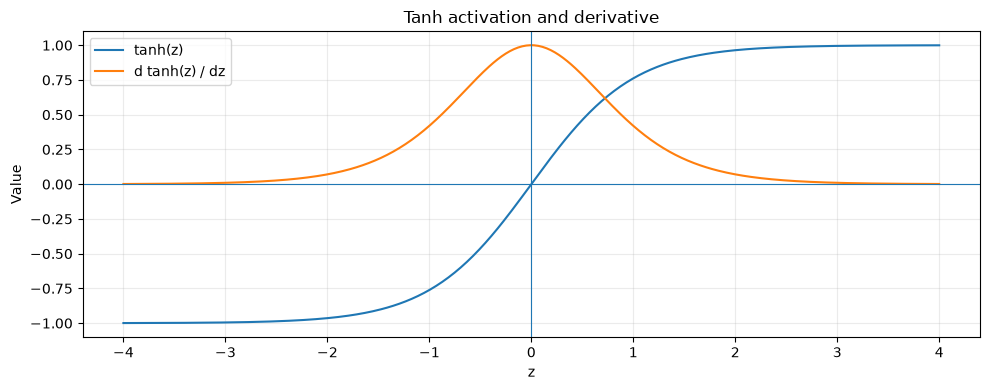

In [3]:
# Purpose: Visualize the tanh activation and its derivative so the recurrent non-linearity is directly observable.
z = np.linspace(-4, 4, 400)
tanh_z = np.tanh(z)
derivative = 1 - np.tanh(z) ** 2

plt.figure(figsize=(10, 4))
plt.plot(z, tanh_z, label="tanh(z)")
plt.plot(z, derivative, label="d tanh(z) / dz")
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.title("Tanh activation and derivative")
plt.xlabel("z")
plt.ylabel("Value")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


### 4.1 Unrolled RNN architecture

The recurrent cell itself is reused at every time step. The following diagram makes the parameter-sharing idea explicit: the same recurrent transformation is applied repeatedly, while the hidden state carries information from one step to the next.

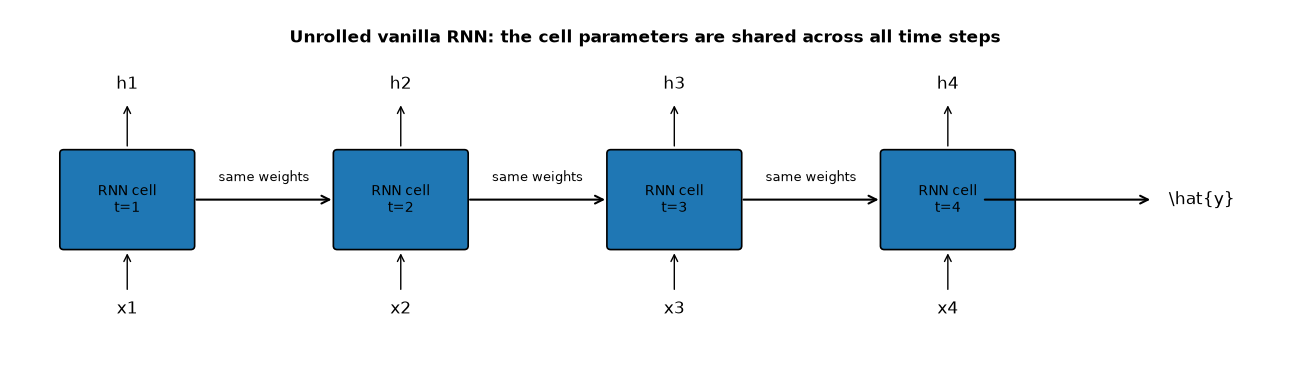

In [4]:
# Purpose: Visualize the unrolled RNN computation and the flow of hidden state across time.
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(13, 4))
ax.set_xlim(0, 13); ax.set_ylim(0, 4); ax.axis("off")

steps = [1, 2, 3, 4]
xs = [1.2, 4.0, 6.8, 9.6]
for x_pos, t in zip(xs, steps):
    box = FancyBboxPatch((x_pos-0.65, 1.45), 1.3, 1.0, boxstyle="round,pad=0.04", linewidth=1.2)
    ax.add_patch(box)
    ax.text(x_pos, 1.95, f"RNN cell\nt={t}", ha="center", va="center", fontsize=10)
    ax.text(x_pos, 0.72, f"x{t}", ha="center", fontsize=12)
    ax.add_patch(FancyArrowPatch((x_pos, 0.95), (x_pos, 1.4), arrowstyle="->", mutation_scale=12, linewidth=1))
    ax.text(x_pos, 3.15, f"h{t}", ha="center", fontsize=12)
    ax.add_patch(FancyArrowPatch((x_pos, 2.5), (x_pos, 3.0), arrowstyle="->", mutation_scale=12, linewidth=1))

for a, b in zip(xs[:-1], xs[1:]):
    ax.add_patch(FancyArrowPatch((a+0.68, 1.95), (b-0.68, 1.95), arrowstyle="->", mutation_scale=14, linewidth=1.5))
    ax.text((a+b)/2, 2.15, "same weights", ha="center", fontsize=9)

ax.add_patch(FancyArrowPatch((9.95, 1.95), (11.7, 1.95), arrowstyle="->", mutation_scale=14, linewidth=1.5))
ax.text(12.2, 1.95, "\u005Chat{y}", ha="center", va="center", fontsize=12)
ax.text(6.5, 3.65, "Unrolled vanilla RNN: the cell parameters are shared across all time steps", ha="center", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()


## 5. RNN functions and operators

The scratch implementation is intentionally small enough that every major operation can be traced:

```text
matrix multiplication
      ↓
add recurrent contribution
      ↓
add bias
      ↓
tanh
      ↓
new hidden state
      ↓
repeat over time
      ↓
linear output head
```

At the operator level, an RNN uses only a few fundamental ideas:

### 5.1 Matrix multiplication

For a batch:

$$Z = XW$$

This combines input features using learned weights.

### 5.2 Bias addition

$$Z = XW + b$$

The bias allows the affine transformation to shift independently of the input.

### 5.3 Recurrent state update

$$h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b_h)$$

The previous hidden state is part of the current computation.

### 5.4 Linear regression head

$$\hat{y} = h_LW_{hy} + b_y$$

### 5.5 Mean squared error

For a target $y$ and prediction $\hat y$:

$$MSE = \frac{1}{N}\sum_{i=1}^{N}(y_i-\hat y_i)^2$$

MSE strongly penalizes large errors and is convenient for gradient-based regression training.


In [5]:
# Purpose: Demonstrate one RNN step with explicit NumPy operators.
def rnn_step_numpy(x_t, h_prev, W_xh, W_hh, b_h):
    """Compute h_t = tanh(W_xh contribution + W_hh recurrent contribution + bias)."""
    z_t = x_t @ W_xh + h_prev @ W_hh + b_h
    h_t = np.tanh(z_t)
    return h_t, z_t

# Tiny hand-checkable example: B=1, F=2, H=3.
x_t = np.array([[0.4, -0.2]], dtype=np.float32)
h_prev = np.zeros((1, 3), dtype=np.float32)
W_xh = np.array([[0.4, -0.3, 0.2], [0.1, 0.5, -0.4]], dtype=np.float32)
W_hh = np.eye(3, dtype=np.float32) * 0.7
b_h = np.array([[0.1, 0.0, -0.1]], dtype=np.float32)

h_t, z_t = rnn_step_numpy(x_t, h_prev, W_xh, W_hh, b_h)
print("z_t:", z_t)
print("h_t:", h_t)


z_t: [[ 0.24000001 -0.22        0.06000001]]
h_t: [[ 0.23549575 -0.21651806  0.05992812]]


## 6. Backpropagation Through Time, vanishing gradients, and optimization

When the recurrent computation is unfolded across the window, the network becomes a deep computational chain in the time dimension:

```text
x1 → h1 → h2 → h3 → ... → hL → y_hat
       ↘    ↘    ↘            ↘
        recurrent dependencies
```

The backward pass therefore has to propagate gradients through multiple time steps. This is called **Backpropagation Through Time (BPTT)**.

For an early hidden state, the gradient depends on repeated products involving the recurrent Jacobian. In simplified form, repeated multiplication can behave like:

$$\frac{\partial h_t}{\partial h_{t-1}} \approx W_{hh}^T \operatorname{diag}(1-h_t^2)$$

If the effective factors repeatedly have magnitude below one, gradients can shrink toward zero (**vanishing gradients**). If they become repeatedly too large, gradients can grow rapidly (**exploding gradients**).

### Gradient clipping

The training loop uses global gradient-norm clipping:

$$g' = g\min\left(1, \frac{c}{\|g\|_2}\right)$$

where $c$ is the chosen maximum norm.

Clipping is mainly a defense against **exploding gradients**. It does not solve the underlying vanishing-gradient problem.

### Parameter update

For gradient descent:

$$\theta \leftarrow \theta - \eta\nabla_\theta L$$

where $\eta$ is the learning rate.

The Keras and PyTorch experiments use Adam. The scratch implementation contains a manual Adam update so that the high-level optimizer call can be related back to the same gradient-based principle.


### Adam optimizer equations

For gradient $g_t$ at optimization step $t$, Adam maintains exponential moving averages:

$$m_t = \beta_1 m_{t-1} + (1-\beta_1)g_t$$

$$v_t = \beta_2 v_{t-1} + (1-\beta_2)g_t^2$$

The bias-corrected moments are:

$$\hat m_t = \frac{m_t}{1-\beta_1^t}, \qquad \hat v_t = \frac{v_t}{1-\beta_2^t}$$

and the parameter update is:

$$\theta_t = \theta_{t-1} - \eta \frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}$$

The scratch implementation computes these operations explicitly, while Keras and PyTorch provide optimized optimizer implementations.


## 7. Time-series window construction and leakage prevention

Time-series experiments require stricter preprocessing discipline than ordinary random tabular splits.

### 7.1 Chronological split

The series is partitioned in time order:

```text
|-------------------- Train --------------------|------ Validation ------|------ Test ------|
past                                                                                      future
```

The experiment uses approximately:

- **70% training**
- **15% validation**
- **15% test**

No random shuffling is used when constructing the final chronological partitions.

### 7.2 Train-only scaling

RNN optimization is sensitive to feature scale. The notebook uses `MinMaxScaler` to map each feature into a bounded interval.

For a feature $x$:

$$x' = a + (x-x_{min})\frac{b-a}{x_{max}-x_{min}}$$

with the default target range $[0,1]$.

Crucially, the scaler is **fit only on the training portion**. Validation and test values are transformed using the parameters learned from training.

This prevents future information from influencing preprocessing statistics.

### 7.3 Window alignment

The window creator uses history ending at time $t$ to predict the target at $t+1$:

```text
features[t-L+1 : t+1]  →  target[t+1]
```

For validation and test targets, the input context may contain earlier observations from the preceding partition. That is not leakage: those values would already be known at prediction time.


## 8. Metrics and persistence baselines

The assignment is a regression problem, so classification metrics such as accuracy, precision, recall, and confusion matrices are not appropriate primary metrics.

### Mean Absolute Error (MAE)

$$MAE = \frac{1}{N}\sum_{i=1}^{N}|y_i-\hat y_i|$$

MAE is measured in the original target unit and is easy to interpret. Lower values are better.

### Root Mean Squared Error (RMSE)

$$RMSE = \sqrt{\frac{1}{N}\sum_{i=1}^{N}(y_i-\hat y_i)^2}$$

RMSE places more emphasis on larger errors because the error is squared before averaging. Lower is better.

### Mean Absolute Percentage Error (MAPE)

$$MAPE = \frac{100}{N}\sum_{i=1}^{N}\left|\frac{y_i-\hat y_i}{y_i}\right|$$

MAPE expresses error as a percentage. It is useful when targets are strictly positive, as is the case for delivery time and stock prices here. A small epsilon is used in code to avoid numerical division by zero.

### Coefficient of determination ($R^2$)

$$R^2 = 1 - \frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}$$

$R^2=1$ indicates perfect prediction. It can be negative when a model performs worse than predicting the mean of the evaluated target values.

### Persistence baseline

A forecasting model should be compared against a simple reference strategy. The notebook uses a persistence baseline:

$$\hat y_{t+1}=y_t$$

This baseline answers an important engineering question: does the RNN extract useful temporal structure beyond simply repeating the latest observed target?


In [6]:
# Purpose: Define shared regression metrics and a persistence baseline.
def regression_metrics(y_true, y_pred):
    """Return the main regression metrics in original target units."""
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    eps = 1e-8
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAPE_percent": float(np.mean(np.abs((y_true - y_pred) / np.maximum(np.abs(y_true), eps))) * 100),
        "R2": float(r2_score(y_true, y_pred)),
    }


def persistence_forecast_from_target_series(values):
    """Predict each next value by repeating the previous observed value."""
    values = np.asarray(values).reshape(-1)
    return values[:-1]

print(regression_metrics([1,2,3], [1.1,2.0,2.6]))


{'MAE': 0.16666666666666666, 'RMSE': 0.23804761428476162, 'MAPE_percent': 7.7777777777777795, 'R2': 0.915}


In [7]:
# Purpose: Provide common time-series preprocessing and visualization helpers.
def chronological_split_indices(n, train_ratio=0.70, val_ratio=0.15):
    """Return integer boundaries for a chronological train/validation/test split."""
    train_end = int(n * train_ratio)
    val_end = int(n * (train_ratio + val_ratio))
    return train_end, val_end


def fit_scalers(X_raw, y_raw, train_end):
    """Fit feature and target MinMaxScaler objects using the training prefix only."""
    x_scaler = MinMaxScaler()
    y_scaler = MinMaxScaler()
    x_scaler.fit(X_raw[:train_end])
    y_scaler.fit(y_raw[:train_end].reshape(-1, 1))
    return x_scaler, y_scaler


def make_windows(X_scaled, y_scaled, dates, lookback, target_start, target_end):
    """Create sequence-to-one windows while keeping target membership chronological."""
    Xs, ys, ds, target_idx = [], [], [], []
    for i in range(max(lookback, target_start), target_end):
        Xs.append(X_scaled[i-lookback:i])
        ys.append(y_scaled[i])
        ds.append(dates[i])
        target_idx.append(i)
    return (
        np.asarray(Xs, dtype=np.float32),
        np.asarray(ys, dtype=np.float32).reshape(-1, 1),
        np.asarray(ds),
        np.asarray(target_idx, dtype=np.int64),
    )


def plot_time_series(df, date_col, value_cols, title, rolling=14):
    """Plot raw series and optional rolling means for temporal pattern inspection."""
    plt.figure(figsize=(13, 5))
    for col in value_cols:
        plt.plot(df[date_col], df[col], label=col, alpha=0.75)
        if rolling and len(df) > rolling:
            plt.plot(df[date_col], df[col].rolling(rolling).mean(), linewidth=2, label=f"{col} ({rolling}-step mean)")
    plt.title(title)
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


def plot_feature_distributions(df, feature_cols, title):
    """Display histograms for the engineered time-series features."""
    cols = min(3, len(feature_cols))
    rows = math.ceil(len(feature_cols) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(14, 3.2 * rows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, feature_cols):
        ax.hist(df[col].dropna(), bins=40)
        ax.set_title(col)
        ax.grid(alpha=0.2)
    for ax in axes[len(feature_cols):]:
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def plot_correlation_heatmap(df, cols, title):
    """Plot Pearson correlation among selected numeric features."""
    corr = df[cols].corr()
    plt.figure(figsize=(9, 7))
    plt.imshow(corr.values, aspect="auto")
    plt.colorbar(label="Correlation")
    plt.xticks(range(len(cols)), cols, rotation=45, ha="right")
    plt.yticks(range(len(cols)), cols)
    plt.title(title)
    plt.tight_layout()
    plt.show()


def plot_split_boundaries(dates, values, train_end, val_end, title):
    """Visualize the chronological train/validation/test boundaries."""
    dates = pd.to_datetime(dates)
    values = np.asarray(values).reshape(-1)
    plt.figure(figsize=(13, 5))
    plt.plot(dates, values, linewidth=1.5)
    if train_end < len(dates):
        plt.axvline(dates.iloc[train_end] if hasattr(dates, 'iloc') else dates[train_end], linestyle="--", linewidth=1.5, label="Train → Validation")
    if val_end < len(dates):
        plt.axvline(dates.iloc[val_end] if hasattr(dates, 'iloc') else dates[val_end], linestyle=":", linewidth=1.5, label="Validation → Test")
    plt.title(title)
    plt.xlabel("Time")
    plt.ylabel("Target")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


def plot_prediction_diagnostics(dates, y_true, y_pred, title):
    """Show actual-vs-predicted series and predicted-vs-actual scatter plots."""
    dates = pd.to_datetime(dates)
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    residuals = y_true - y_pred
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))

    axes[0,0].plot(dates, y_true, label="Actual")
    axes[0,0].plot(dates, y_pred, label="Predicted")
    axes[0,0].set_title("Actual vs predicted over time")
    axes[0,0].legend(); axes[0,0].grid(alpha=0.2)

    axes[0,1].scatter(y_true, y_pred, s=18, alpha=0.6)
    lo = min(y_true.min(), y_pred.min()); hi = max(y_true.max(), y_pred.max())
    axes[0,1].plot([lo, hi], [lo, hi], linestyle="--")
    axes[0,1].set_title("Prediction scatter")
    axes[0,1].set_xlabel("Actual"); axes[0,1].set_ylabel("Predicted")
    axes[0,1].grid(alpha=0.2)

    axes[1,0].hist(residuals, bins=35)
    axes[1,0].axvline(0, linestyle="--")
    axes[1,0].set_title("Residual distribution")
    axes[1,0].set_xlabel("Residual = actual - predicted")
    axes[1,0].grid(alpha=0.2)

    axes[1,1].plot(dates, residuals)
    axes[1,1].axhline(0, linestyle="--")
    axes[1,1].set_title("Residuals over time")
    axes[1,1].grid(alpha=0.2)

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def rolling_mae(y_true, y_pred, window=20):
    """Return a rolling MAE series for drift and regime-change inspection."""
    err = np.abs(np.asarray(y_true).reshape(-1) - np.asarray(y_pred).reshape(-1))
    return pd.Series(err).rolling(window).mean()


def _json_safe(obj):
    """Recursively convert NumPy values and non-finite floats into JSON-safe Python values."""
    if isinstance(obj, dict):
        return {str(k): _json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_json_safe(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating, float)):
        value = float(obj)
        return value if np.isfinite(value) else None
    if isinstance(obj, np.ndarray):
        return _json_safe(obj.tolist())
    return obj


def save_json(obj, path):
    """Serialize an object into strict JSON for web-demo and report reuse."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    safe_obj = _json_safe(obj)
    path.write_text(json.dumps(safe_obj, indent=2, allow_nan=False, default=str), encoding="utf-8")


## 9. Shared RNN experiment configuration

A controlled experiment is easier to interpret when architecture and optimization choices are explicit.

The three implementations use the same conceptual model:

```text
Input sequence (L × F)
        ↓
Vanilla tanh RNN (64 hidden units)
        ↓
Final hidden state
        ↓
Dropout 
        ↓
Linear regression head
        ↓
One-step prediction
```

### Shared hyperparameters

| Parameter | Value | Purpose |
|---|---:|---|
| Lookback length | 14 | historical context window |
| Hidden size | 64 | recurrent representation dimension |
| Dropout | 0.00 | disabled so all three implementations share the same recurrent-to-output path |
| Loss | MSE | regression training objective |
| Optimizer | Adam | adaptive gradient optimization |
| Learning rate | 0.001 | initial step size |
| Batch size | 32 | mini-batch size |
| Maximum epochs | 40 | upper bound on training |
| Early stopping | 6 epochs | stop after validation stagnation |
| Reduce LR patience | 2 epochs | decrease learning rate when validation stalls |
| Gradient clip norm | 1.0 | control exploding gradients |
| Split | 70 / 15 / 15 | chronological train/validation/test |


### Controlled-comparison note

The implementation frameworks do not necessarily initialize parameters with identical random distributions. Keras and PyTorch also expose slightly different internal bias parameterizations. The experimental control therefore focuses on the same **problem definition, lookback, hidden size, loss, optimizer family, batch size, early-stopping policy, learning-rate schedule, gradient clipping threshold, and train/validation/test protocol** rather than claiming bit-for-bit identical training trajectories.

In [8]:
# Purpose: Store common experiment hyperparameters in one reproducible configuration object.
LOOKBACK = 14
HIDDEN_SIZE = 64

# Dropout is intentionally disabled so Scratch, Keras, and PyTorch use the same
# recurrent + linear architecture during the controlled framework comparison.
DROPOUT = 0.0

LEARNING_RATE = 1e-3
BATCH_SIZE = 32
MAX_EPOCHS = 40
EARLY_STOPPING_PATIENCE = 6
LR_PATIENCE = 2
LR_FACTOR = 0.5
MIN_LEARNING_RATE = 1e-5
GRAD_CLIP_NORM = 1.0
DEVICE_MODE = "CPU"  # CPU keeps the three implementations directly comparable.

CONFIG = {
    "lookback": LOOKBACK,
    "hidden_size": HIDDEN_SIZE,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "lr_patience": LR_PATIENCE,
    "lr_factor": LR_FACTOR,
    "min_learning_rate": MIN_LEARNING_RATE,
    "gradient_clip_norm": GRAD_CLIP_NORM,
    "device": DEVICE_MODE,
    "split": {"train": 0.70, "validation": 0.15, "test": 0.15},
}
print(json.dumps(CONFIG, indent=2))


{
  "lookback": 14,
  "hidden_size": 64,
  "dropout": 0.0,
  "learning_rate": 0.001,
  "batch_size": 32,
  "max_epochs": 40,
  "early_stopping_patience": 6,
  "lr_patience": 2,
  "lr_factor": 0.5,
  "min_learning_rate": 1e-05,
  "gradient_clip_norm": 1.0,
  "device": "CPU",
  "split": {
    "train": 0.7,
    "validation": 0.15,
    "test": 0.15
  }
}


# Part B - Dataset 1: E-commerce service process

## 10. Dataset loading and raw-data audit

The raw Olist orders table contains one row per order and records the major timestamps in the fulfillment lifecycle.

The notebook first checks whether `data/ecommerce/olist_orders_dataset.csv` already exists. If not, it offers an automatic download from a public GitHub mirror of the Olist orders file. The Kaggle page remains the primary provenance reference.


In [9]:
# Purpose: Locate or download the Olist orders table used for the service-process transformation.
from urllib.request import urlretrieve

ECOM_DIR = DATA_DIR / "ecommerce"
ECOM_FILE = ECOM_DIR / "olist_orders_dataset.csv"
ECOM_DIR.mkdir(parents=True, exist_ok=True)

ECOM_PRIMARY_URL = "https://www.kaggle.com/olistbr/brazilian-ecommerce"
ECOM_MIRROR_URL = "https://raw.githubusercontent.com/HarshGupta-DS/E-Commerce_Analysis/main/olist_orders_dataset.csv"

if not ECOM_FILE.exists():
    print("Local Olist file was not found.")
    print("Attempting public mirror download...")
    try:
        urlretrieve(ECOM_MIRROR_URL, ECOM_FILE)
        print("Downloaded:", ECOM_FILE)
    except Exception as exc:
        raise FileNotFoundError(
            "Could not download the Olist orders table. Please download olist_orders_dataset.csv "
            "from Kaggle and place it in data/ecommerce/."
        ) from exc

olist_raw = pd.read_csv(ECOM_FILE)
print("Shape:", olist_raw.shape)
print("Columns:")
print(olist_raw.columns.tolist())
display(olist_raw.head())


Shape: (99441, 8)
Columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


Duplicate order_id rows: 0
Timestamp columns:
  order_purchase_timestamp: 0 missing
  order_approved_at: 160 missing
  order_delivered_carrier_date: 1,783 missing
  order_delivered_customer_date: 2,965 missing
  order_estimated_delivery_date: 0 missing


,column,dtype,missing,missing_percent,unique
0,order_id,str,0,0.000000,99441
1,customer_id,str,0,0.000000,99441
2,order_status,str,0,0.000000,8
3,order_purchase_timestamp,str,0,0.000000,98875
4,order_approved_at,str,160,0.160899,90733
5,order_delivered_carrier_date,str,1783,1.793023,81018
6,order_delivered_customer_date,str,2965,2.981668,95664
7,order_estimated_delivery_date,str,0,0.000000,459


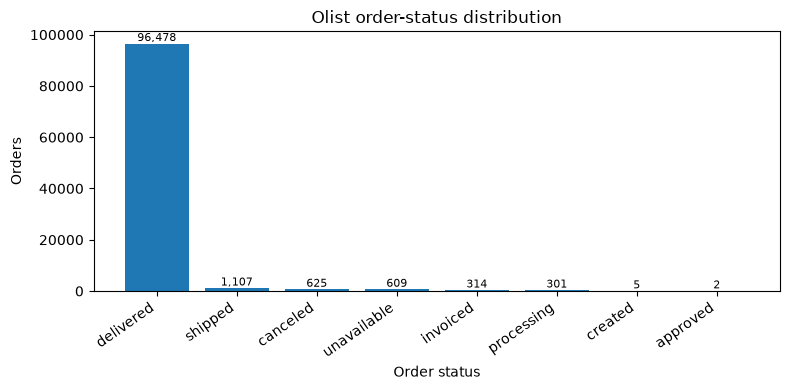

In [10]:
# Purpose: Audit schema quality, duplicate order identifiers, missingness, and status distribution before feature engineering.
def audit_olist_orders(df):
    timestamp_cols = [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ]
    audit = pd.DataFrame({
        "column": df.columns,
        "dtype": [str(df[c].dtype) for c in df.columns],
        "missing": [int(df[c].isna().sum()) for c in df.columns],
        "missing_percent": [float(df[c].isna().mean()*100) for c in df.columns],
        "unique": [int(df[c].nunique(dropna=True)) for c in df.columns],
    })
    print("Duplicate order_id rows:", int(df["order_id"].duplicated().sum()))
    print("Timestamp columns:")
    for c in timestamp_cols:
        print(f"  {c}: {int(df[c].isna().sum()):,} missing")
    display(audit)
    return audit

olist_audit = audit_olist_orders(olist_raw)

plt.figure(figsize=(8,4))
status_counts = olist_raw["order_status"].value_counts()
bars = plt.bar(status_counts.index, status_counts.values)
plt.title("Olist order-status distribution")
plt.xlabel("Order status")
plt.ylabel("Orders")
plt.xticks(rotation=35, ha="right")
for bar, val in zip(bars, status_counts.values):
    plt.text(bar.get_x()+bar.get_width()/2, val, f"{val:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()


## 11. Service-process feature engineering

To make the event-level order data suitable for RNN forecasting, each delivered order contributes several elapsed-time variables.

For an order:

$$delivery\_days = \frac{t_{delivered}-t_{purchase}}{24\text{ hours}}$$

$$approval\_hours = \frac{t_{approved}-t_{purchase}}{1\text{ hour}}$$

$$carrier\_hours = \frac{t_{carrier}-t_{approved}}{1\text{ hour}}$$

$$promised\_days = \frac{t_{estimated}-t_{purchase}}{24\text{ hours}}$$

and the late indicator is:

$$late = \mathbb{1}(t_{delivered} > t_{estimated})$$

The time-series index is the **customer delivery date**, because that date represents when the fulfillment service was completed.

For each observed service day, the engineered series contains:

| Feature | Meaning |
|---|---|
| `delivered_order_count` | number of orders delivered that day |
| `avg_approval_hours` | average purchase-to-approval duration |
| `avg_carrier_hours` | average approval-to-carrier duration |
| `avg_promised_days` | average promised delivery lead time |
| `late_rate` | fraction delivered after the estimated date |
| `avg_delivery_days` | average purchase-to-delivery duration for that completed service day |
| `previous_avg_delivery_days` | observed duration at the forecast origin; input signal for predicting the next service day |

The next-step forecasting target is shifted by one observed service day. This avoids using the future target directly in the current feature vector.


In [11]:
# Purpose: Convert order-level lifecycle events into a chronological service-performance series.
def build_ecommerce_service_series(df):
    """Create service-period features and the next-step delivery-time target from Olist orders."""
    data = df.copy()
    ts_cols = [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ]
    for col in ts_cols:
        data[col] = pd.to_datetime(data[col], errors="coerce")

    # Keep completed deliveries with the timestamps needed to compute service durations.
    delivered = data[
        (data["order_status"].eq("delivered"))
        & data["order_purchase_timestamp"].notna()
        & data["order_approved_at"].notna()
        & data["order_delivered_carrier_date"].notna()
        & data["order_delivered_customer_date"].notna()
        & data["order_estimated_delivery_date"].notna()
    ].copy()

    delivered["delivery_days"] = (
        delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]
    ).dt.total_seconds() / 86400.0
    delivered["approval_hours"] = (
        delivered["order_approved_at"] - delivered["order_purchase_timestamp"]
    ).dt.total_seconds() / 3600.0
    delivered["carrier_hours"] = (
        delivered["order_delivered_carrier_date"] - delivered["order_approved_at"]
    ).dt.total_seconds() / 3600.0
    delivered["promised_days"] = (
        delivered["order_estimated_delivery_date"] - delivered["order_purchase_timestamp"]
    ).dt.total_seconds() / 86400.0
    delivered["late"] = (
        delivered["order_delivered_customer_date"] > delivered["order_estimated_delivery_date"]
    ).astype(float)
    delivered["service_date"] = delivered["order_delivered_customer_date"].dt.floor("D")

    # Basic physical plausibility filters prevent broken timestamps from dominating the aggregate series.
    delivered = delivered[
        (delivered["delivery_days"] > 0)
        & (delivered["approval_hours"] >= 0)
        & (delivered["carrier_hours"] >= 0)
        & (delivered["promised_days"] > 0)
    ].copy()

    daily = delivered.groupby("service_date").agg(
        delivered_order_count=("order_id", "count"),
        avg_approval_hours=("approval_hours", "mean"),
        avg_carrier_hours=("carrier_hours", "mean"),
        avg_promised_days=("promised_days", "mean"),
        late_rate=("late", "mean"),
        avg_delivery_days=("delivery_days", "mean"),
    ).reset_index().sort_values("service_date")

    # The lag between observed service days is preserved explicitly for transparency.
    daily["days_since_previous_service_day"] = daily["service_date"].diff().dt.days.fillna(1).clip(lower=1)
    # At forecast origin t, the completed service-day target is known. Include it
    # as a lagged predictor for the next observed service day's target.
    daily["previous_avg_delivery_days"] = daily["avg_delivery_days"]
    return daily.reset_index(drop=True)

ecom_daily = build_ecommerce_service_series(olist_raw)
print("Service-series shape:", ecom_daily.shape)
print("Date range:", ecom_daily["service_date"].min(), "to", ecom_daily["service_date"].max())
display(ecom_daily.describe(include="all").T)
display(ecom_daily.head())


Service-series shape: (645, 9)
Date range: 2016-10-11 00:00:00 to 2018-10-17 00:00:00


,count,mean,min,25%,50%,75%,max,std
service_date,645,2017-10-26 20:59:09.767441,2016-10-11 00:00:00,2017-05-20 00:00:00,2017-10-30 00:00:00,2018-04-12 00:00:00,2018-10-17 00:00:00,NaN
delivered_order_count,645.0,147.449612,1.0,22.0,129.0,256.0,439.0,124.028671
avg_approval_hours,645.0,10.116926,0.0,7.691523,9.246893,10.931815,82.238611,7.199817
avg_carrier_hours,645.0,96.550878,3.270556,58.457189,67.665987,77.908723,1502.224722,144.004419
avg_promised_days,645.0,26.533926,7.501397,22.287664,24.281062,27.1128,94.647002,9.271622
late_rate,645.0,0.104211,0.0,0.015038,0.045045,0.109756,1.0,0.193566
avg_delivery_days,645.0,15.220451,3.630336,10.705892,12.389971,15.075401,143.411435,12.109411
days_since_previous_service_day,645.0,1.142636,1.0,1.0,1.0,1.0,14.0,0.97075
previous_avg_delivery_days,645.0,15.220451,3.630336,10.705892,12.389971,15.075401,143.411435,12.109411


,service_date,delivered_order_count,avg_approval_hours,avg_carrier_hours,avg_promised_days,late_rate,avg_delivery_days,days_since_previous_service_day,previous_avg_delivery_days
0,2016-10-11,2,0.570556,96.000278,59.428872,0.0,7.023785,1.0,7.023785
1,2016-10-13,14,27.411845,96.000258,53.313376,0.0,8.142171,2.0,8.142171
2,2016-10-14,15,10.975167,96.016519,54.142800,0.0,7.473449,1.0,7.473449
3,2016-10-15,17,27.410114,94.848742,55.798655,0.0,7.024449,1.0,7.024449
4,2016-10-16,7,16.371111,96.000198,55.622616,0.0,9.256997,1.0,9.256997


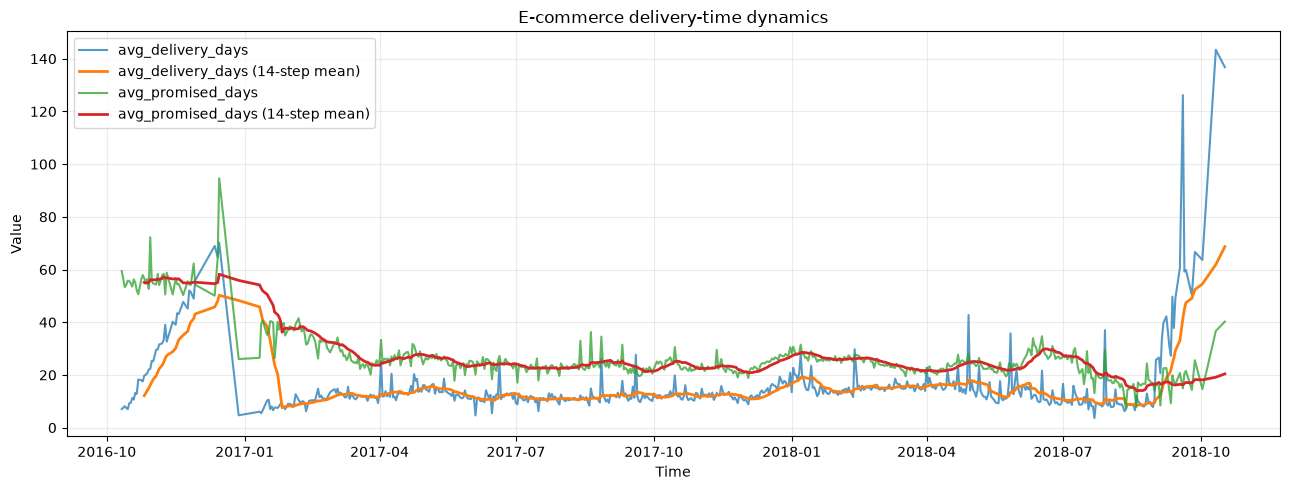

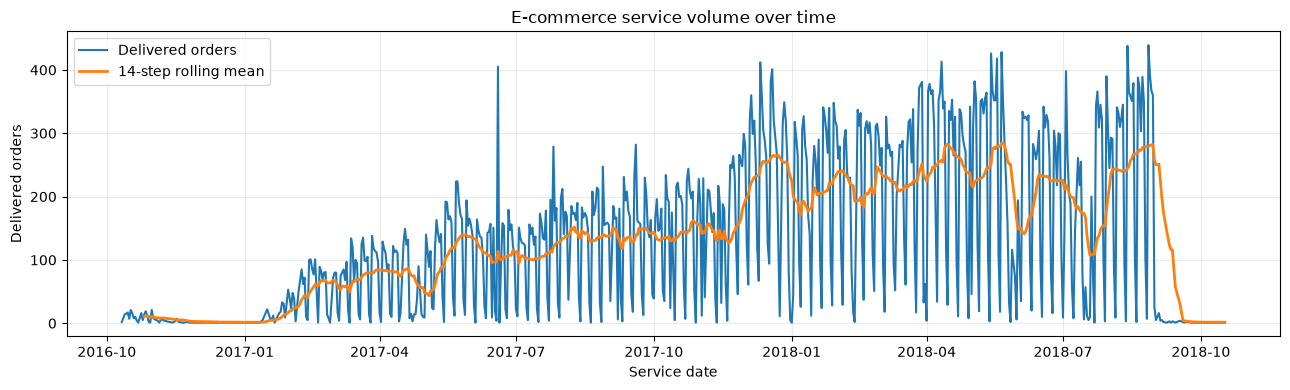

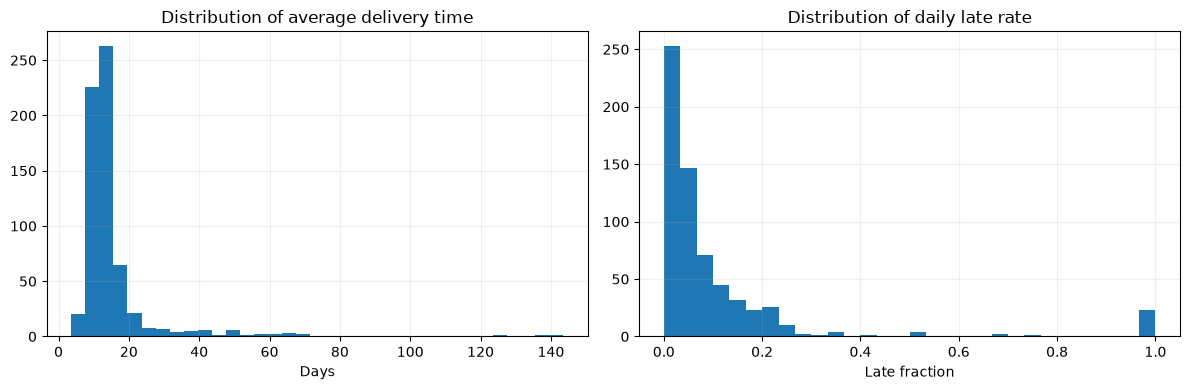

In [12]:
# Purpose: Visualize the main temporal behavior of the e-commerce service process.
plot_time_series(
    ecom_daily,
    "service_date",
    ["avg_delivery_days", "avg_promised_days"],
    "E-commerce delivery-time dynamics",
    rolling=14,
)

plt.figure(figsize=(13, 4))
plt.plot(ecom_daily["service_date"], ecom_daily["delivered_order_count"], label="Delivered orders")
plt.plot(ecom_daily["service_date"], ecom_daily["delivered_order_count"].rolling(14).mean(), label="14-step rolling mean", linewidth=2)
plt.title("E-commerce service volume over time")
plt.xlabel("Service date"); plt.ylabel("Delivered orders")
plt.legend(); plt.grid(alpha=0.25); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].hist(ecom_daily["avg_delivery_days"], bins=35)
axes[0].set_title("Distribution of average delivery time")
axes[0].set_xlabel("Days")
axes[0].grid(alpha=0.2)
axes[1].hist(ecom_daily["late_rate"], bins=30)
axes[1].set_title("Distribution of daily late rate")
axes[1].set_xlabel("Late fraction")
axes[1].grid(alpha=0.2)
plt.tight_layout(); plt.show()


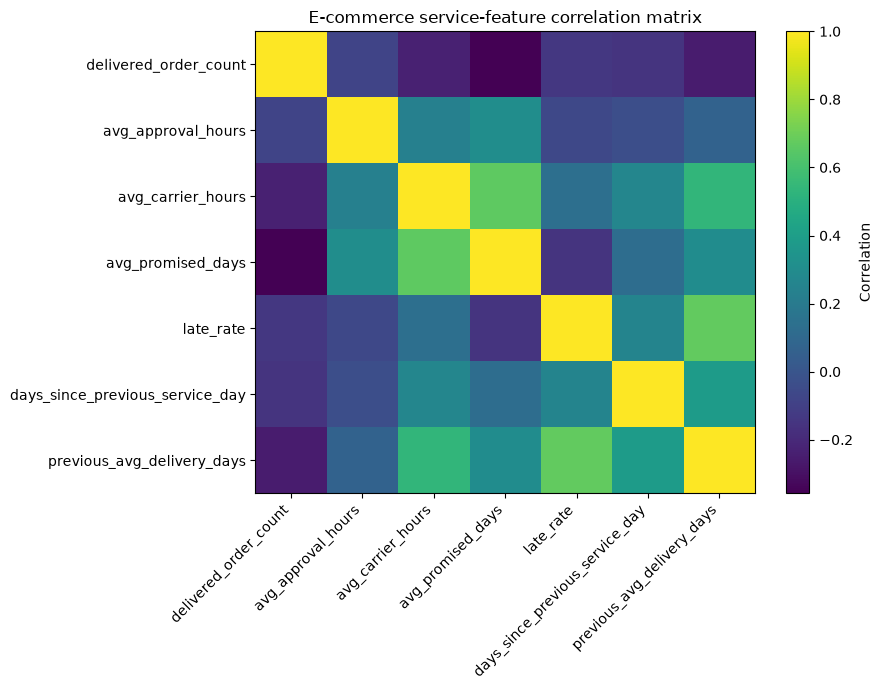

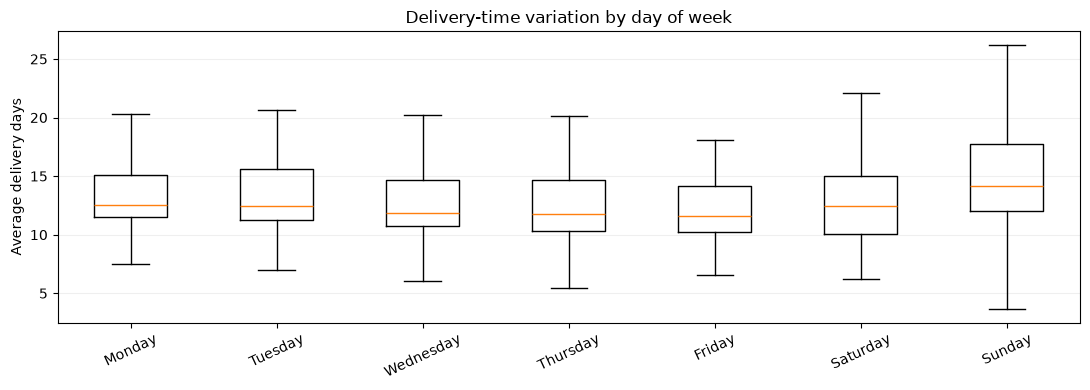

In [13]:
# Purpose: Reveal feature relationships and recurring weekly behavior in service performance.
ecom_feature_cols = [
    "delivered_order_count",
    "avg_approval_hours",
    "avg_carrier_hours",
    "avg_promised_days",
    "late_rate",
    "days_since_previous_service_day",
    "previous_avg_delivery_days",
]

plot_correlation_heatmap(
    ecom_daily,
    ecom_feature_cols,
    "E-commerce service-feature correlation matrix",
)

# Create a day-of-week column for weekly pattern analysis.
tmp = ecom_daily.copy()
tmp["day_of_week"] = pd.to_datetime(tmp["service_date"]).dt.day_name()

# Keep the natural Monday-to-Sunday order instead of alphabetical order.
order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

# Collect delivery-time observations for each weekday.
weekly = tmp.groupby("day_of_week")["avg_delivery_days"].apply(list)

# Prepare the data in the exact weekday order.
weekly_data = [weekly.get(day, []) for day in order]

plt.figure(figsize=(11, 4))

# Use tick_labels for newer Matplotlib versions.
plt.boxplot(
    weekly_data,
    tick_labels=order,
    showfliers=False,
)

plt.title("Delivery-time variation by day of week")
plt.ylabel("Average delivery days")
plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 12. Exploratory time-series interpretation

The EDA stage is used to answer four questions before modeling:

1. **Is the target ordered in time?** Yes. `service_date` is the chronological index.
2. **Does the target vary?** The daily average delivery time is not constant; it changes with operational conditions.
3. **Do the input variables contain temporal structure?** Service volume, delays, and late-rate fluctuate over time and can provide context for the next period.
4. **Are there obvious scale differences?** Yes. Counts, hours, days, and rates live on different numerical scales, which motivates train-only normalization.

A particularly important point is that the RNN does not automatically create meaning from a date string. The chronology is encoded by the **ordered sequence of feature vectors**. The network learns from the progression of numerical states through time.


## 12.1 Additional temporal diagnostics

Two diagnostics are especially useful before fitting an RNN:

1. **Autocorrelation** asks whether the target at time $t$ is statistically related to its own past values.
2. **Service-day gaps** show whether the observed service process is perfectly regular or contains missing calendar days.

The RNN receives observations in chronological order. It does not require every observation to be exactly one calendar day apart, but irregular spacing should not be silently ignored. The engineered `days_since_previous_service_day` feature records that temporal gap explicitly.

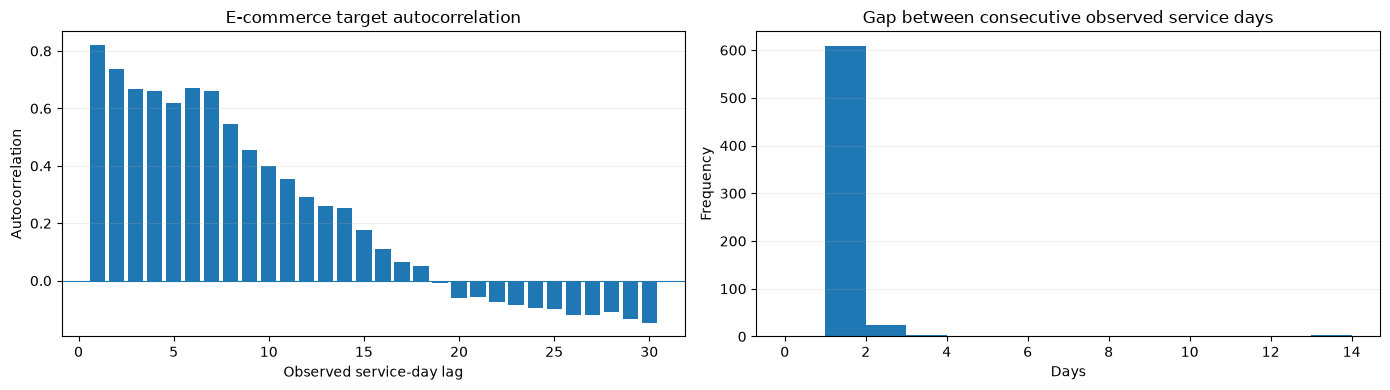

In [14]:
# Purpose: Inspect temporal dependence and irregular service-day spacing before window construction.
series = ecom_daily["avg_delivery_days"].dropna()
lag_range = range(1, min(31, len(series)))
acf = [series.autocorr(lag=lag) for lag in lag_range]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(list(lag_range), acf)
axes[0].axhline(0, linewidth=0.8)
axes[0].set_title("E-commerce target autocorrelation")
axes[0].set_xlabel("Observed service-day lag")
axes[0].set_ylabel("Autocorrelation")
axes[0].grid(axis="y", alpha=0.2)

axes[1].hist(ecom_daily["days_since_previous_service_day"], bins=np.arange(0.5, ecom_daily["days_since_previous_service_day"].max() + 1.5) - 0.5)
axes[1].set_title("Gap between consecutive observed service days")
axes[1].set_xlabel("Days")
axes[1].set_ylabel("Frequency")
axes[1].grid(axis="y", alpha=0.2)
plt.tight_layout(); plt.show()


## 13. Train / validation / test split and scaling

The split is performed after feature engineering but before fitting the scalers. The target for time step $t$ is the next observed service day's `avg_delivery_days`.

The aligned supervised dataset is:

$$X_t = [features_t, avg\_delivery\_days_t]$$

$$y_t = avg\_delivery\_days_{t+1}$$

The input includes the target already observed on the current service day, while the label belongs to the next observed service day. This makes the neural models comparable to the persistence baseline, which also uses the previous target.


In [15]:
# Purpose: Align the e-commerce service series into current-context features and next-step targets.
ecom_feature_cols = [
    "delivered_order_count",
    "avg_approval_hours",
    "avg_carrier_hours",
    "avg_promised_days",
    "late_rate",
    "days_since_previous_service_day",
    "previous_avg_delivery_days",
]
ecom_target_col = "avg_delivery_days"

ecom_dates = pd.to_datetime(ecom_daily["service_date"]).to_numpy()
ecom_X_raw = ecom_daily[ecom_feature_cols].to_numpy(dtype=np.float32)[:-1]
ecom_y_raw = ecom_daily[[ecom_target_col]].to_numpy(dtype=np.float32)[1:]
ecom_target_dates = ecom_dates[1:]

print("Aligned X shape:", ecom_X_raw.shape)
print("Aligned y shape:", ecom_y_raw.shape)
print("First target date:", ecom_target_dates[0], "Last target date:", ecom_target_dates[-1])


Aligned X shape: (644, 7)
Aligned y shape: (644, 1)
First target date: 2016-10-13T00:00:00.000000 Last target date: 2018-10-17T00:00:00.000000


Train / validation / test boundaries: 450 547 644


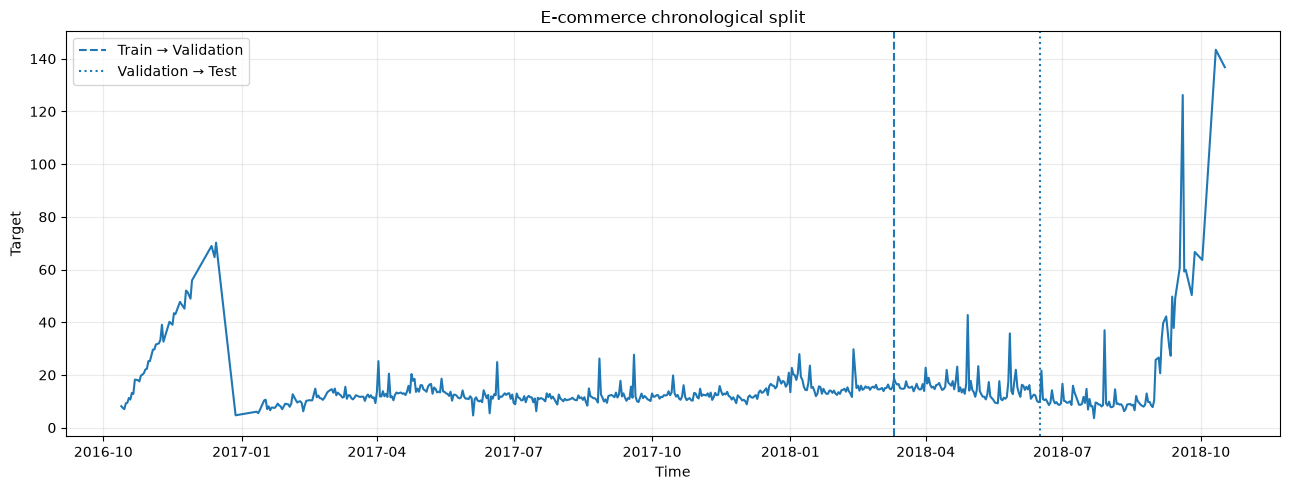

In [16]:
# Purpose: Create chronological split boundaries and fit scalers only on the training prefix.
ecom_train_end, ecom_val_end = chronological_split_indices(len(ecom_X_raw))
# Regress log1p(duration): it reduces the leverage of rare 100+ day outliers.
# The inverse transform in evaluation/web export maps predictions back to days.
ecom_y_model_raw = np.log1p(ecom_y_raw)
ecom_x_scaler, ecom_y_scaler = fit_scalers(
    ecom_X_raw, ecom_y_model_raw, ecom_train_end
)
ecom_X_scaled = ecom_x_scaler.transform(ecom_X_raw).astype(np.float32)
ecom_y_scaled = ecom_y_scaler.transform(ecom_y_model_raw).astype(np.float32)

print("Train / validation / test boundaries:", ecom_train_end, ecom_val_end, len(ecom_X_raw))
plot_split_boundaries(
    pd.Series(ecom_target_dates),
    ecom_y_raw.reshape(-1),
    ecom_train_end,
    ecom_val_end,
    "E-commerce chronological split",
)


Train windows: (436, 14, 7) (436, 1)
Validation windows: (97, 14, 7) (97, 1)
Test windows: (97, 14, 7) (97, 1)


,delivered_order_count,avg_approval_hours,avg_carrier_hours,avg_promised_days,late_rate,days_since_previous_service_day,previous_avg_delivery_days
2016-10-16,0.039,0.333,0.059,0.499,0.0,0.000,0.037
2016-10-17,0.015,0.199,0.060,0.497,0.0,0.000,0.071
2016-10-18,0.049,0.140,0.086,0.485,0.0,0.000,0.074
2016-10-19,0.036,0.297,0.108,0.470,0.0,0.000,0.101
2016-10-20,0.017,0.218,0.092,0.505,0.0,0.000,0.092
2016-10-21,0.022,0.441,0.155,0.489,0.0,0.000,0.130
2016-10-22,0.007,0.220,0.138,0.452,0.0,0.000,0.125
2016-10-24,0.000,0.616,0.139,0.433,0.0,0.000,0.208
2016-10-25,0.036,0.203,0.198,0.504,0.0,0.077,0.204
2016-10-26,0.010,0.071,0.205,0.527,0.0,0.000,0.197


Target date: 2016-10-31 00:00:00
Scaled target: 0.6069281101226807


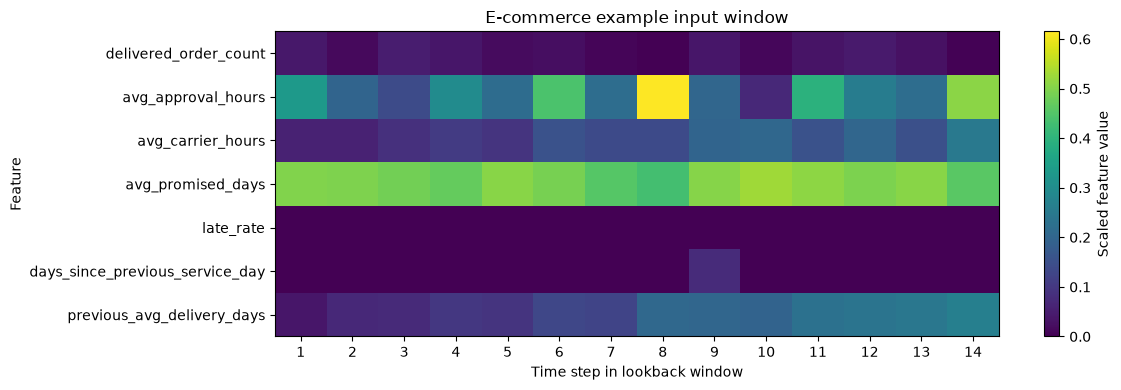

In [17]:
# Purpose: Build the three supervised window sets while preserving temporal order.
ecom_train_X, ecom_train_y, ecom_train_dates, ecom_train_idx = make_windows(
    ecom_X_scaled, ecom_y_scaled, ecom_target_dates, LOOKBACK, 0, ecom_train_end
)

ecom_val_X, ecom_val_y, ecom_val_dates, ecom_val_idx = make_windows(
    ecom_X_scaled, ecom_y_scaled, ecom_target_dates, LOOKBACK, ecom_train_end, ecom_val_end
)

ecom_test_X, ecom_test_y, ecom_test_dates, ecom_test_idx = make_windows(
    ecom_X_scaled, ecom_y_scaled, ecom_target_dates, LOOKBACK, ecom_val_end, len(ecom_X_scaled)
)

print("Train windows:", ecom_train_X.shape, ecom_train_y.shape)
print("Validation windows:", ecom_val_X.shape, ecom_val_y.shape)
print("Test windows:", ecom_test_X.shape, ecom_test_y.shape)

# Purpose: Show exactly what one RNN input window looks like.
example_i = min(3, len(ecom_train_X) - 1)

example_dates = pd.to_datetime(
    ecom_target_dates[
        ecom_train_idx[example_i] - LOOKBACK:ecom_train_idx[example_i]
    ]
)

example_df = pd.DataFrame(
    ecom_train_X[example_i],
    columns=ecom_feature_cols,
    index=example_dates
)

display(example_df.round(3))

print("Target date:", pd.to_datetime(ecom_train_dates[example_i]))

# Convert the one-element target array into a Python scalar.
print("Scaled target:", ecom_train_y[example_i].item())

# Purpose: Visualize the normalized values received by the RNN across time and features.
plt.figure(figsize=(12, 4))

plt.imshow(
    ecom_train_X[example_i].T,
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(label="Scaled feature value")

plt.xticks(
    range(LOOKBACK),
    [str(i + 1) for i in range(LOOKBACK)]
)

plt.yticks(
    range(len(ecom_feature_cols)),
    ecom_feature_cols
)

plt.xlabel("Time step in lookback window")
plt.ylabel("Feature")
plt.title("E-commerce example input window")

plt.tight_layout()
plt.show()

# 14. Scratch RNN - design and implementation

The scratch model is implemented with **NumPy only** for neural-network computation. No TensorFlow, Keras, or PyTorch is used inside the scratch training algorithm.

### Parameter shapes

For $F$ input features and $H$ hidden units:

- $W_{xh} \in \mathbb{R}^{F \times H}$
- $W_{hh} \in \mathbb{R}^{H \times H}$
- $b_h \in \mathbb{R}^{1 \times H}$
- $W_{hy} \in \mathbb{R}^{H \times 1}$
- $b_y \in \mathbb{R}^{1 \times 1}$

For the Scratch implementation, the hidden bias is represented by one vector, so the trainable count is:

$$P_{scratch}=FH + H^2 + H + H + 1$$

$$P_{scratch}=FH + H^2 + 2H + 1$$

Keras `SimpleRNN` also exposes one recurrent bias vector, while PyTorch `nn.RNN` stores separate input-hidden and hidden-hidden bias vectors. With `bias=True`, PyTorch therefore has:

$$P_{torch}=FH + H^2 + 2H + H + 1 = FH + H^2 + 3H + 1$$

The small $H$-parameter difference is a framework implementation detail, not a different recurrent learning objective.
The important learning step is manual BPTT. The code explicitly stores hidden states and computes gradients in reverse chronological order.


In [18]:
# Purpose: Implement the complete vanilla RNN forward pass using NumPy.
def init_scratch_rnn(n_features, hidden_size, seed=42):
    """Initialize recurrent and output-head parameters with deterministic small random values."""
    rng = np.random.default_rng(seed)
    scale_xh = np.sqrt(1.0 / max(n_features, 1))
    scale_hh = np.sqrt(1.0 / max(hidden_size, 1))
    params = {
        "W_xh": (rng.normal(0, scale_xh, size=(n_features, hidden_size)) * 0.5).astype(np.float32),
        "W_hh": (rng.normal(0, scale_hh, size=(hidden_size, hidden_size)) * 0.5).astype(np.float32),
        "b_h": np.zeros((1, hidden_size), dtype=np.float32),
        "W_hy": (rng.normal(0, scale_hh, size=(hidden_size, 1)) * 0.5).astype(np.float32),
        "b_y": np.zeros((1, 1), dtype=np.float32),
    }
    return params


def scratch_forward(X, params):
    """Unroll the RNN through a complete input window and return prediction plus cache."""
    B, T, F = X.shape
    H = params["W_hh"].shape[0]
    h = np.zeros((B, H), dtype=np.float32)
    hs = [h]
    zs = []

    for t in range(T):
        # The recurrent operator combines current input and previous memory.
        z = X[:, t, :] @ params["W_xh"] + h @ params["W_hh"] + params["b_h"]
        h = np.tanh(z)
        zs.append(z)
        hs.append(h)

    # Only the final hidden state feeds the regression head in this sequence-to-one model.
    y_hat = hs[-1] @ params["W_hy"] + params["b_y"]
    cache = {"X": X, "hs": hs, "zs": zs, "y_hat": y_hat}
    return y_hat, cache


def scratch_mse(y, y_hat):
    """Compute mean squared error for scratch training."""
    return float(np.mean((y_hat - y) ** 2))


def scratch_backward(y, cache, params):
    """Perform manual BPTT and return parameter gradients."""
    X = cache["X"]
    hs = cache["hs"]
    y_hat = cache["y_hat"]
    B, T, _ = X.shape

    grads = {k: np.zeros_like(v) for k, v in params.items()}
    # Derivative of mean squared error with respect to prediction.
    d_y = 2.0 * (y_hat - y) / B
    grads["W_hy"] = hs[-1].T @ d_y
    grads["b_y"] = np.sum(d_y, axis=0, keepdims=True)

    # The output head injects gradient into the final hidden state.
    dh_next = d_y @ params["W_hy"].T

    for t in reversed(range(T)):
        h_t = hs[t + 1]
        h_prev = hs[t]
        # tanh'(z) = 1 - tanh(z)^2
        dz = dh_next * (1.0 - h_t ** 2)
        grads["W_xh"] += X[:, t, :].T @ dz
        grads["W_hh"] += h_prev.T @ dz
        grads["b_h"] += np.sum(dz, axis=0, keepdims=True)
        dh_next = dz @ params["W_hh"].T

    return grads


def clip_grads(grads, max_norm=1.0):
    """Clip all gradients by one global L2 norm to reduce exploding updates."""
    total = 0.0
    for g in grads.values():
        total += float(np.sum(g.astype(np.float64) ** 2))
    total_norm = np.sqrt(total)
    scale = min(1.0, max_norm / (total_norm + 1e-12))
    return {k: g * scale for k, g in grads.items()}, float(total_norm), float(scale)


def scratch_adam_init(params):
    """Create first and second moment buffers for a manual Adam optimizer."""
    return {k: np.zeros_like(v) for k, v in params.items()}, {k: np.zeros_like(v) for k, v in params.items()}


def scratch_adam_step(params, grads, m, v, step, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
    """Update parameters using the Adam equations."""
    for key in params:
        m[key] = beta1 * m[key] + (1-beta1) * grads[key]
        v[key] = beta2 * v[key] + (1-beta2) * (grads[key] ** 2)
        m_hat = m[key] / (1-beta1**step)
        v_hat = v[key] / (1-beta2**step)
        params[key] -= lr * m_hat / (np.sqrt(v_hat) + eps)
    return m, v


def scratch_predict(X, params):
    """Run deterministic inference for an RNN parameter dictionary."""
    y_hat, cache = scratch_forward(X, params)
    return y_hat, cache


def scratch_parameter_count(params):
    """Count trainable values in a scratch model."""
    return int(sum(v.size for v in params.values()))


In [19]:
# Purpose: Verify scratch forward/backward shapes before launching a full training run.
param_demo = init_scratch_rnn(ecom_train_X.shape[-1], HIDDEN_SIZE, seed=SEED)
demo_pred, demo_cache = scratch_forward(ecom_train_X[:4], param_demo)
demo_grads = scratch_backward(ecom_train_y[:4], demo_cache, param_demo)

print("Input shape:", ecom_train_X[:4].shape)
print("Final hidden shape:", demo_cache["hs"][-1].shape)
print("Prediction shape:", demo_pred.shape)
print("W_xh shape:", param_demo["W_xh"].shape)
print("W_hh shape:", param_demo["W_hh"].shape)
print("W_hy shape:", param_demo["W_hy"].shape)
print("Parameter count:", scratch_parameter_count(param_demo))
print("Example gradient norm:", np.sqrt(sum(np.sum(g*g) for g in demo_grads.values())))


Input shape: (4, 14, 7)
Final hidden shape: (4, 64)
Prediction shape: (4, 1)
W_xh shape: (7, 64)
W_hh shape: (64, 64)
W_hy shape: (64, 1)
Parameter count: 4673
Example gradient norm: 2.0547268


### Numerical gradient check

Manual BPTT is easy to implement incorrectly because the recurrent hidden state creates dependencies across every time step. A finite-difference check provides an independent numerical sanity check for selected parameters.

For a parameter $\theta_i$:

$$\frac{\partial L}{\partial \theta_i} \approx \frac{L(\theta_i+\epsilon)-L(\theta_i-\epsilon)}{2\epsilon}$$

The numerical estimate should be close to the analytic BPTT gradient for a small test problem.

In [20]:
# Purpose: Validate one analytically derived scratch-RNN gradient with a finite-difference approximation.
def numerical_gradient_check():
    """Compare one BPTT gradient against a central finite-difference estimate."""
    rng = np.random.default_rng(7)
    X = rng.normal(size=(2, 4, 3)).astype(np.float64)
    y = rng.normal(size=(2, 1)).astype(np.float64)
    params = init_scratch_rnn(3, 5, seed=7)
    params = {k: v.astype(np.float64) for k, v in params.items()}

    # Analytical gradient computed by manual BPTT.
    pred, cache = scratch_forward(X, params)
    analytic = scratch_backward(y, cache, params)["W_xh"][0, 0].copy()

    original = params["W_xh"][0, 0].copy()
    eps = 1e-5
    params["W_xh"][0, 0] = original + eps
    loss_plus = scratch_mse(y, scratch_forward(X, params)[0])
    params["W_xh"][0, 0] = original - eps
    loss_minus = scratch_mse(y, scratch_forward(X, params)[0])
    params["W_xh"][0, 0] = original

    # Central finite difference approximates dL/dtheta.
    numerical = (loss_plus - loss_minus) / (2 * eps)
    relative_error = abs(analytic - numerical) / max(1e-8, abs(analytic) + abs(numerical))

    print(f"Analytic gradient : {analytic:.10f}")
    print(f"Numerical gradient: {numerical:.10f}")
    print(f"Relative error    : {relative_error:.3e}")
    return float(relative_error)

gradient_check_error = numerical_gradient_check()


Analytic gradient : 0.0305385821
Numerical gradient: 0.0305385821
Relative error    : 9.218e-11


### Hidden-state trajectory

The hidden-state norm $\lVert h_t \rVert_2$ is plotted over time for one input window. This is not a formal proof of gradient stability, but it is a useful visualization of how the recurrent representation changes as the sequence is processed.

In [21]:
# Purpose: Train the scratch RNN with manual BPTT, gradient clipping, Adam, LR scheduling, and early stopping.
def train_scratch_model(X_train, y_train, X_val, y_val, n_features, hidden_size, seed=42):
    """Train a scratch RNN and select the checkpoint with the lowest validation loss."""
    params = init_scratch_rnn(n_features, hidden_size, seed=seed)
    m, v = scratch_adam_init(params)
    history = {"train_loss": [], "val_loss": [], "lr": [], "grad_norm": [], "epoch_seconds": []}
    best_params = {k: val.copy() for k, val in params.items()}
    best_val = np.inf
    wait = 0
    lr_wait = 0
    current_lr = LEARNING_RATE
    step = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        epoch_start = time.perf_counter()
        # Shuffle only the training windows; chronology inside every window remains unchanged.
        order = np.random.permutation(len(X_train))
        batch_losses = []
        batch_sizes = []
        batch_grad_norms = []

        for start_i in range(0, len(order), BATCH_SIZE):
            idx = order[start_i:start_i + BATCH_SIZE]
            Xb, yb = X_train[idx], y_train[idx]
            y_hat, cache = scratch_forward(Xb, params)
            loss = scratch_mse(yb, y_hat)
            grads = scratch_backward(yb, cache, params)
            grads, grad_norm, _ = clip_grads(grads, GRAD_CLIP_NORM)
            step += 1
            m, v = scratch_adam_step(params, grads, m, v, step, lr=current_lr)
            batch_losses.append(loss)
            batch_sizes.append(len(idx))
            batch_grad_norms.append(grad_norm)

        # Weight batch losses by batch size so the final small batch does not receive equal weight.
        train_loss = float(np.average(batch_losses, weights=batch_sizes))
        val_pred, _ = scratch_predict(X_val, params)
        val_loss = scratch_mse(y_val, val_pred)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["lr"].append(current_lr)
        history["grad_norm"].append(float(np.mean(batch_grad_norms)))
        history["epoch_seconds"].append(time.perf_counter() - epoch_start)

        if val_loss < best_val - 1e-8:
            best_val = val_loss
            best_params = {k: val.copy() for k, val in params.items()}
            wait = 0
            lr_wait = 0
        else:
            wait += 1
            lr_wait += 1
            if lr_wait >= LR_PATIENCE:
                current_lr = max(MIN_LEARNING_RATE, current_lr * LR_FACTOR)
                lr_wait = 0
            if wait >= EARLY_STOPPING_PATIENCE:
                break

    return best_params, history

scratch_ecom_start = time.perf_counter()
scratch_ecom_params, scratch_ecom_history = train_scratch_model(
    ecom_train_X,
    ecom_train_y,
    ecom_val_X,
    ecom_val_y,
    n_features=ecom_train_X.shape[-1],
    hidden_size=HIDDEN_SIZE,
    seed=SEED,
)
scratch_ecom_time = time.perf_counter() - scratch_ecom_start
print("Scratch e-commerce training time (s):", round(scratch_ecom_time, 2))
print("Epochs completed:", len(scratch_ecom_history["train_loss"]))


Scratch e-commerce training time (s): 0.29
Epochs completed: 11


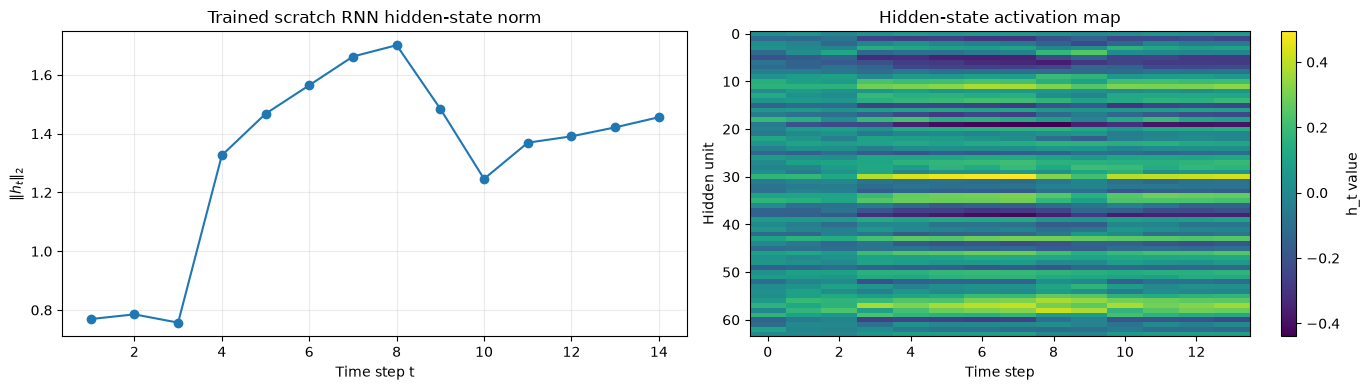

In [22]:
# Purpose: Visualize the evolution of the trained hidden representation
# across one input window.

if "scratch_ecom_params" not in globals():
    if "train_scratch_model" not in globals():
        raise RuntimeError(
            "Hãy chạy cell định nghĩa train_scratch_model trước cell này."
        )

    scratch_ecom_params, scratch_ecom_history = train_scratch_model(
        ecom_train_X,
        ecom_train_y,
        ecom_val_X,
        ecom_val_y,
        n_features=ecom_train_X.shape[-1],
        hidden_size=HIDDEN_SIZE,
        seed=SEED,
    )

one_window = ecom_test_X[:1]
_, one_cache = scratch_forward(one_window, scratch_ecom_params)

# Shape: (sequence_length, hidden_size)
state_matrix = np.stack(one_cache["hs"][1:], axis=1)[0]
state_norms = np.linalg.norm(state_matrix, axis=1)
n_steps = state_matrix.shape[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(range(1, n_steps + 1), state_norms, marker="o")
axes[0].set_title("Trained scratch RNN hidden-state norm")
axes[0].set_xlabel("Time step t")
axes[0].set_ylabel(r"$\|h_t\|_2$")
axes[0].grid(alpha=0.25)

im = axes[1].imshow(
    state_matrix.T,
    aspect="auto",
    interpolation="nearest"
)
axes[1].set_title("Hidden-state activation map")
axes[1].set_xlabel("Time step")
axes[1].set_ylabel("Hidden unit")
fig.colorbar(im, ax=axes[1], label="h_t value")

plt.tight_layout()
plt.show()

E-commerce Scratch test metrics:
{
  "MAE": 12.474786758422852,
  "RMSE": 26.56863555057977,
  "MAPE_percent": 47.320350646972656,
  "R2": -0.10260009765625
}


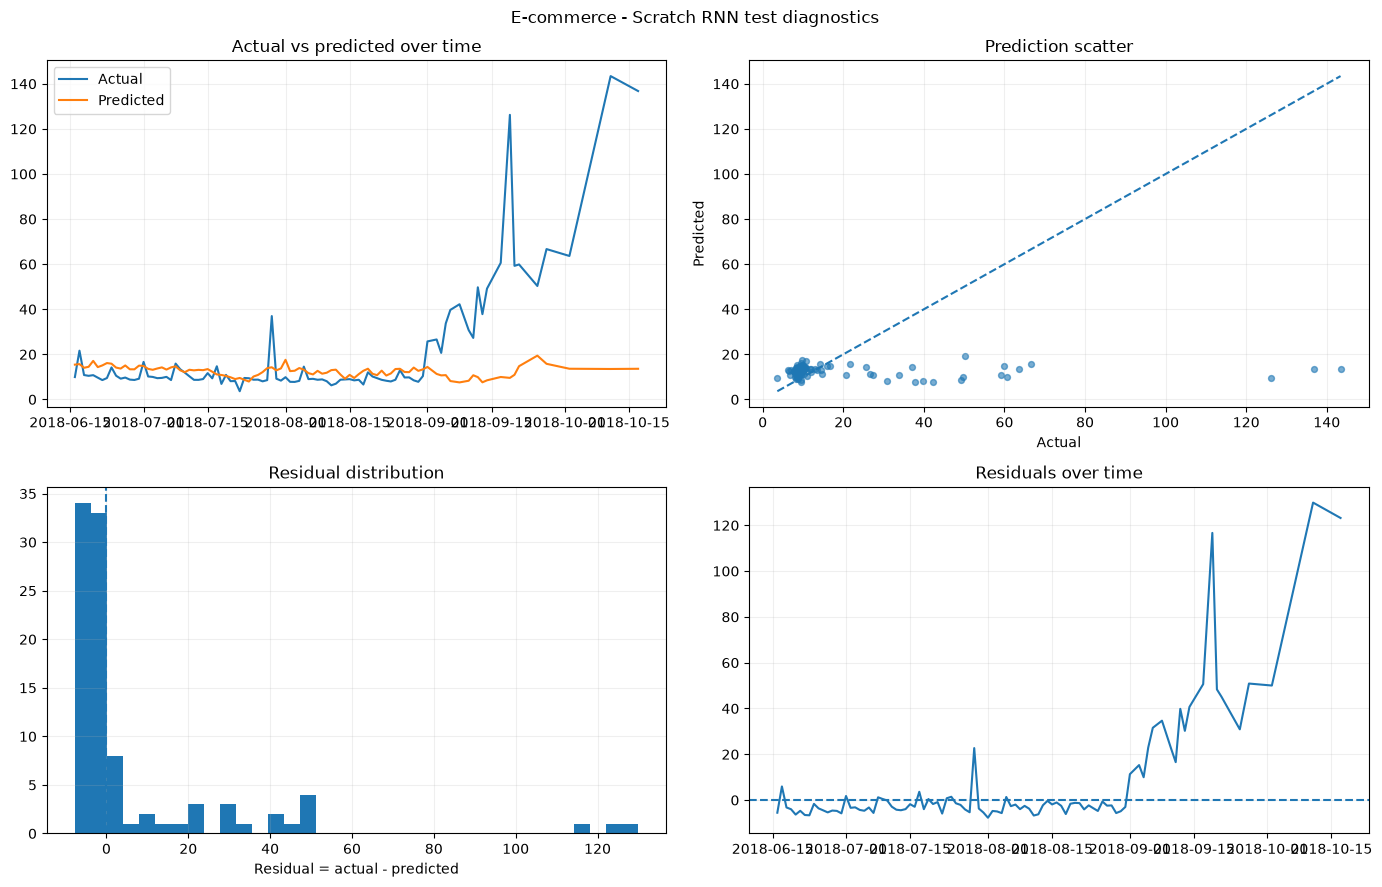

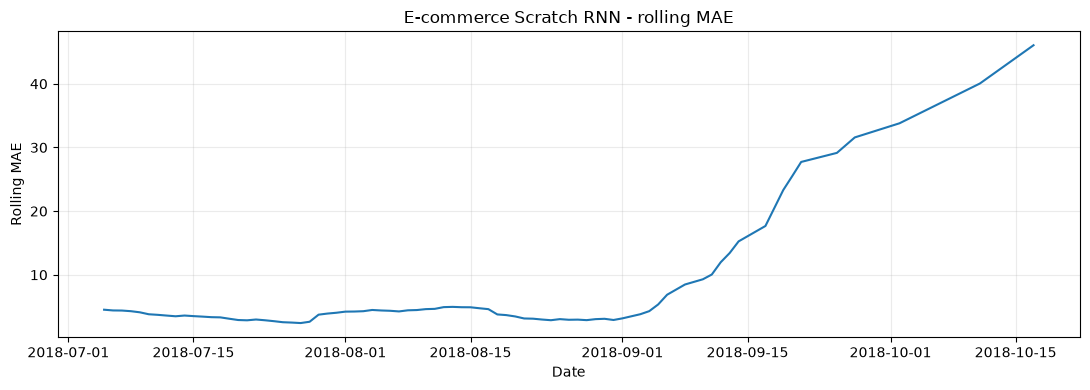

In [23]:
# Purpose: Evaluate the e-commerce scratch model in original target units.
def inverse_target(scaler, values):
    """Convert scaled predictions back to the target space fitted by a scaler."""
    return scaler.inverse_transform(np.asarray(values).reshape(-1,1)).reshape(-1)


def inverse_ecommerce_target(scaler, values):
    """Undo MinMax scaling and log1p, then enforce nonnegative delivery duration."""
    log_days = inverse_target(scaler, values)
    return np.expm1(np.maximum(log_days, 0.0))

scratch_ecom_val_scaled, scratch_ecom_val_cache = scratch_predict(ecom_val_X, scratch_ecom_params)
scratch_ecom_test_scaled, scratch_ecom_test_cache = scratch_predict(ecom_test_X, scratch_ecom_params)

scratch_ecom_val_pred = inverse_ecommerce_target(ecom_y_scaler, scratch_ecom_val_scaled)
scratch_ecom_test_pred = inverse_ecommerce_target(ecom_y_scaler, scratch_ecom_test_scaled)
scratch_ecom_val_true = inverse_ecommerce_target(ecom_y_scaler, ecom_val_y)
scratch_ecom_test_true = inverse_ecommerce_target(ecom_y_scaler, ecom_test_y)

scratch_ecom_metrics = regression_metrics(scratch_ecom_test_true, scratch_ecom_test_pred)
print("E-commerce Scratch test metrics:")
print(json.dumps(scratch_ecom_metrics, indent=2))

plot_prediction_diagnostics(
    ecom_test_dates,
    scratch_ecom_test_true,
    scratch_ecom_test_pred,
    "E-commerce - Scratch RNN test diagnostics",
)

plt.figure(figsize=(11,4))
plt.plot(ecom_test_dates, rolling_mae(scratch_ecom_test_true, scratch_ecom_test_pred, 20))
plt.title("E-commerce Scratch RNN - rolling MAE")
plt.xlabel("Date"); plt.ylabel("Rolling MAE")
plt.grid(alpha=0.25); plt.tight_layout(); plt.show()


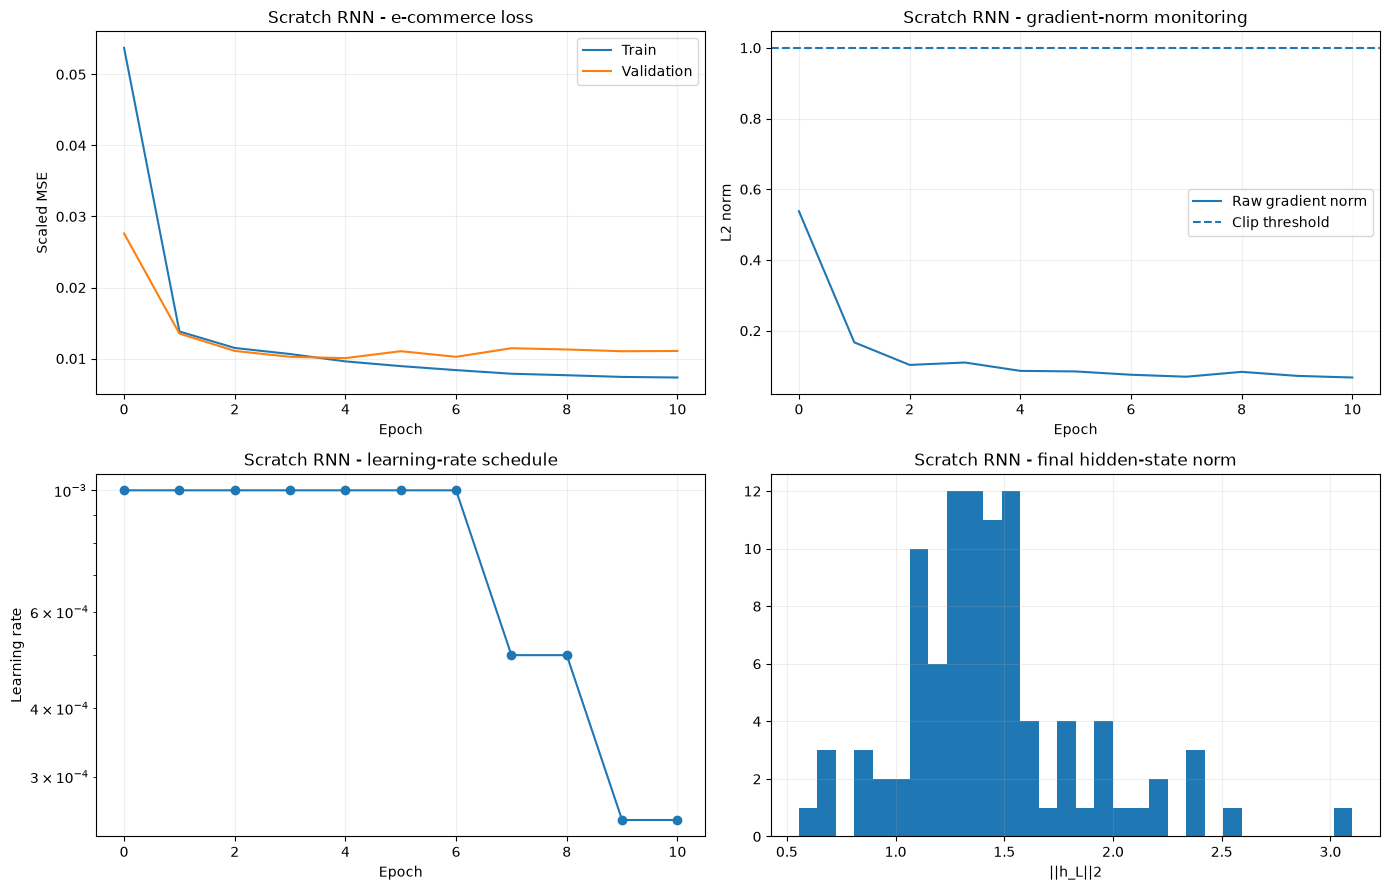

In [24]:
# Purpose: Visualize scratch training dynamics, learning-rate changes, gradients, and hidden-state behavior.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].plot(scratch_ecom_history["train_loss"], label="Train")
axes[0, 0].plot(scratch_ecom_history["val_loss"], label="Validation")
axes[0, 0].set_title("Scratch RNN - e-commerce loss")
axes[0, 0].set_xlabel("Epoch"); axes[0, 0].set_ylabel("Scaled MSE")
axes[0, 0].legend(); axes[0, 0].grid(alpha=0.2)

axes[0, 1].plot(scratch_ecom_history["grad_norm"], label="Raw gradient norm")
axes[0, 1].axhline(GRAD_CLIP_NORM, linestyle="--", label="Clip threshold")
axes[0, 1].set_title("Scratch RNN - gradient-norm monitoring")
axes[0, 1].set_xlabel("Epoch"); axes[0, 1].set_ylabel("L2 norm")
axes[0, 1].legend(); axes[0, 1].grid(alpha=0.2)

axes[1, 0].plot(scratch_ecom_history["lr"], marker="o")
axes[1, 0].set_title("Scratch RNN - learning-rate schedule")
axes[1, 0].set_xlabel("Epoch"); axes[1, 0].set_ylabel("Learning rate")
axes[1, 0].set_yscale("log"); axes[1, 0].grid(alpha=0.2)

scratch_hidden = np.asarray(scratch_ecom_test_cache["hs"][-1])
hidden_norms = np.linalg.norm(scratch_hidden, axis=1)
axes[1, 1].hist(hidden_norms, bins=30)
axes[1, 1].set_title("Scratch RNN - final hidden-state norm")
axes[1, 1].set_xlabel("||h_L||2"); axes[1, 1].grid(alpha=0.2)

plt.tight_layout(); plt.show()


# 16. Keras RNN - implementation and training

Keras provides a higher-level abstraction around the same recurrent computation. The key layer is `tf.keras.layers.SimpleRNN`.

The Keras API expects a three-dimensional input:

```text
(batch, timesteps, features)
```

For this assignment:

$$X \in \mathbb{R}^{B \times 14 \times F}$$

The RNN returns the final hidden representation when `return_sequences=False`, which is exactly what a sequence-to-one regression model needs.

The important conceptual equivalence is:

```text
Scratch: explicit loop over t
Keras:   SimpleRNN layer
```

The computation is still based on the same recurrence relation.


In [25]:
# Purpose: Build and train a Keras SimpleRNN regression model under the shared experiment protocol.
def build_keras_rnn(n_features, hidden_size=HIDDEN_SIZE, dropout=DROPOUT):
    """Construct a sequence-to-one Keras SimpleRNN regressor."""
    if tf is None:
        raise ImportError("TensorFlow is required for the Keras experiment.")
    # The model is explicitly placed on CPU so runtime comparisons are not GPU-dependent.
    with tf.device("/CPU:0"):
        inputs = tf.keras.Input(shape=(LOOKBACK, n_features), name="sequence_input")
        x = tf.keras.layers.SimpleRNN(
            hidden_size,
            activation="tanh",
            use_bias=True,
            return_sequences=False,
            name="rnn",
        )(inputs)
        x = tf.keras.layers.Dropout(dropout, name="dropout")(x)
        outputs = tf.keras.layers.Dense(1, name="regression_head")(x)
        model = tf.keras.Model(inputs, outputs, name="Keras_SimpleRNN_Regressor")
        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=LEARNING_RATE,
                clipnorm=GRAD_CLIP_NORM,
            ),
            loss="mse",
            metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae")],
        )
    return model


def train_keras_rnn(X_train, y_train, X_val, y_val, n_features, artifact_path):
    """Train Keras RNN with the same early-stopping and LR-reduction policy used elsewhere."""
    model = build_keras_rnn(n_features)
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=EARLY_STOPPING_PATIENCE,
            restore_best_weights=True,
            verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=LR_FACTOR,
            patience=LR_PATIENCE,
            min_lr=MIN_LEARNING_RATE,
            verbose=1,
        ),
        tf.keras.callbacks.ModelCheckpoint(
            artifact_path,
            monitor="val_loss",
            save_best_only=True,
            verbose=0,
        ),
    ]
    start = time.perf_counter()
    # Training windows are safe to shuffle because temporal order is preserved inside each window.
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        verbose=1,
        callbacks=callbacks,
    )
    elapsed = time.perf_counter() - start
    return model, history.history, elapsed

KERAS_ECOM_DIR = MODELS_DIR / "ecommerce"
KERAS_ECOM_DIR.mkdir(parents=True, exist_ok=True)
keras_ecom_path = KERAS_ECOM_DIR / "keras_rnn.keras"
keras_ecom_model, keras_ecom_history, keras_ecom_time = train_keras_rnn(
    ecom_train_X,
    ecom_train_y,
    ecom_val_X,
    ecom_val_y,
    ecom_train_X.shape[-1],
    keras_ecom_path,
)
print("Keras e-commerce training time (s):", round(keras_ecom_time, 2))
print("Parameter count:", keras_ecom_model.count_params())


Epoch 1/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - loss: 0.0350 - mae: 0.1409 - val_loss: 0.0226 - val_mae: 0.1173 - learning_rate: 0.0010
Epoch 2/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0130 - mae: 0.0799 - val_loss: 0.0132 - val_mae: 0.0842 - learning_rate: 0.0010
Epoch 3/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0098 - mae: 0.0691 - val_loss: 0.0109 - val_mae: 0.0742 - learning_rate: 0.0010
Epoch 4/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0073 - mae: 0.0555 - val_loss: 0.0096 - val_mae: 0.0686 - learning_rate: 0.0010
Epoch 5/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0061 - mae: 0.0506 - val_loss: 0.0093 - val_mae: 0.0671 - learning_rate: 0.0010
Epoch 6/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0059 - mae: 0.0512 - val_loss: 0.0093 - val_mae: 0.0673 - learning_rate: 0.0010
Epoch 7/40
12/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0053 - mae: 0.0496 
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257

E-commerce Keras test metrics:
{
  "MAE": 12.102605819702148,
  "RMSE": 26.998669626874094,
  "MAPE_percent": 40.49662780761719,
  "R2": -0.13858187198638916
}


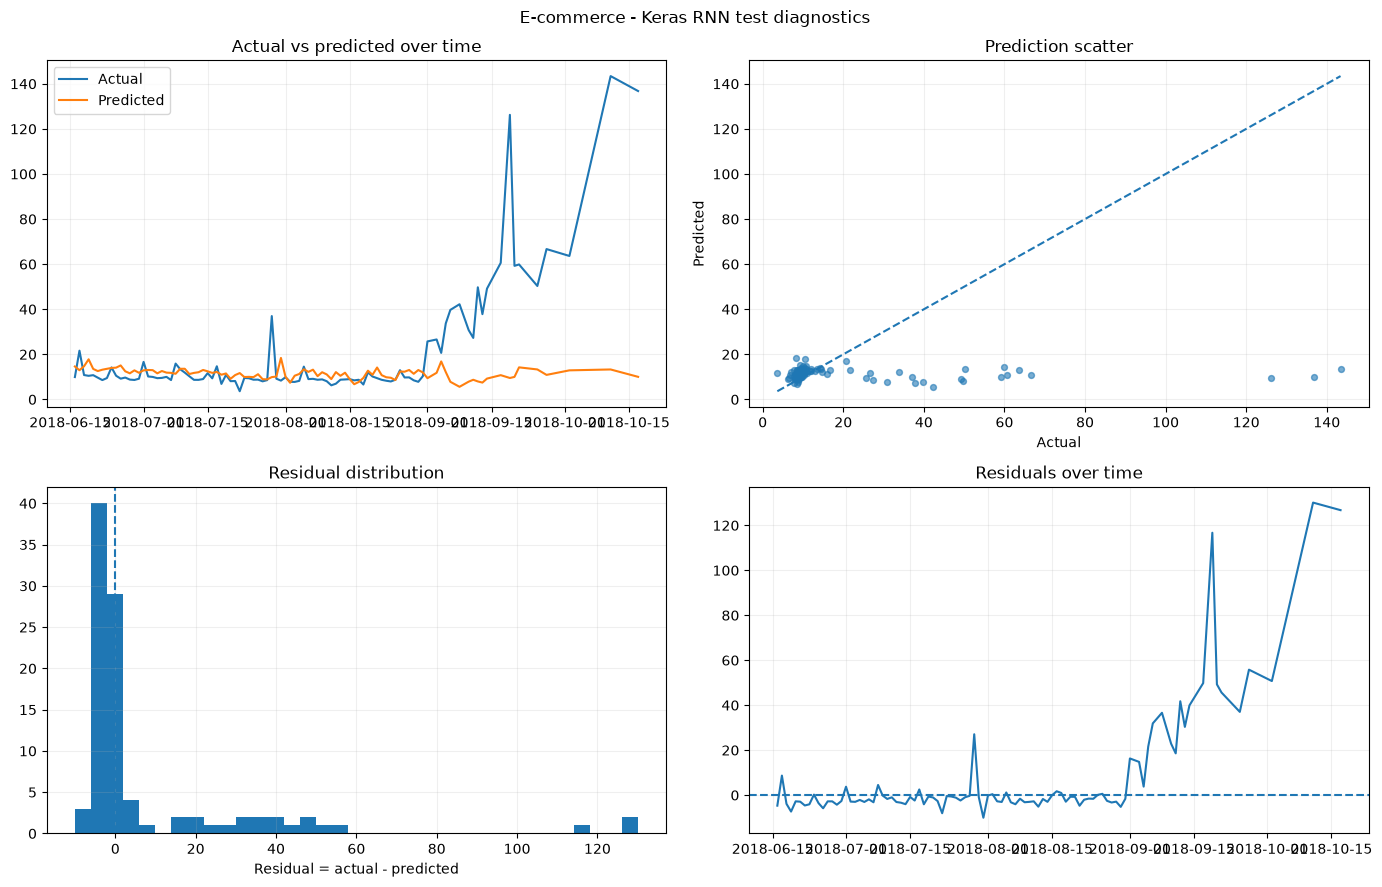

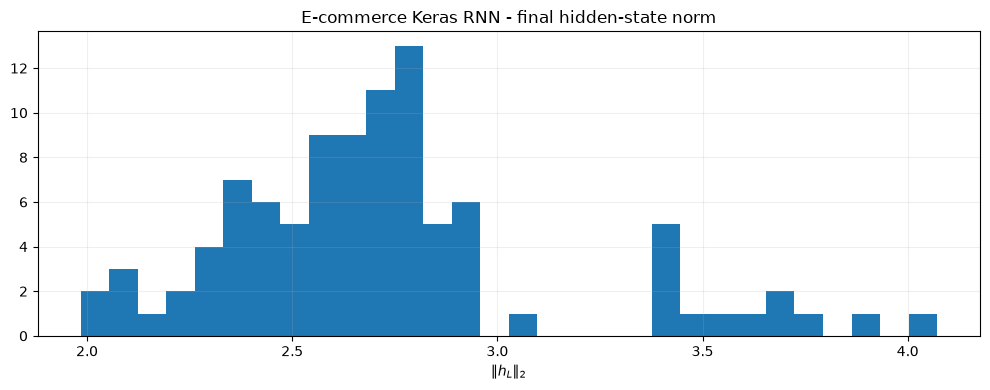

In [26]:
# Purpose: Evaluate Keras predictions in original target units
# and visualize final recurrent-state norms.

keras_ecom_test_scaled = keras_ecom_model.predict(
    ecom_test_X,
    batch_size=BATCH_SIZE,
    verbose=0
).reshape(-1)

keras_ecom_test_pred = inverse_ecommerce_target(ecom_y_scaler, keras_ecom_test_scaled)
keras_ecom_test_true = inverse_ecommerce_target(ecom_y_scaler, ecom_test_y)
keras_ecom_metrics = regression_metrics(
    keras_ecom_test_true,
    keras_ecom_test_pred
)

print("E-commerce Keras test metrics:")
print(json.dumps(keras_ecom_metrics, indent=2))

plot_prediction_diagnostics(
    ecom_test_dates,
    keras_ecom_test_true,
    keras_ecom_test_pred,
    "E-commerce - Keras RNN test diagnostics",
)

# SimpleRNN(return_sequences=False) returns the final state with shape
# (number_of_samples, hidden_size), so there is no time axis to index.
state_model = tf.keras.Model(
    inputs=keras_ecom_model.input,
    outputs=keras_ecom_model.get_layer("rnn").output,
)

keras_ecom_states = state_model.predict(
    ecom_test_X,
    batch_size=BATCH_SIZE,
    verbose=0
)

keras_ecom_hidden_norms = np.linalg.norm(keras_ecom_states, axis=1)

plt.figure(figsize=(10, 4))
plt.hist(keras_ecom_hidden_norms, bins=30)
plt.title("E-commerce Keras RNN - final hidden-state norm")
plt.xlabel(r"$\|h_L\|_2$")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

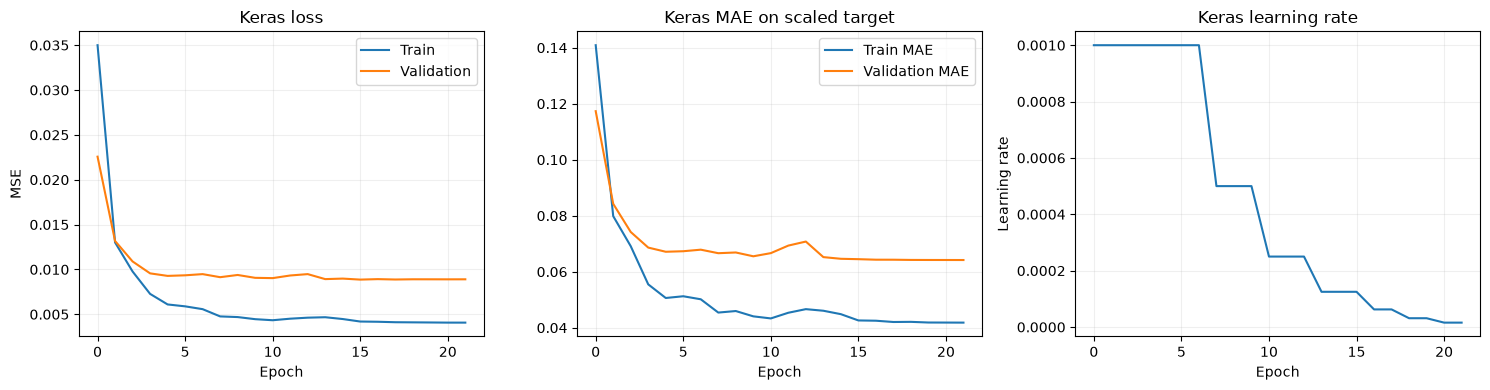

In [27]:
# Purpose: Plot the Keras training curves including learning-rate behavior.
fig, axes = plt.subplots(1, 3, figsize=(15,4))
axes[0].plot(keras_ecom_history["loss"], label="Train")
axes[0].plot(keras_ecom_history["val_loss"], label="Validation")
axes[0].set_title("Keras loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE")
axes[0].legend(); axes[0].grid(alpha=0.2)

axes[1].plot(keras_ecom_history["mae"], label="Train MAE")
axes[1].plot(keras_ecom_history["val_mae"], label="Validation MAE")
axes[1].set_title("Keras MAE on scaled target")
axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=0.2)

axes[2].plot(keras_ecom_history.get("learning_rate", [LEARNING_RATE] * len(keras_ecom_history["loss"])))
axes[2].set_title("Keras learning rate")
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Learning rate"); axes[2].grid(alpha=0.2)
plt.tight_layout(); plt.show()


# 18. PyTorch RNN - implementation and training

PyTorch exposes more of the optimization process explicitly. The recurrent layer is `torch.nn.RNN`, and the assignment uses `batch_first=True` so that the tensor convention is:

$$X \in \mathbb{R}^{B \times L \times F}$$

The training loop explicitly performs:

```text
optimizer.zero_grad()
       ↓
forward pass
       ↓
MSE loss
       ↓
loss.backward()
       ↓
gradient clipping
       ↓
optimizer.step()
```

This is the same conceptual learning cycle used in the scratch implementation, but PyTorch supplies automatic differentiation and optimized tensor kernels.


In [28]:
# Purpose: Implement the PyTorch RNN model and an explicit, inspectable training loop.
class TorchRNNRegressor(torch.nn.Module):
    """Vanilla tanh RNN followed by an optional zero-dropout layer and a linear regression head."""
    def __init__(self, n_features, hidden_size=HIDDEN_SIZE, dropout=DROPOUT):
        super().__init__()
        # nn.RNN implements h_t = tanh(x_t W_ih^T + b_ih + h_{t-1} W_hh^T + b_hh).
        self.rnn = torch.nn.RNN(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=1,
            nonlinearity="tanh",
            bias=True,
            batch_first=True,
        )
        self.dropout = torch.nn.Dropout(dropout)
        self.fc = torch.nn.Linear(hidden_size, 1)

    def forward(self, x):
        # output contains one recurrent representation for every timestep.
        output, hidden = self.rnn(x)
        last_hidden = output[:, -1, :]
        prediction = self.fc(self.dropout(last_hidden))
        return prediction, hidden, output


def train_torch_rnn(X_train, y_train, X_val, y_val, n_features, artifact_path):
    """Train a PyTorch RNN with explicit BPTT, gradient clipping, LR scheduling, and early stopping."""
    # Use CPU for a controlled comparison with NumPy Scratch and the Keras CPU model.
    device = torch.device("cpu")
    model = TorchRNNRegressor(n_features, HIDDEN_SIZE, DROPOUT).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=LR_FACTOR,
        patience=LR_PATIENCE,
        min_lr=MIN_LEARNING_RATE,
    )
    criterion = torch.nn.MSELoss()

    Xtr = torch.tensor(X_train, dtype=torch.float32)
    ytr = torch.tensor(y_train, dtype=torch.float32)
    Xva = torch.tensor(X_val, dtype=torch.float32)
    yva = torch.tensor(y_val, dtype=torch.float32)

    train_loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(Xtr, ytr),
        batch_size=BATCH_SIZE,
        shuffle=True,
    )

    history = {"train_loss": [], "val_loss": [], "lr": [], "epoch_seconds": []}
    best_val = np.inf
    wait = 0
    best_state = None
    start_total = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):
        epoch_start = time.perf_counter()
        model.train()
        train_losses = []

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            # Explicit optimization cycle: clear gradients -> forward -> loss -> backward -> clip -> update.
            optimizer.zero_grad()
            pred, _, _ = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            optimizer.step()
            train_losses.append(loss.item())

        model.eval()
        with torch.no_grad():
            val_pred, _, _ = model(Xva.to(device))
            val_loss = criterion(val_pred, yva.to(device)).item()

        scheduler.step(val_loss)
        lr = optimizer.param_groups[0]["lr"]
        train_loss = float(np.mean(train_losses))
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["lr"].append(lr)
        history["epoch_seconds"].append(time.perf_counter() - epoch_start)

        if val_loss < best_val - 1e-8:
            best_val = val_loss
            wait = 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save({"model_state_dict": best_state}, artifact_path)
        else:
            wait += 1
            if wait >= EARLY_STOPPING_PATIENCE:
                break

    model.load_state_dict(best_state)
    return model, history, time.perf_counter() - start_total, device

TORCH_ECOM_DIR = MODELS_DIR / "ecommerce"
torch_ecom_path = TORCH_ECOM_DIR / "pytorch_rnn.pt"
torch_ecom_model, torch_ecom_history, torch_ecom_time, TORCH_DEVICE = train_torch_rnn(
    ecom_train_X,
    ecom_train_y,
    ecom_val_X,
    ecom_val_y,
    ecom_train_X.shape[-1],
    torch_ecom_path,
)
print("PyTorch device:", TORCH_DEVICE)
print("PyTorch e-commerce training time (s):", round(torch_ecom_time, 2))


PyTorch device: cpu
PyTorch e-commerce training time (s): 1.51


E-commerce PyTorch test metrics:
{
  "MAE": 11.934927940368652,
  "RMSE": 25.24720431421257,
  "MAPE_percent": 49.18069839477539,
  "R2": 0.004351258277893066
}


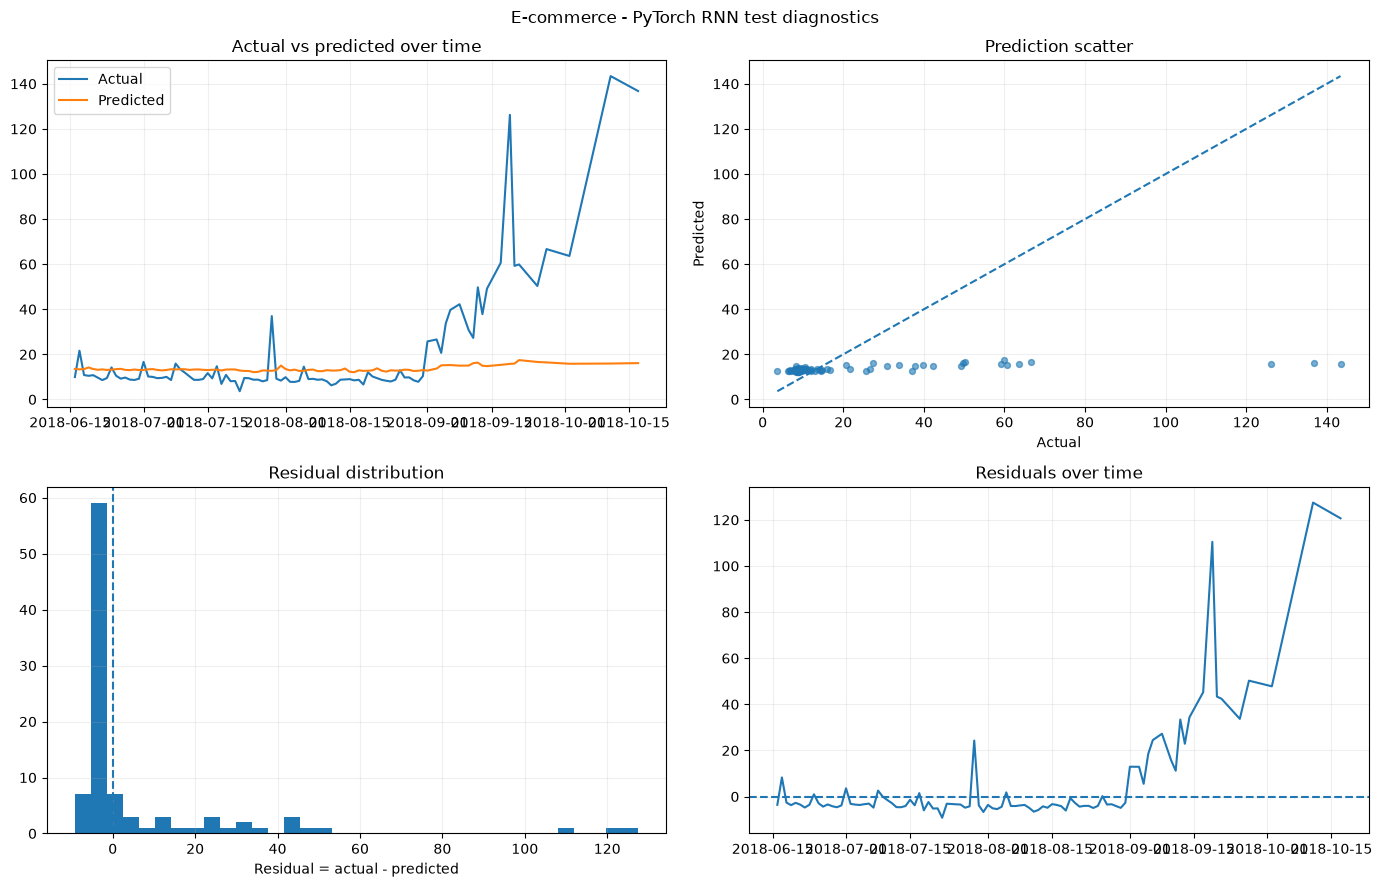

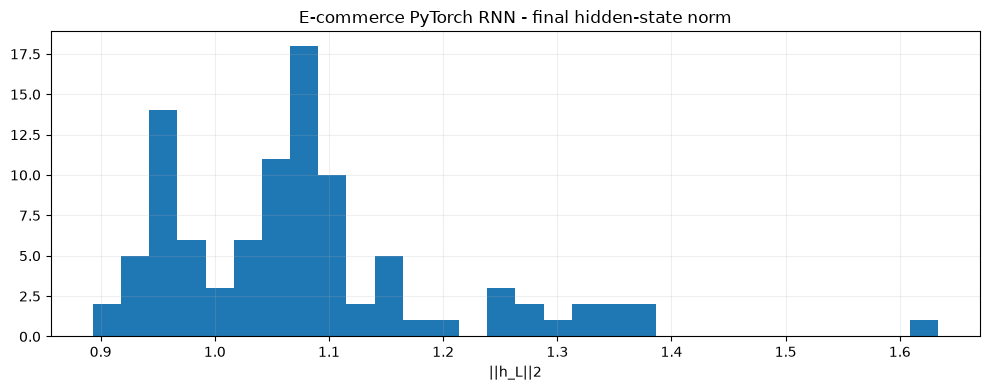

In [29]:
# Purpose: Evaluate the PyTorch e-commerce model and visualize its final hidden-state norms.
torch_ecom_model.eval()
with torch.no_grad():
    pred_t, hidden_t, output_t = torch_ecom_model(torch.tensor(ecom_test_X, dtype=torch.float32, device=TORCH_DEVICE))
torch_ecom_test_scaled = pred_t.detach().cpu().numpy().reshape(-1)
torch_ecom_test_pred = inverse_ecommerce_target(ecom_y_scaler, torch_ecom_test_scaled)
torch_ecom_test_true = inverse_ecommerce_target(ecom_y_scaler, ecom_test_y)
torch_ecom_metrics = regression_metrics(torch_ecom_test_true, torch_ecom_test_pred)

print("E-commerce PyTorch test metrics:")
print(json.dumps(torch_ecom_metrics, indent=2))
plot_prediction_diagnostics(
    ecom_test_dates,
    torch_ecom_test_true,
    torch_ecom_test_pred,
    "E-commerce - PyTorch RNN test diagnostics",
)

torch_ecom_hidden_norms = np.linalg.norm(hidden_t.detach().cpu().numpy()[-1], axis=1)
plt.figure(figsize=(10,4))
plt.hist(torch_ecom_hidden_norms, bins=30)
plt.title("E-commerce PyTorch RNN - final hidden-state norm")
plt.xlabel("||h_L||2"); plt.grid(alpha=0.2); plt.tight_layout(); plt.show()


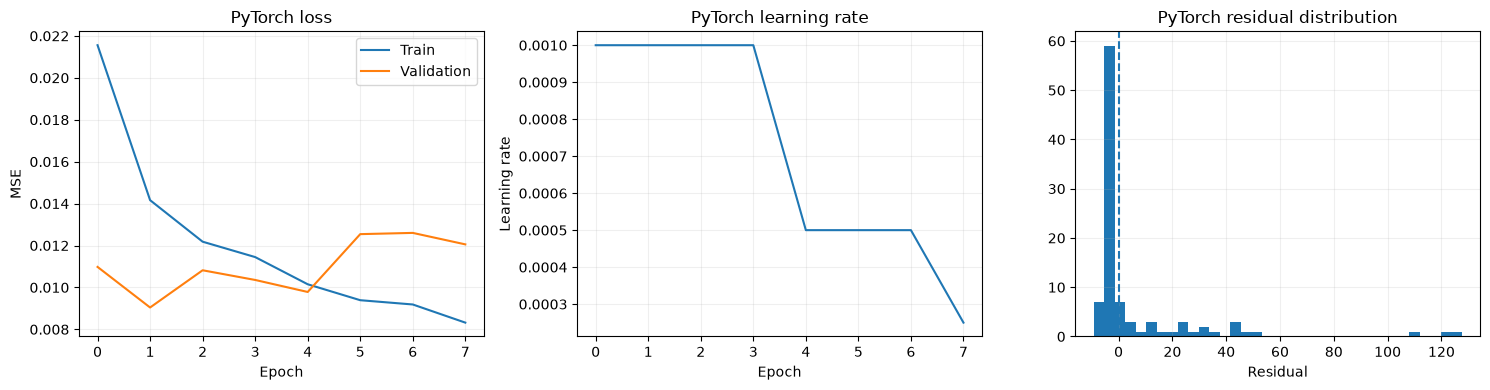

In [30]:
# Purpose: Plot PyTorch training curves and summarize the explicit optimization process.
fig, axes = plt.subplots(1, 3, figsize=(15,4))
axes[0].plot(torch_ecom_history["train_loss"], label="Train")
axes[0].plot(torch_ecom_history["val_loss"], label="Validation")
axes[0].set_title("PyTorch loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE")
axes[0].legend(); axes[0].grid(alpha=0.2)

axes[1].plot(torch_ecom_history["lr"])
axes[1].set_title("PyTorch learning rate")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Learning rate"); axes[1].grid(alpha=0.2)

axes[2].hist(torch_ecom_test_true - torch_ecom_test_pred, bins=35)
axes[2].axvline(0, linestyle="--")
axes[2].set_title("PyTorch residual distribution")
axes[2].set_xlabel("Residual"); axes[2].grid(alpha=0.2)
plt.tight_layout(); plt.show()


### Persistence baseline

Before interpreting the neural-network results, a simple persistence forecast is evaluated. For each test target, the baseline repeats the immediately previous observed service-day target. This provides a minimum reference for the forecasting problem.

E-commerce persistence baseline:
{
  "MAE": 5.937878608703613,
  "RMSE": 14.176669250913795,
  "MAPE_percent": 25.840547561645508,
  "R2": 0.6860735416412354
}


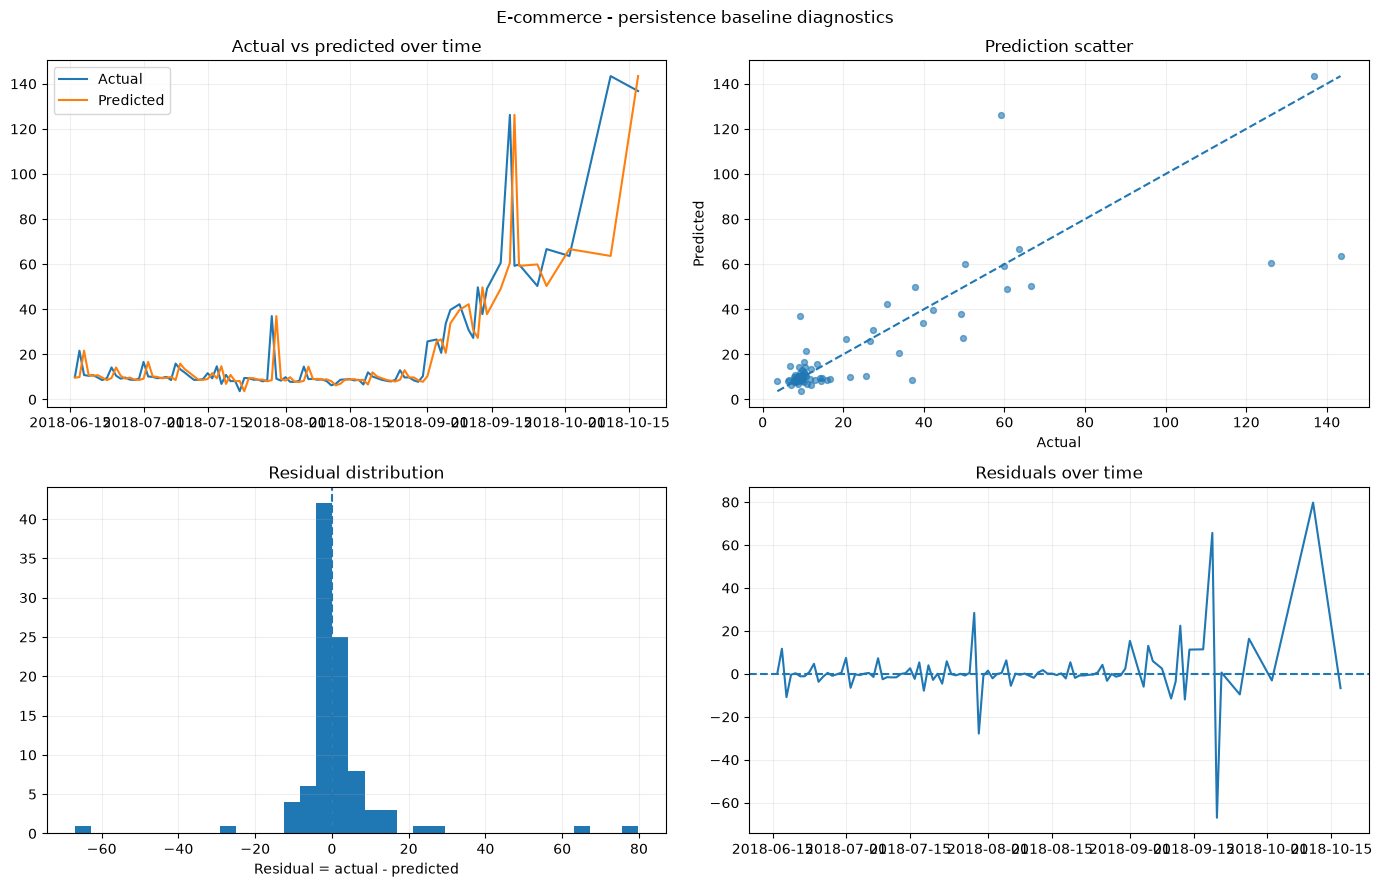

,framework,MAE,RMSE,MAE_improvement_vs_persistence_%,RMSE_improvement_vs_persistence_%
0,Persistence,5.9379,14.1767,0.00,0.00
1,Scratch,12.4748,26.5686,-110.09,-87.41
2,Keras,12.1026,26.9987,-103.82,-90.44
3,PyTorch,11.9349,25.2472,-101.00,-78.09


,framework,median_abs_error,p90_abs_error,p95_abs_error
0,Persistence,1.5755,11.7943,23.5105
1,Scratch,4.2972,36.7368,50.1424
2,Keras,3.0117,38.1703,49.9964
3,PyTorch,4.1751,33.5178,45.7552


In [31]:
# Purpose: Evaluate the e-commerce persistence baseline and compare errors.

ecom_previous_target = ecom_y_raw[ecom_test_idx - 1].reshape(-1)
ecom_persistence_metrics = regression_metrics(
    scratch_ecom_test_true,
    ecom_previous_target
)

print("E-commerce persistence baseline:")
print(json.dumps(ecom_persistence_metrics, indent=2))

plot_prediction_diagnostics(
    ecom_test_dates,
    scratch_ecom_test_true,
    ecom_previous_target,
    "E-commerce - persistence baseline diagnostics"
)

# Build the comparison table here so this cell does not depend on
# ecom_results having been created by another cell.
ecom_results = pd.DataFrame([
    {"framework": "Persistence", **ecom_persistence_metrics},
    {"framework": "Scratch", **scratch_ecom_metrics},
    {"framework": "Keras", **keras_ecom_metrics},
    {"framework": "PyTorch", **torch_ecom_metrics},
])

def add_baseline_improvement(results_df):
    """Add relative MAE/RMSE change versus the Persistence row."""
    baseline_rows = results_df.loc[results_df["framework"].eq("Persistence")]
    if baseline_rows.empty:
        raise ValueError("ecom_results must include a Persistence baseline row.")

    baseline = baseline_rows.iloc[0]
    out = results_df.copy()
    out["MAE_improvement_vs_persistence_%"] = (
        1 - out["MAE"] / baseline["MAE"]
    ) * 100
    out["RMSE_improvement_vs_persistence_%"] = (
        1 - out["RMSE"] / baseline["RMSE"]
    ) * 100
    return out

ecom_results = add_baseline_improvement(ecom_results)

display(
    ecom_results[
        [
            "framework",
            "MAE",
            "RMSE",
            "MAE_improvement_vs_persistence_%",
            "RMSE_improvement_vs_persistence_%",
        ]
    ].style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "MAE_improvement_vs_persistence_%": "{:.2f}",
        "RMSE_improvement_vs_persistence_%": "{:.2f}",
    })
)

# Error quantiles summarize the tail of each model's absolute-error distribution.
ecom_error_quantiles = pd.DataFrame([
    {
        "framework": name,
        "median_abs_error": float(np.median(np.abs(true - pred))),
        "p90_abs_error": float(np.quantile(np.abs(true - pred), 0.90)),
        "p95_abs_error": float(np.quantile(np.abs(true - pred), 0.95)),
    }
    for name, true, pred in [
        ("Persistence", scratch_ecom_test_true, ecom_previous_target),
        ("Scratch", scratch_ecom_test_true, scratch_ecom_test_pred),
        ("Keras", keras_ecom_test_true, keras_ecom_test_pred),
        ("PyTorch", torch_ecom_test_true, torch_ecom_test_pred),
    ]
])

display(
    ecom_error_quantiles.style.format({
        "median_abs_error": "{:.4f}",
        "p90_abs_error": "{:.4f}",
        "p95_abs_error": "{:.4f}",
    })
)

## 20. E-commerce experiment comparison

The first dataset has now been implemented at three levels:

| Implementation | Gradient computation | Training loop | RNN operation |
|---|---|---|---|
| Scratch | manual BPTT | manual | manual NumPy operators |
| Keras | automatic differentiation | `fit()` | `SimpleRNN` |
| PyTorch | automatic differentiation | explicit loop | `nn.RNN` |

The evaluation must be based on the same held-out test targets and the same original-unit metrics.


,dataset,framework,model,parameters,training_time_s,MAE,RMSE,MAPE_percent,R2
0,E-commerce service process,Persistence,Last-value baseline,0,0.00,5.9379,14.1767,25.84,0.6861
1,E-commerce service process,Scratch,Vanilla RNN,"4,673",0.29,12.4748,26.5686,47.32,-0.1026
2,E-commerce service process,Keras,SimpleRNN,"4,673",9.73,12.1026,26.9987,40.50,-0.1386
3,E-commerce service process,PyTorch,nn.RNN,"4,737",1.51,11.9349,25.2472,49.18,0.0044


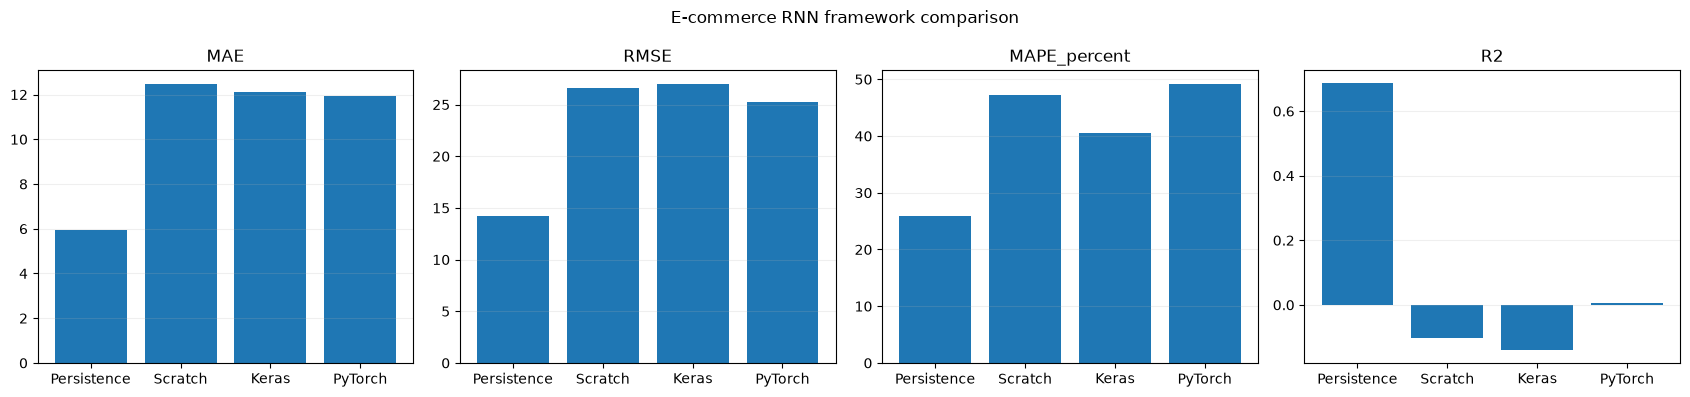

In [32]:
# Purpose: Assemble the e-commerce results into one comparable table.
ecom_results = pd.DataFrame([
    {
        "dataset": "E-commerce service process",
        "framework": "Persistence",
        "model": "Last-value baseline",
        "parameters": 0,
        "training_time_s": 0.0,
        **ecom_persistence_metrics,
    },
    {
        "dataset": "E-commerce service process",
        "framework": "Scratch",
        "model": "Vanilla RNN",
        "parameters": scratch_parameter_count(scratch_ecom_params),
        "training_time_s": scratch_ecom_time,
        **scratch_ecom_metrics,
    },
    {
        "dataset": "E-commerce service process",
        "framework": "Keras",
        "model": "SimpleRNN",
        "parameters": keras_ecom_model.count_params(),
        "training_time_s": keras_ecom_time,
        **keras_ecom_metrics,
    },
    {
        "dataset": "E-commerce service process",
        "framework": "PyTorch",
        "model": "nn.RNN",
        "parameters": sum(p.numel() for p in torch_ecom_model.parameters()),
        "training_time_s": torch_ecom_time,
        **torch_ecom_metrics,
    },
])
display(ecom_results.style.format({"MAE":"{:.4f}", "RMSE":"{:.4f}", "MAPE_percent":"{:.2f}", "R2":"{:.4f}", "training_time_s":"{:.2f}", "parameters":"{:,}"}))

fig, axes = plt.subplots(1, 4, figsize=(17,4))
for ax, metric in zip(axes, ["MAE", "RMSE", "MAPE_percent", "R2"]):
    ax.bar(ecom_results["framework"], ecom_results[metric])
    ax.set_title(metric)
    ax.grid(axis="y", alpha=0.2)
plt.suptitle("E-commerce RNN framework comparison")
plt.tight_layout(); plt.show()


# Part C - Dataset 2: Stock market

## 21. Stock data acquisition and audit

The stock experiment uses historical daily data for AAPL. The notebook first checks for a cached CSV. If it does not exist, `yfinance.download()` retrieves the fixed historical period and writes the result locally.

Using a fixed download interval and date range makes the experiment reproducible and prevents the test set from changing merely because the notebook was executed on a later date.


In [33]:
# Purpose: Download and cache reproducible AAPL daily market data.

try:
    import yfinance as yf
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "yfinance"
    ])
    import yfinance as yf

STOCK_DIR = DATA_DIR / "stock"
STOCK_DIR.mkdir(parents=True, exist_ok=True)
STOCK_FILE = STOCK_DIR / "AAPL_daily.csv"

STOCK_TICKER = "AAPL"
STOCK_START = "2010-01-01"
STOCK_END = "2026-01-01"  # exclusive; includes observations through 2025-12-31

if STOCK_FILE.exists():
    aapl = pd.read_csv(STOCK_FILE, parse_dates=["Date"])
else:
    raw = yf.download(
        STOCK_TICKER,
        start=STOCK_START,
        end=STOCK_END,
        interval="1d",
        auto_adjust=True,
        progress=False,
        group_by="column",
        multi_level_index=False,
    )

    if raw is None or raw.empty:
        raise RuntimeError(
            "AAPL download returned no rows. Download the fixed period manually "
            "and place it at data/stock/AAPL_daily.csv."
        )

    raw = raw.reset_index()

    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = [
            column[0] if isinstance(column, tuple) else column
            for column in raw.columns
        ]

    raw.to_csv(STOCK_FILE, index=False)
    aapl = raw.copy()

aapl["Date"] = pd.to_datetime(aapl["Date"], errors="coerce")

print("Shape:", aapl.shape)
print("Date range:", aapl["Date"].min(), "to", aapl["Date"].max())
print("Missing values:")
display(aapl.isna().sum().to_frame("missing"))
display(aapl.head())
display(aapl.describe().T)

Shape: (4024, 6)
Date range: 2010-01-04 00:00:00 to 2025-12-31 00:00:00
Missing values:


,missing
Date,0
Close,0
High,0
Low,0
Open,0
Volume,0


,Date,Close,High,Low,Open,Volume
0,2010-01-04,6.400959,6.415615,6.352207,6.383612,493729600
1,2010-01-05,6.412027,6.448218,6.378229,6.418608,601904800
2,2010-01-06,6.310034,6.437449,6.303454,6.412026,552160000
3,2010-01-07,6.298370,6.340842,6.252608,6.333365,477131200
4,2010-01-08,6.340243,6.340841,6.252908,6.289995,447610800


,count,mean,min,25%,50%,75%,max,std
Date,4024,2017-12-30 13:02:58.926441,2010-01-04 00:00:00,2014-01-01 12:00:00,2017-12-28 12:00:00,2021-12-28 06:00:00,2025-12-31 00:00:00,NaN
Close,4024.0,77.300371,5.744145,18.178106,38.77692,142.543789,285.413116,74.826808
High,4024.0,78.064661,5.862287,18.371388,39.218558,144.076107,287.836529,75.550358
Low,4024.0,76.46342,5.690306,18.02706,38.254175,140.859095,282.530963,74.023624
Open,4024.0,77.235968,5.753715,18.197687,38.735394,142.398268,285.423116,74.746466
Volume,4024.0,219000647.067594,17910600.0,77659100.0,130782200.0,289999500.0,1880998000.0,215486024.775084


Duplicate dates: 0
Negative/zero close: 0


,column,dtype,missing,unique
0,Date,datetime64[us],0,4024
1,Close,float64,0,3968
2,High,float64,0,4024
3,Low,float64,0,4024
4,Open,float64,0,4024
5,Volume,int64,0,4015


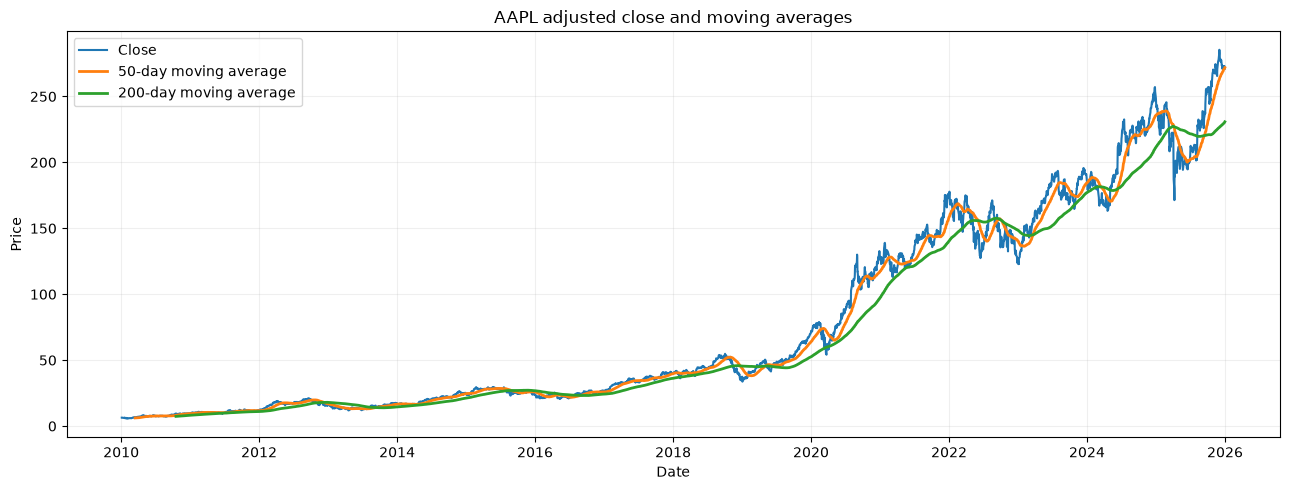

In [34]:
# Purpose: Check price continuity, duplicate dates, and raw trading-day behavior.
aapl_audit = pd.DataFrame({
    "column": aapl.columns,
    "dtype": [str(aapl[c].dtype) for c in aapl.columns],
    "missing": [int(aapl[c].isna().sum()) for c in aapl.columns],
    "unique": [int(aapl[c].nunique(dropna=True)) for c in aapl.columns],
})
print("Duplicate dates:", int(aapl["Date"].duplicated().sum()))
print("Negative/zero close:", int((aapl["Close"] <= 0).sum()))
display(aapl_audit)

plt.figure(figsize=(13,5))
plt.plot(aapl["Date"], aapl["Close"], label="Close")
plt.plot(aapl["Date"], aapl["Close"].rolling(50).mean(), label="50-day moving average", linewidth=2)
plt.plot(aapl["Date"], aapl["Close"].rolling(200).mean(), label="200-day moving average", linewidth=2)
plt.title("AAPL adjusted close and moving averages")
plt.xlabel("Date"); plt.ylabel("Price")
plt.legend(); plt.grid(alpha=0.2); plt.tight_layout(); plt.show()


## 22. Feature engineering and target construction

The target is the next trading day's closing price.

Additional derived features are included so that the RNN can observe short-term market dynamics rather than only the raw price level:

- `Return_1d`: daily percentage return;
- `HL_range_pct`: intraday high-low range relative to close;
- `OC_change_pct`: open-to-close percentage change;
- `Volume_change_pct`: one-day relative change in trading volume.

The aligned supervised problem is:

```text
Features at day t
        ↓
14-day lookback window
        ↓
RNN
        ↓
Predicted close at day t+1
```

### Important interpretation

Stock-price forecasting is used here as a **technical time-series learning exercise**, not as a trading strategy. A good regression fit on historical observations does not imply that a model can reliably produce economic profit in live markets.


In [35]:
# Purpose: Engineer numerical market features and align them to a one-step-ahead target.
stock = aapl.sort_values("Date").drop_duplicates("Date").copy()
stock["Return_1d"] = stock["Close"].pct_change()
stock["HL_range_pct"] = (stock["High"] - stock["Low"]) / stock["Close"].replace(0, np.nan)
stock["OC_change_pct"] = (stock["Close"] - stock["Open"]) / stock["Open"].replace(0, np.nan)
stock["Volume_change_pct"] = stock["Volume"].pct_change()
stock = stock.dropna().reset_index(drop=True)

stock_feature_cols = [
    "Open", "High", "Low", "Close", "Volume",
    "Return_1d", "HL_range_pct", "OC_change_pct", "Volume_change_pct"
]
stock_target_col = "Close"

stock_X_raw = stock[stock_feature_cols].to_numpy(dtype=np.float32)[:-1]
stock_y_raw = stock[[stock_target_col]].to_numpy(dtype=np.float32)[1:]
stock_target_dates = stock["Date"].to_numpy()[1:]

print("Feature matrix:", stock_X_raw.shape)
print("Target vector:", stock_y_raw.shape)
print("Target period:", stock_target_dates[0], "to", stock_target_dates[-1])


Feature matrix: (4022, 9)
Target vector: (4022, 1)
Target period: 2010-01-06T00:00:00.000000 to 2025-12-31T00:00:00.000000


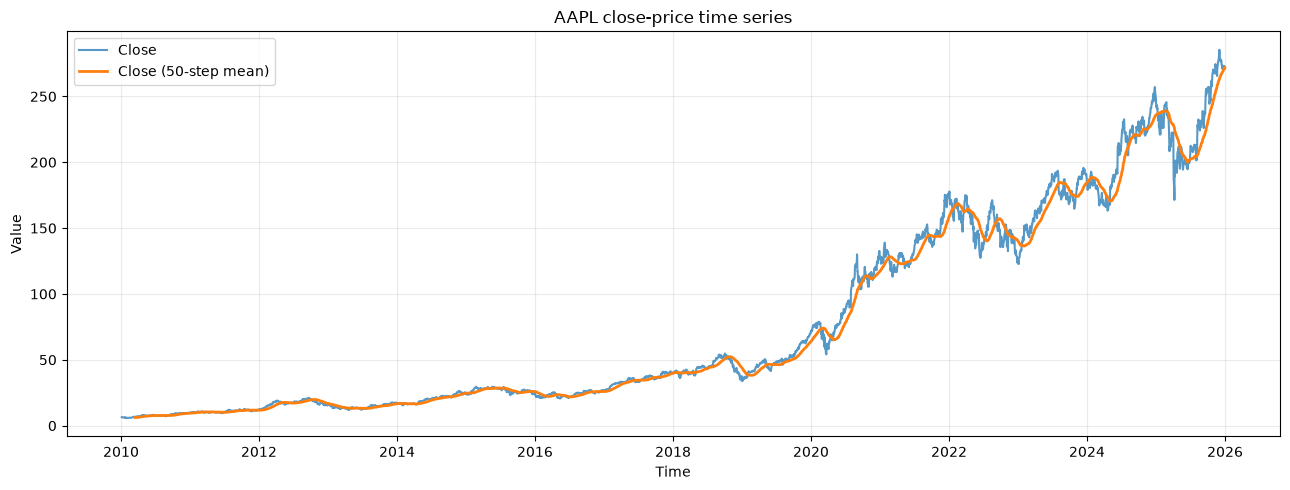

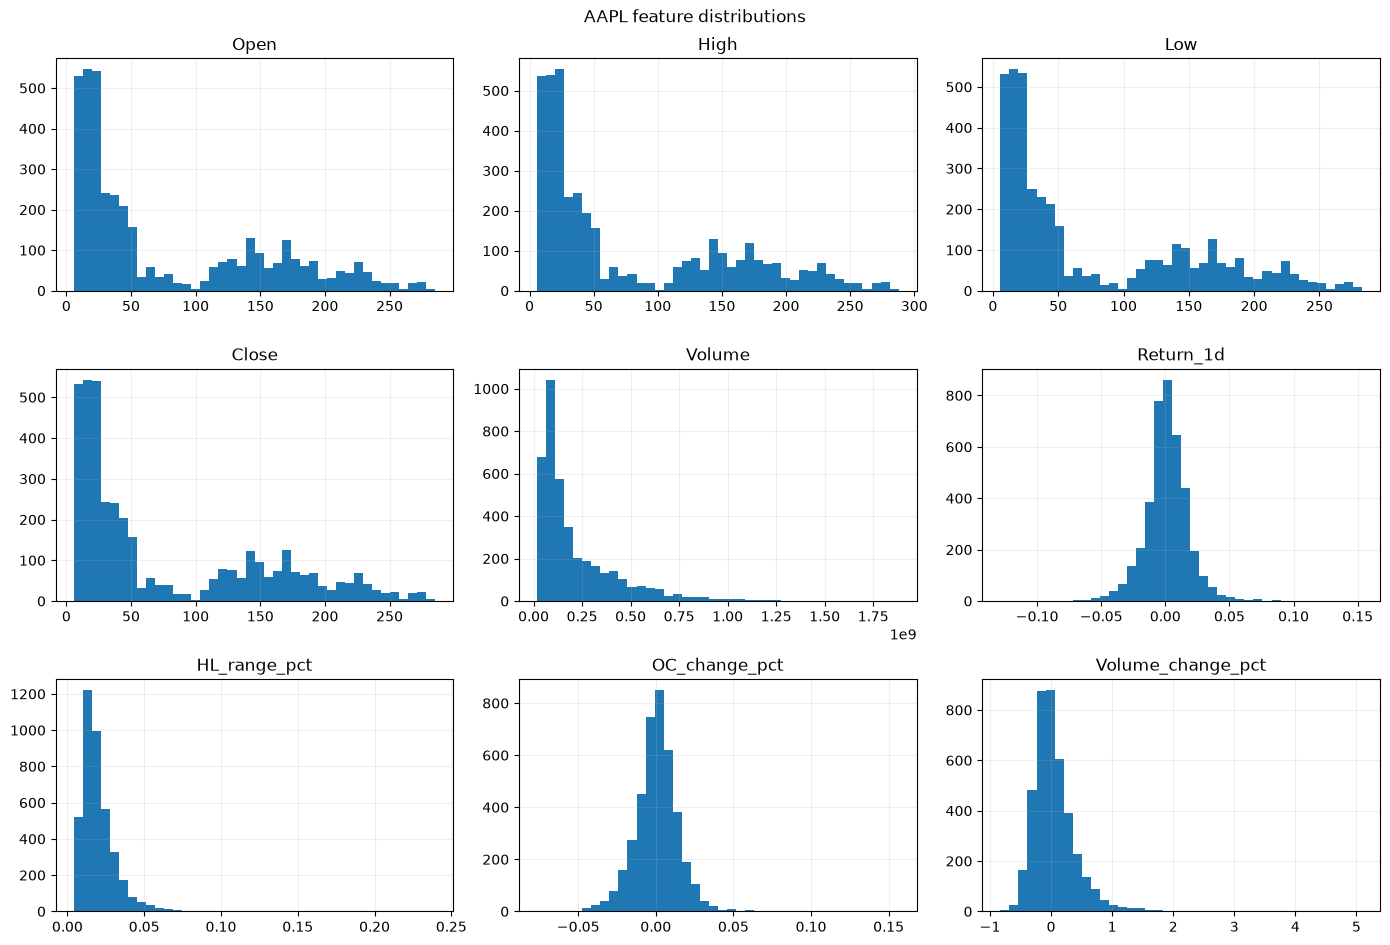

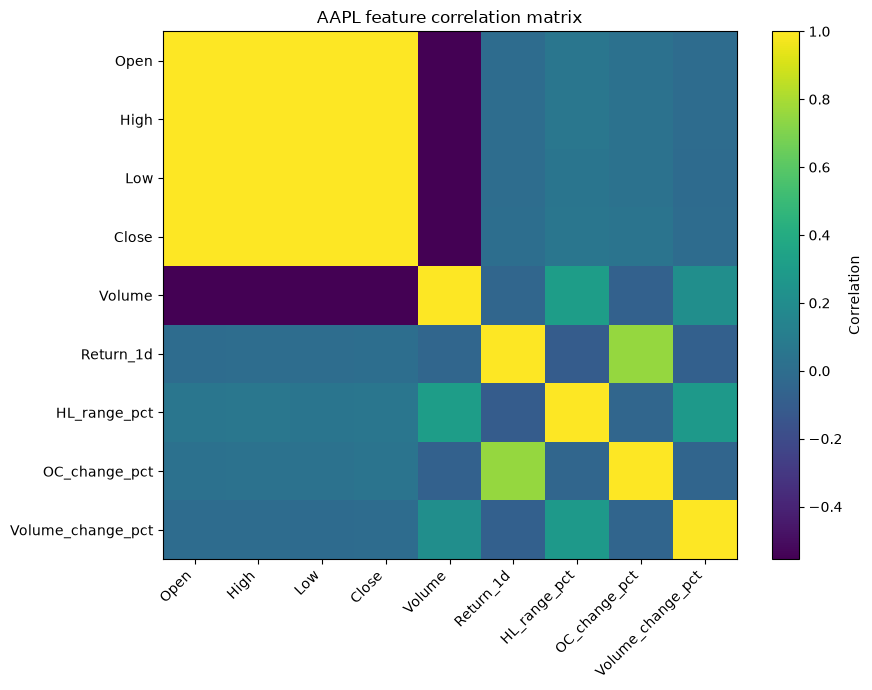

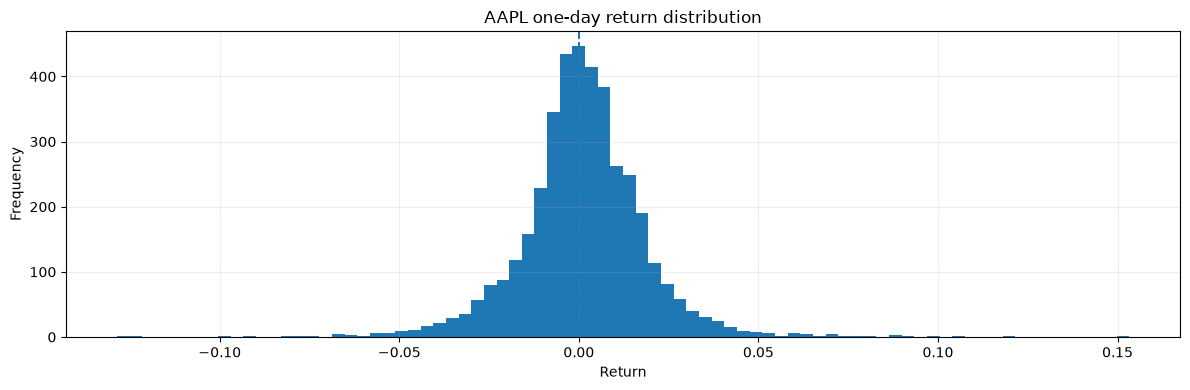

In [36]:
# Purpose: Visualize market features, distributions, correlations, and return behavior.
plot_time_series(stock, "Date", ["Close"], "AAPL close-price time series", rolling=50)
plot_feature_distributions(stock, stock_feature_cols, "AAPL feature distributions")
plot_correlation_heatmap(stock, stock_feature_cols, "AAPL feature correlation matrix")

plt.figure(figsize=(12,4))
plt.hist(stock["Return_1d"], bins=80)
plt.axvline(0, linestyle="--")
plt.title("AAPL one-day return distribution")
plt.xlabel("Return")
plt.ylabel("Frequency")
plt.grid(alpha=0.2); plt.tight_layout(); plt.show()


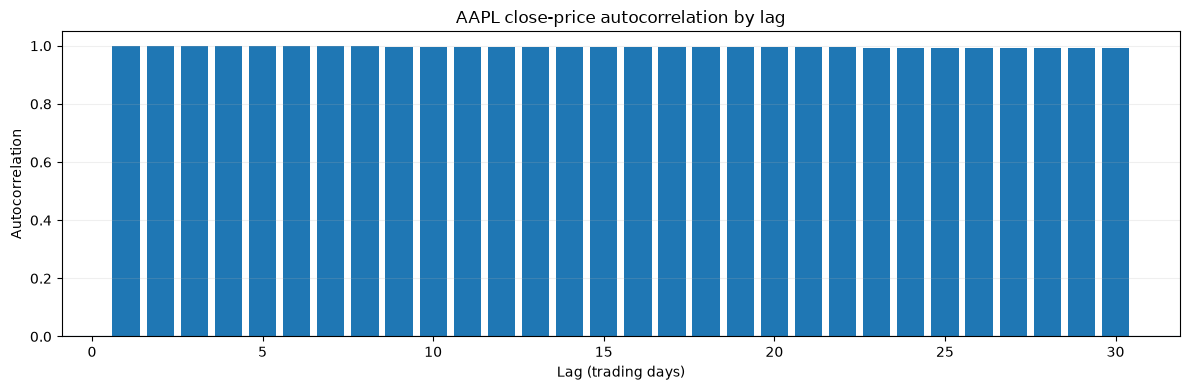

In [37]:
# Purpose: Inspect short-range temporal dependence through lag correlations of the closing price.
close_series = stock["Close"]
lag_values = [close_series.autocorr(lag) for lag in range(1, 31)]
plt.figure(figsize=(12,4))
plt.bar(range(1,31), lag_values)
plt.title("AAPL close-price autocorrelation by lag")
plt.xlabel("Lag (trading days)"); plt.ylabel("Autocorrelation")
plt.axhline(0, linewidth=0.8); plt.grid(axis="y", alpha=0.2)
plt.tight_layout(); plt.show()


## 23. Exploratory time-series interpretation

The stock series demonstrates several properties that are useful for understanding recurrent models:

- price levels are highly persistent over short horizons;
- returns fluctuate around a comparatively small scale;
- volatility is not constant across the full historical period;
- trading volume is on a very different numerical scale from price and percentage features.

This reinforces two modeling decisions:

1. the network should receive a **window of ordered observations**, not shuffled rows;
2. feature scaling should be fit using the training partition only.


## 23.1 Additional market-risk diagnostics

The close-price level is persistent, but forecasting difficulty is also affected by volatility and drawdowns. The following diagnostics visualize:

- rolling return volatility;
- cumulative drawdown from the running historical maximum;
- the distribution of returns.

These plots are descriptive. They do not imply that the RNN can explain every market movement.

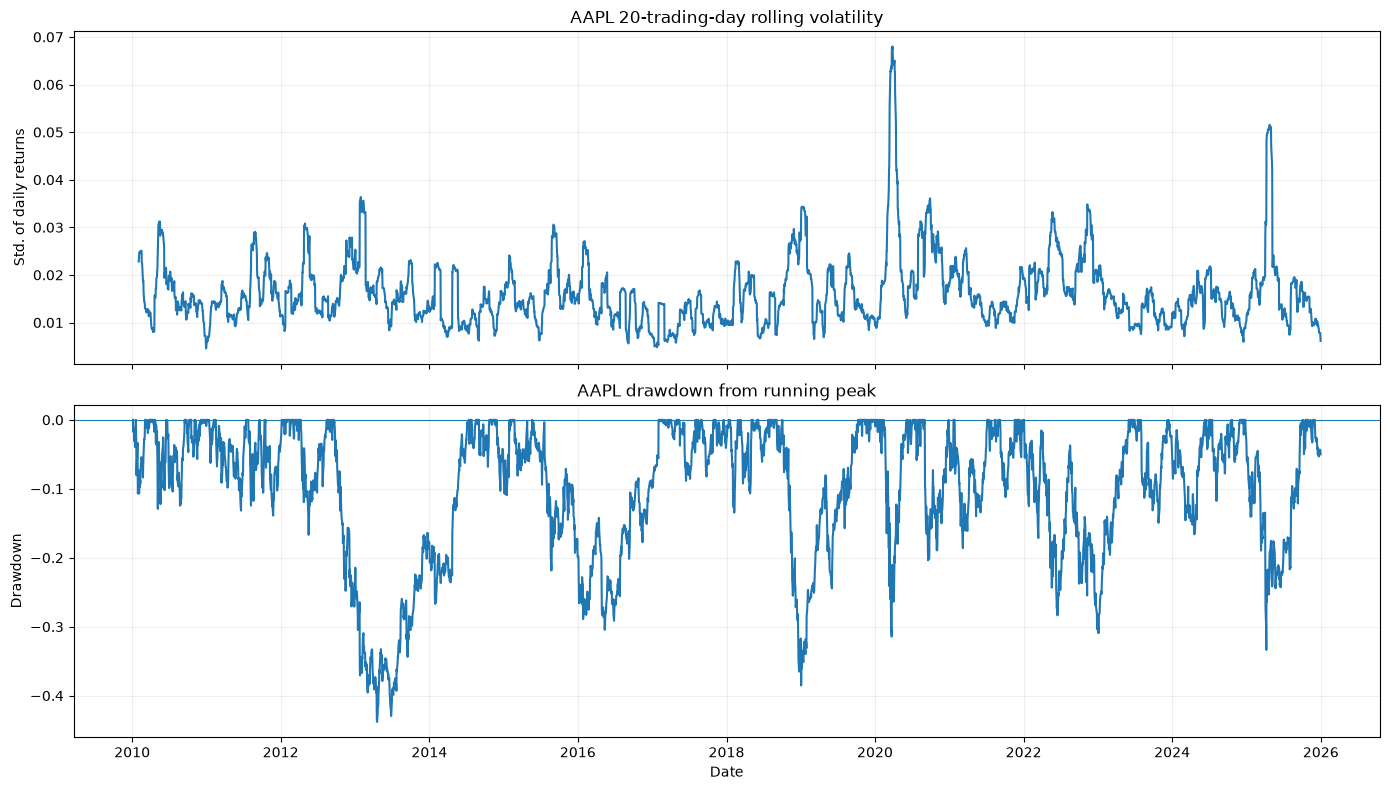

In [38]:
# Purpose: Visualize changing volatility and drawdown regimes in the stock series.
stock_plot = stock.copy()
stock_plot["rolling_volatility_20d"] = stock_plot["Return_1d"].rolling(20).std()
rolling_peak = stock_plot["Close"].cummax()
stock_plot["drawdown"] = stock_plot["Close"] / rolling_peak - 1.0

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(stock_plot["Date"], stock_plot["rolling_volatility_20d"])
axes[0].set_title("AAPL 20-trading-day rolling volatility")
axes[0].set_ylabel("Std. of daily returns")
axes[0].grid(alpha=0.2)

axes[1].plot(stock_plot["Date"], stock_plot["drawdown"])
axes[1].axhline(0, linewidth=0.8)
axes[1].set_title("AAPL drawdown from running peak")
axes[1].set_ylabel("Drawdown")
axes[1].set_xlabel("Date")
axes[1].grid(alpha=0.2)
plt.tight_layout(); plt.show()


## 24. Train / validation / test split and scaling

The split and window construction use the exact same logic as the e-commerce experiment. This provides a controlled cross-dataset comparison.


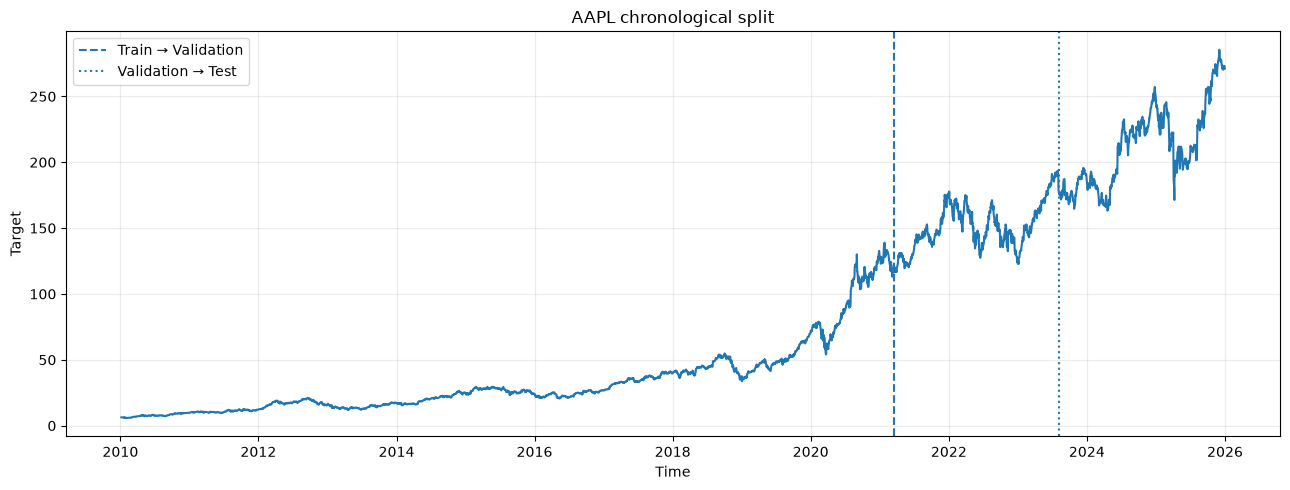

Train: (2801, 14, 9) (2801, 1)
Validation: (603, 14, 9) (603, 1)
Test: (604, 14, 9) (604, 1)


In [39]:
# Purpose: Create chronological stock partitions and train-only scalers.
stock_train_end, stock_val_end = chronological_split_indices(len(stock_X_raw))
stock_x_scaler, stock_y_scaler = fit_scalers(stock_X_raw, stock_y_raw, stock_train_end)
stock_X_scaled = stock_x_scaler.transform(stock_X_raw).astype(np.float32)
stock_y_scaled = stock_y_scaler.transform(stock_y_raw).astype(np.float32)

plot_split_boundaries(
    pd.Series(stock_target_dates), stock_y_raw.reshape(-1),
    stock_train_end, stock_val_end,
    "AAPL chronological split"
)

stock_train_X, stock_train_y, stock_train_dates, stock_train_idx = make_windows(
    stock_X_scaled, stock_y_scaled, stock_target_dates, LOOKBACK, 0, stock_train_end
)
stock_val_X, stock_val_y, stock_val_dates, stock_val_idx = make_windows(
    stock_X_scaled, stock_y_scaled, stock_target_dates, LOOKBACK, stock_train_end, stock_val_end
)
stock_test_X, stock_test_y, stock_test_dates, stock_test_idx = make_windows(
    stock_X_scaled, stock_y_scaled, stock_target_dates, LOOKBACK, stock_val_end, len(stock_X_scaled)
)

print("Train:", stock_train_X.shape, stock_train_y.shape)
print("Validation:", stock_val_X.shape, stock_val_y.shape)
print("Test:", stock_test_X.shape, stock_test_y.shape)


,Open,High,Low,Close,Volume,Return_1d,HL_range_pct,OC_change_pct,Volume_change_pct
2010-01-13,0.004,0.003,0.004,0.004,0.299,0.472,0.051,0.411,0.172
2010-01-14,0.003,0.003,0.003,0.004,0.305,0.575,0.120,0.539,0.126
2010-01-15,0.004,0.003,0.004,0.004,0.211,0.494,0.012,0.435,0.074
2010-01-19,0.004,0.003,0.004,0.003,0.299,0.451,0.101,0.306,0.187
2010-01-20,0.004,0.004,0.004,0.005,0.373,0.696,0.139,0.657,0.162
2010-01-21,0.005,0.004,0.004,0.004,0.309,0.456,0.104,0.362,0.095
2010-01-22,0.004,0.004,0.004,0.004,0.307,0.448,0.107,0.336,0.122
2010-01-25,0.003,0.003,0.002,0.001,0.456,0.318,0.204,0.181,0.200
2010-01-26,0.002,0.002,0.002,0.002,0.556,0.626,0.077,0.472,0.159
2010-01-27,0.003,0.004,0.003,0.003,0.992,0.575,0.212,0.455,0.252


Target date: 2010-02-03 00:00:00


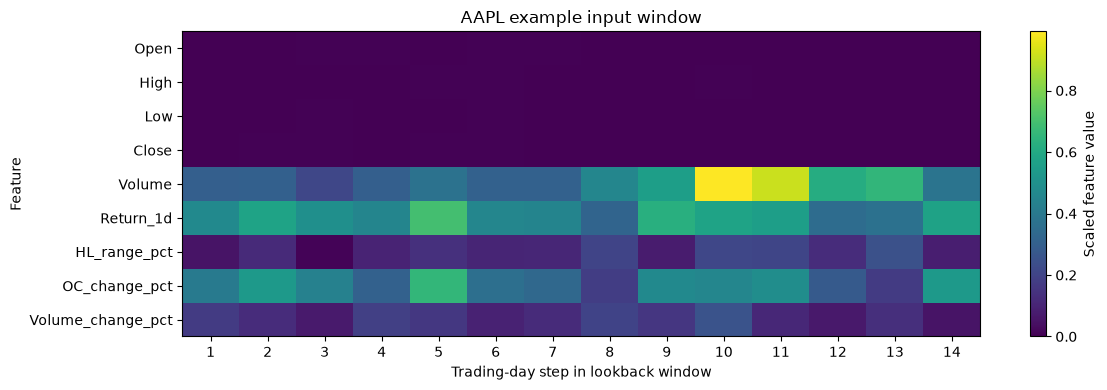

In [40]:
# Purpose: Show one concrete 14-step stock window used by the RNN.
idx = min(5, len(stock_train_X)-1)
window_dates = pd.to_datetime(stock_target_dates[stock_train_idx[idx]-LOOKBACK:stock_train_idx[idx]])
window_df = pd.DataFrame(stock_train_X[idx], columns=stock_feature_cols, index=window_dates)
display(window_df.round(3))
print("Target date:", pd.to_datetime(stock_train_dates[idx]))


# Purpose: Visualize the normalized stock window as a compact feature-time matrix.
plt.figure(figsize=(12, 4))
plt.imshow(stock_train_X[idx].T, aspect="auto", interpolation="nearest")
plt.colorbar(label="Scaled feature value")
plt.xticks(range(LOOKBACK), [str(i+1) for i in range(LOOKBACK)])
plt.yticks(range(len(stock_feature_cols)), stock_feature_cols)
plt.xlabel("Trading-day step in lookback window")
plt.ylabel("Feature")
plt.title("AAPL example input window")
plt.tight_layout(); plt.show()


## 25. Scratch RNN - stock training and evaluation

The scratch implementation is intentionally reused rather than rewritten. This is important: a reusable model function demonstrates that the RNN mathematics is independent of the particular dataset.


Stock Scratch metrics:
{
  "MAE": 19.743017196655273,
  "RMSE": 23.450454753053297,
  "MAPE_percent": 8.716382026672363,
  "R2": 0.40165841579437256
}


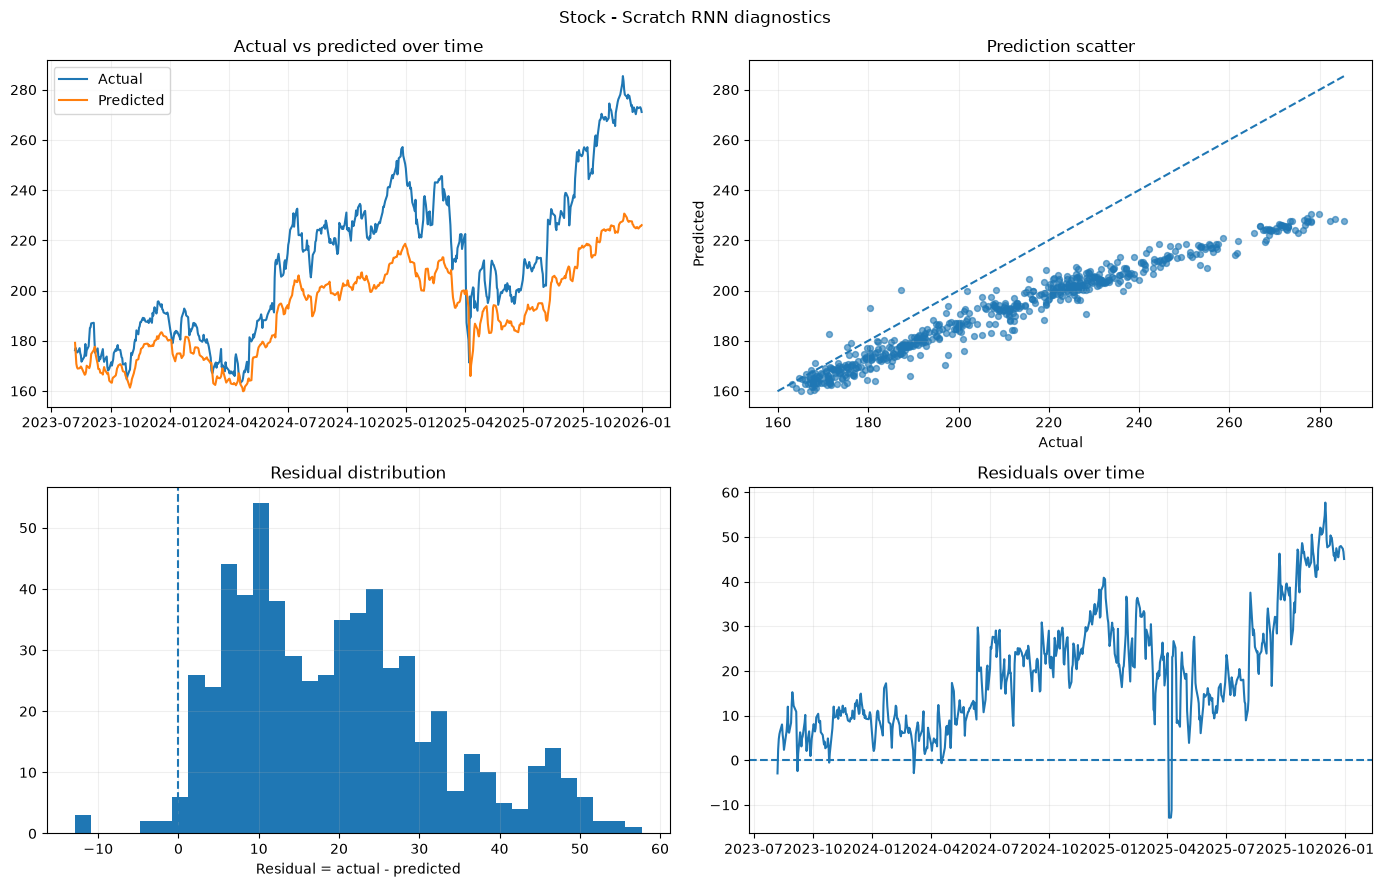

In [41]:
# Purpose: Train and evaluate the NumPy scratch RNN on the stock dataset.
scratch_stock_start = time.perf_counter()
scratch_stock_params, scratch_stock_history = train_scratch_model(
    stock_train_X, stock_train_y, stock_val_X, stock_val_y,
    n_features=stock_train_X.shape[-1], hidden_size=HIDDEN_SIZE, seed=SEED
)
scratch_stock_time = time.perf_counter() - scratch_stock_start

scratch_stock_scaled, scratch_stock_cache = scratch_predict(stock_test_X, scratch_stock_params)
scratch_stock_pred = inverse_target(stock_y_scaler, scratch_stock_scaled)
scratch_stock_true = inverse_target(stock_y_scaler, stock_test_y)
scratch_stock_metrics = regression_metrics(scratch_stock_true, scratch_stock_pred)

print("Stock Scratch metrics:")
print(json.dumps(scratch_stock_metrics, indent=2))
plot_prediction_diagnostics(stock_test_dates, scratch_stock_true, scratch_stock_pred, "Stock - Scratch RNN diagnostics")

# Supplementary directional metric: sign of one-day price movement.
prev_close = stock.loc[stock.index[stock_val_end:len(stock)], "Close"].to_numpy() if False else None


### Supplementary stock metric: directional accuracy

For stock data, a regression model can have a moderate price error while still missing the direction of the next-day move. Therefore the notebook reports a **supplementary** directional accuracy:

$$DirectionAcc = \frac{1}{N}\sum_{i=1}^{N} \mathbb{1}[sign(\hat y_i-y_{i-1}) = sign(y_i-y_{i-1})]$$

This is not a replacement for MAE, RMSE, MAPE, or $R^2$. It is an additional diagnostic describing whether the model gets the sign of the next move correct.


In [42]:
# Purpose: Compute directional accuracy from next-day close predictions.
def directional_accuracy(previous_close, y_true, y_pred):
    """Measure how often predicted and actual next-step price changes have the same sign."""
    previous_close = np.asarray(previous_close).reshape(-1)
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    actual_direction = np.sign(y_true - previous_close)
    pred_direction = np.sign(y_pred - previous_close)
    return float(np.mean(actual_direction == pred_direction))

# The previous close for each test target is the final input timestep's close feature before the target.
close_feature_index = stock_feature_cols.index("Close")
stock_test_previous_close = inverse_target(
    stock_y_scaler,
    stock_test_X[:, -1, close_feature_index]
)

scratch_stock_directional_acc = directional_accuracy(
    stock_test_previous_close, scratch_stock_true, scratch_stock_pred
)
print("Scratch stock directional accuracy:", round(scratch_stock_directional_acc*100, 2), "%")


Scratch stock directional accuracy: 46.36 %


### Directional confusion matrix

For stock forecasting, an additional binary view can be derived from the sign of the next-day price change:

- `Up` if $y_{t+1}-y_t > 0$;
- `Down` if $y_{t+1}-y_t < 0$.

This does not replace the regression metrics. It only describes directional behavior.

Epoch 1/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.0155 - mae: 0.0669 - val_loss: 0.0374 - val_mae: 0.1608 - learning_rate: 0.0010
Epoch 2/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0010 - mae: 0.0228 - val_loss: 0.0367 - val_mae: 0.1616 - learning_rate: 0.0010
Epoch 3/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 5.9096e-04 - mae: 0.0169 - val_loss: 0.0326 - val_mae: 0.1531 - learning_rate: 0.0010
Epoch 4/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 4.1485e-04 - mae: 0.0139 - val_loss: 0.0232 - val_mae: 0.1256 - learning_rate: 0.0010
Epoch 5/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 3.1127e-04 - mae: 0.0117 - val_loss: 0.0166 - val_mae: 0.1041 - learning_rate: 0.0010
Epoch 6/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 2.6410e-04 - mae: 0.0108 - val_loss: 0.0120 - val_mae: 0.0866 - learning_rate: 0.0010
Epoch 7/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 2.3587e-04 - mae: 0.0102 - val_loss: 0.0086 - val_mae: 0.0711 - learning_rate: 0.0010

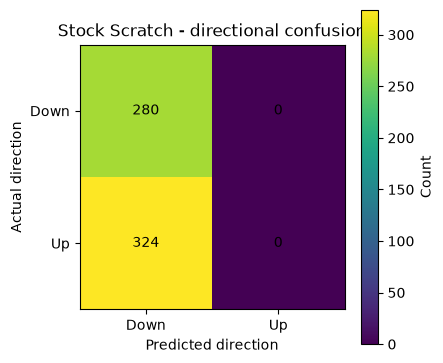

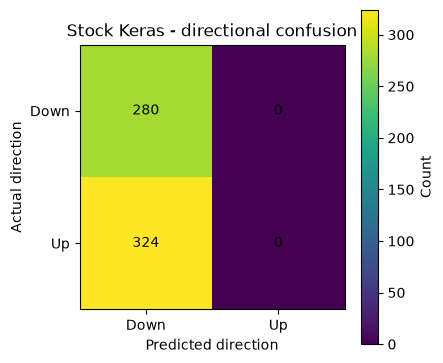

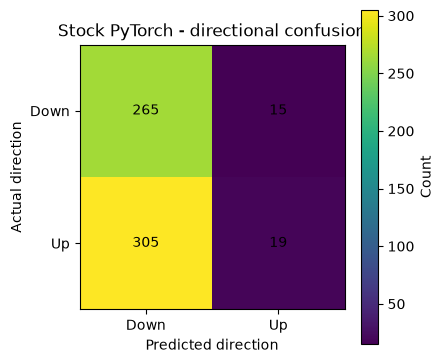

array([[265,  15],
       [305,  19]])

In [43]:
# Purpose: Visualize up/down directional mistakes for all three stock RNN implementations.
from sklearn.metrics import confusion_matrix

# Recover the shared test targets and previous closes from notebook variables.
stock_test_true = inverse_target(stock_y_scaler, stock_test_y)

if "stock_test_previous_close" not in globals():
    close_feature_index = stock_feature_cols.index("Close")
    stock_test_previous_close = inverse_target(
        stock_y_scaler,
        stock_test_X[:, -1, close_feature_index]
    )

# Use existing trained models when available; otherwise train them here.
if "keras_stock_model" not in globals():
    if tf is None:
        raise ImportError("TensorFlow is required for the Keras stock model.")

    KERAS_STOCK_DIR = MODELS_DIR / "stock"
    KERAS_STOCK_DIR.mkdir(parents=True, exist_ok=True)
    keras_stock_path = KERAS_STOCK_DIR / "keras_rnn.keras"

    keras_stock_model, keras_stock_history, keras_stock_time = train_keras_rnn(
        stock_train_X,
        stock_train_y,
        stock_val_X,
        stock_val_y,
        stock_train_X.shape[-1],
        keras_stock_path,
    )

keras_stock_pred = inverse_target(
    stock_y_scaler,
    keras_stock_model.predict(
        stock_test_X,
        batch_size=BATCH_SIZE,
        verbose=0
    ).reshape(-1)
)

if "torch_stock_model" not in globals():
    torch_stock_path = MODELS_DIR / "stock" / "pytorch_rnn.pt"
    torch_stock_path.parent.mkdir(parents=True, exist_ok=True)

    (
        torch_stock_model,
        torch_stock_history,
        torch_stock_time,
        TORCH_STOCK_DEVICE,
    ) = train_torch_rnn(
        stock_train_X,
        stock_train_y,
        stock_val_X,
        stock_val_y,
        stock_train_X.shape[-1],
        torch_stock_path,
    )

if "TORCH_STOCK_DEVICE" not in globals():
    TORCH_STOCK_DEVICE = next(torch_stock_model.parameters()).device

torch_stock_model.eval()
with torch.no_grad():
    torch_stock_output = torch_stock_model(
        torch.tensor(
            stock_test_X,
            dtype=torch.float32,
            device=TORCH_STOCK_DEVICE
        )
    )[0]

torch_stock_pred = inverse_target(
    stock_y_scaler,
    torch_stock_output.detach().cpu().numpy().reshape(-1)
)


def plot_direction_confusion(y_true, pred, previous_close, title):
    """Display a 2x2 confusion matrix for predicted versus actual next-day direction."""
    actual = (
        np.asarray(y_true).reshape(-1)
        >= np.asarray(previous_close).reshape(-1)
    ).astype(int)

    predicted = (
        np.asarray(pred).reshape(-1)
        >= np.asarray(previous_close).reshape(-1)
    ).astype(int)

    cm = confusion_matrix(actual, predicted, labels=[0, 1])

    plt.figure(figsize=(4.5, 4))
    plt.imshow(cm, interpolation="nearest")
    plt.xticks([0, 1], ["Down", "Up"])
    plt.yticks([0, 1], ["Down", "Up"])
    plt.xlabel("Predicted direction")
    plt.ylabel("Actual direction")
    plt.title(title)

    for i in range(2):
        for j in range(2):
            plt.text(j, i, int(cm[i, j]), ha="center", va="center")

    plt.colorbar(label="Count")
    plt.tight_layout()
    plt.show()

    return cm


plot_direction_confusion(
    stock_test_true,
    scratch_stock_pred,
    stock_test_previous_close,
    "Stock Scratch - directional confusion"
)

plot_direction_confusion(
    stock_test_true,
    keras_stock_pred,
    stock_test_previous_close,
    "Stock Keras - directional confusion"
)

plot_direction_confusion(
    stock_test_true,
    torch_stock_pred,
    stock_test_previous_close,
    "Stock PyTorch - directional confusion"
)

## 26. Keras RNN - stock training and evaluation


Epoch 1/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0049 - mae: 0.0400 - val_loss: 0.0103 - val_mae: 0.0872 - learning_rate: 0.0010
Epoch 2/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 5.1245e-04 - mae: 0.0172 - val_loss: 0.0108 - val_mae: 0.0909 - learning_rate: 0.0010
Epoch 3/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 3.8046e-04 - mae: 0.0148 - val_loss: 0.0073 - val_mae: 0.0720 - learning_rate: 0.0010
Epoch 4/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 2.7251e-04 - mae: 0.0120 - val_loss: 0.0060 - val_mae: 0.0652 - learning_rate: 0.0010
Epoch 5/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 2.1647e-04 - mae: 0.0106 - val_loss: 0.0055 - val_mae: 0.0625 - learning_rate: 0.0010
Epoch 6/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1.9469e-04 - mae: 0.0100 - val_loss: 0.0048 - val_mae: 0.0586 - learning_rate: 0.0010
Epoch 7/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1.6719e-04 - mae: 0.0089 - val_loss: 0.0044 - val_mae: 0.0560 - learning_rate: 0.

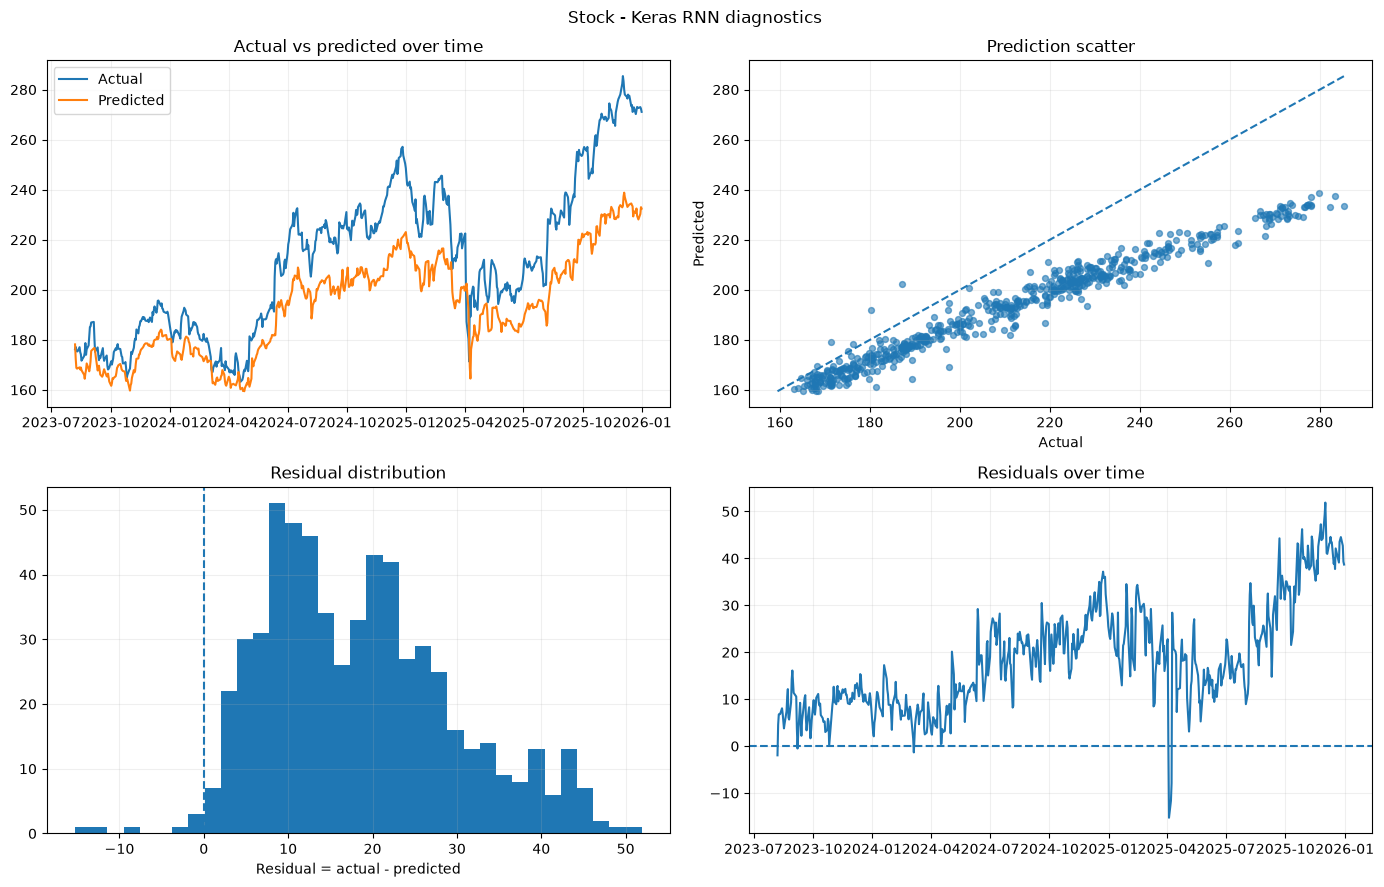

In [44]:
# Purpose: Train and evaluate the Keras RNN on the stock dataset.
KERAS_STOCK_DIR = MODELS_DIR / "stock"
KERAS_STOCK_DIR.mkdir(parents=True, exist_ok=True)
keras_stock_path = KERAS_STOCK_DIR / "keras_rnn.keras"
keras_stock_model, keras_stock_history, keras_stock_time = train_keras_rnn(
    stock_train_X, stock_train_y, stock_val_X, stock_val_y,
    stock_train_X.shape[-1], keras_stock_path
)

keras_stock_scaled = keras_stock_model.predict(stock_test_X, batch_size=BATCH_SIZE, verbose=0).reshape(-1)
keras_stock_pred = inverse_target(stock_y_scaler, keras_stock_scaled)
keras_stock_true = inverse_target(stock_y_scaler, stock_test_y)
keras_stock_metrics = regression_metrics(keras_stock_true, keras_stock_pred)
keras_stock_directional_acc = directional_accuracy(
    stock_test_previous_close, keras_stock_true, keras_stock_pred
)

print("Stock Keras metrics:")
print(json.dumps(keras_stock_metrics, indent=2))
print("Directional accuracy:", round(keras_stock_directional_acc*100, 2), "%")
plot_prediction_diagnostics(stock_test_dates, keras_stock_true, keras_stock_pred, "Stock - Keras RNN diagnostics")


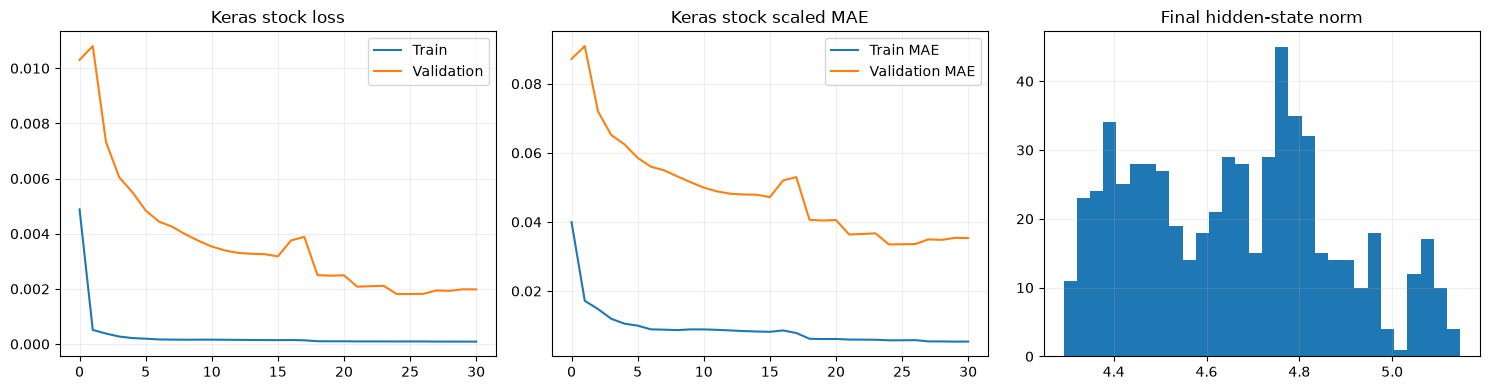

In [45]:
# Purpose: Plot the Keras stock training history and hidden-state norm distribution.

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(keras_stock_history["loss"], label="Train")
axes[0].plot(keras_stock_history["val_loss"], label="Validation")
axes[0].set_title("Keras stock loss")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(keras_stock_history["mae"], label="Train MAE")
axes[1].plot(keras_stock_history["val_mae"], label="Validation MAE")
axes[1].set_title("Keras stock scaled MAE")
axes[1].legend()
axes[1].grid(alpha=0.2)

# SimpleRNN uses return_sequences=False, so the output shape is
# (number_of_samples, hidden_size); it has no timestep axis.
state_model_stock = tf.keras.Model(
    inputs=keras_stock_model.input,
    outputs=keras_stock_model.get_layer("rnn").output,
)
keras_stock_states = state_model_stock.predict(
    stock_test_X,
    batch_size=BATCH_SIZE,
    verbose=0,
)
keras_stock_hidden_norms = np.linalg.norm(keras_stock_states, axis=1)

axes[2].hist(keras_stock_hidden_norms, bins=30)
axes[2].set_title("Final hidden-state norm")
axes[2].grid(alpha=0.2)

plt.tight_layout()
plt.show()

## 27. PyTorch RNN - stock training and evaluation


Stock PyTorch metrics:
{
  "MAE": 17.62743377685547,
  "RMSE": 20.61356513034105,
  "MAPE_percent": 7.833569526672363,
  "R2": 0.5376691818237305
}
Directional accuracy: 46.52 %


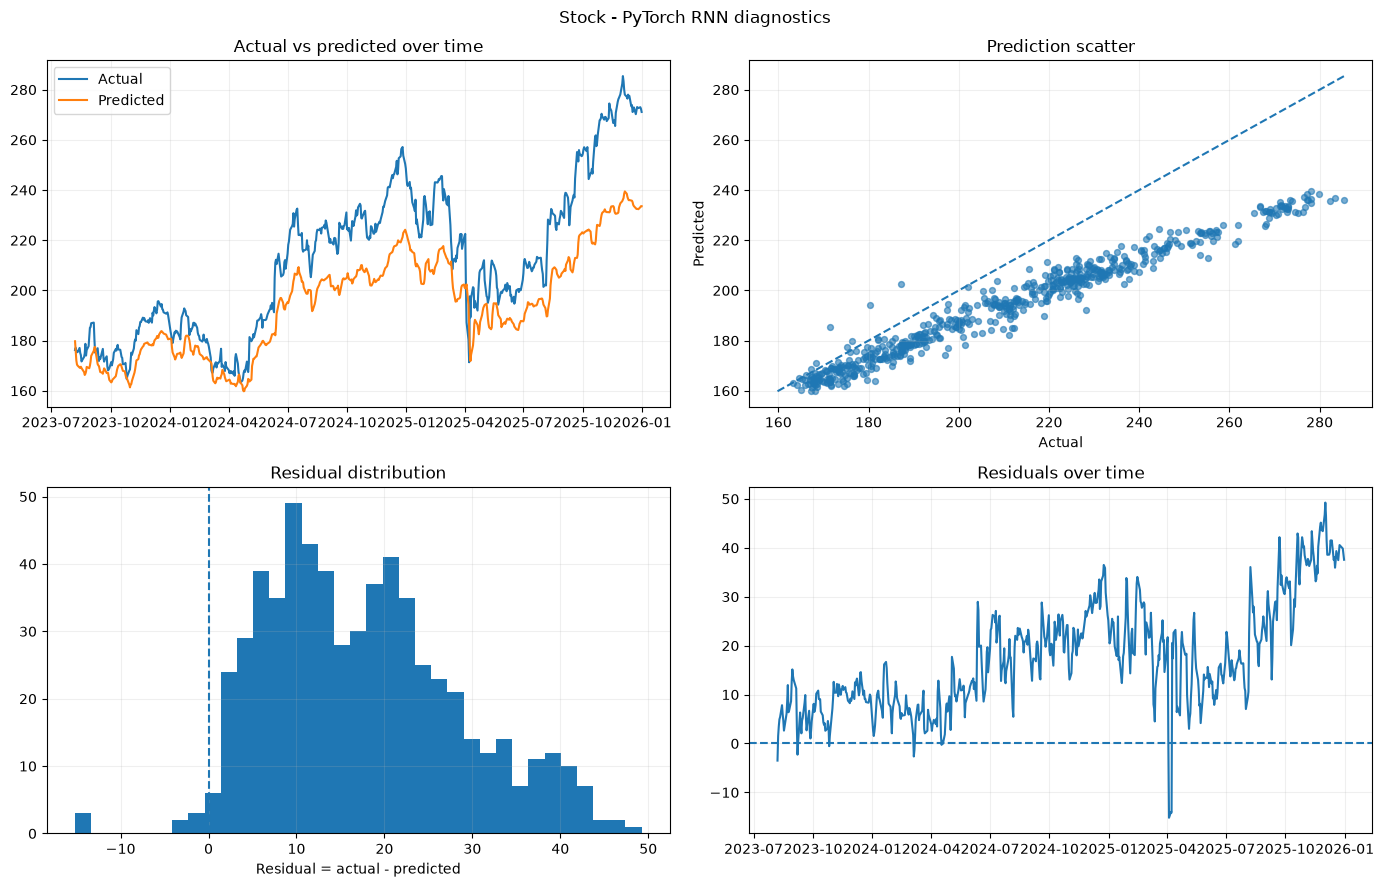

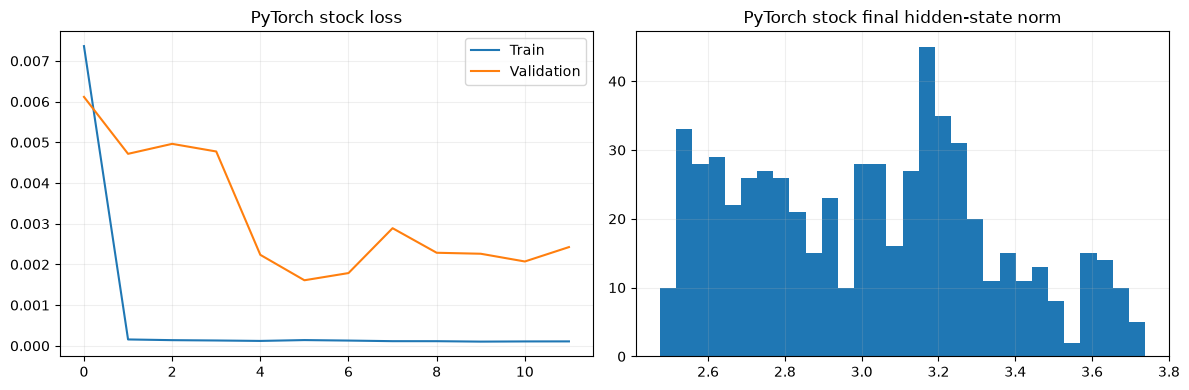

In [46]:
# Purpose: Train and evaluate the PyTorch RNN on the stock dataset.
torch_stock_path = MODELS_DIR / "stock" / "pytorch_rnn.pt"
torch_stock_model, torch_stock_history, torch_stock_time, TORCH_STOCK_DEVICE = train_torch_rnn(
    stock_train_X, stock_train_y, stock_val_X, stock_val_y,
    stock_train_X.shape[-1], torch_stock_path
)

torch_stock_model.eval()
with torch.no_grad():
    pred_t, hidden_t, output_t = torch_stock_model(
        torch.tensor(stock_test_X, dtype=torch.float32, device=TORCH_STOCK_DEVICE)
    )
torch_stock_scaled = pred_t.detach().cpu().numpy().reshape(-1)
torch_stock_pred = inverse_target(stock_y_scaler, torch_stock_scaled)
torch_stock_true = inverse_target(stock_y_scaler, stock_test_y)
torch_stock_metrics = regression_metrics(torch_stock_true, torch_stock_pred)
torch_stock_directional_acc = directional_accuracy(
    stock_test_previous_close, torch_stock_true, torch_stock_pred
)

print("Stock PyTorch metrics:")
print(json.dumps(torch_stock_metrics, indent=2))
print("Directional accuracy:", round(torch_stock_directional_acc*100, 2), "%")
plot_prediction_diagnostics(stock_test_dates, torch_stock_true, torch_stock_pred, "Stock - PyTorch RNN diagnostics")

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(torch_stock_history["train_loss"], label="Train")
axes[0].plot(torch_stock_history["val_loss"], label="Validation")
axes[0].set_title("PyTorch stock loss"); axes[0].legend(); axes[0].grid(alpha=0.2)
axes[1].hist(np.linalg.norm(hidden_t.detach().cpu().numpy()[-1], axis=1), bins=30)
axes[1].set_title("PyTorch stock final hidden-state norm"); axes[1].grid(alpha=0.2)
plt.tight_layout(); plt.show()


### Persistence baseline

The stock persistence baseline predicts that the next closing price equals the most recent observed closing price. Its regression metrics provide a reference point for interpreting the RNN results.

Stock persistence baseline:
{
  "MAE": 3.5394182205200195,
  "RMSE": 5.077913720063889,
  "MAPE_percent": 1.6891069412231445,
  "R2": 0.9719445705413818
}


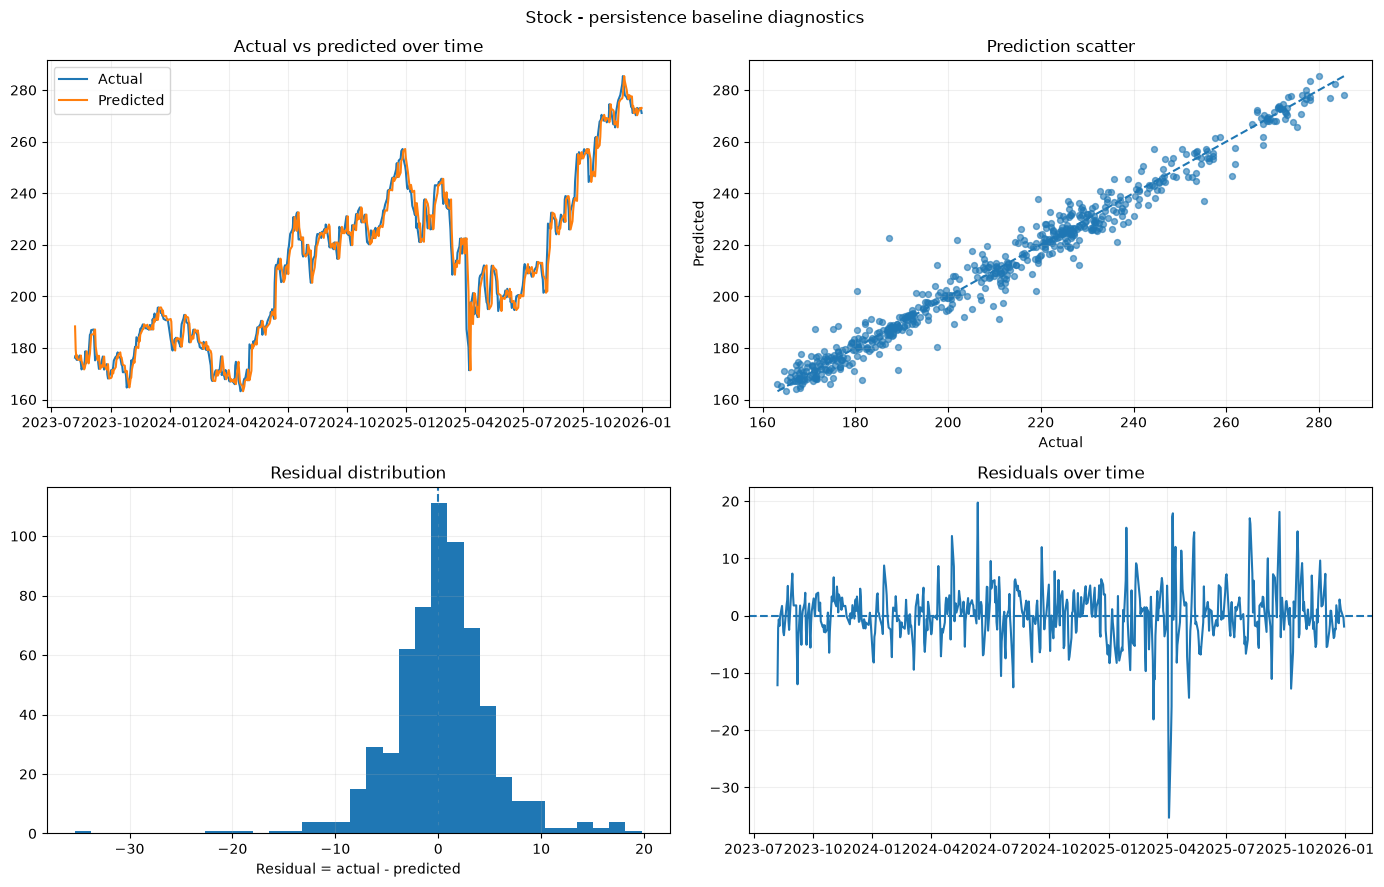

In [47]:
# Purpose: Evaluate the stock persistence baseline on the same held-out test targets.
stock_persistence_pred = stock_test_previous_close.copy()
stock_persistence_metrics = regression_metrics(stock_test_true, stock_persistence_pred)
print("Stock persistence baseline:")
print(json.dumps(stock_persistence_metrics, indent=2))
plot_prediction_diagnostics(
    stock_test_dates, stock_test_true, stock_persistence_pred,
    "Stock - persistence baseline diagnostics"
)


## 28. Stock experiment comparison

All three implementations operate on the same supervised windows and the same held-out test targets. This lets us separate two questions:

1. **Learning-system question:** how do Scratch, Keras, and PyTorch express the same RNN concept?
2. **Performance question:** how similar are the measured predictions under the common protocol?


,dataset,framework,model,parameters,training_time_s,directional_accuracy,MAE,RMSE,MAPE_percent,R2
0,AAPL stock,Persistence,Last-value baseline,0,0.00,nan%,3.5394,5.0779,1.69,0.9719
1,AAPL stock,Scratch,Vanilla RNN,"4,801",4.29,46.36%,19.7430,23.4505,8.72,0.4017
2,AAPL stock,Keras,SimpleRNN,"4,801",26.00,46.36%,18.6268,21.5895,8.30,0.4929
3,AAPL stock,PyTorch,nn.RNN,"4,865",13.26,46.52%,17.6274,20.6136,7.83,0.5377


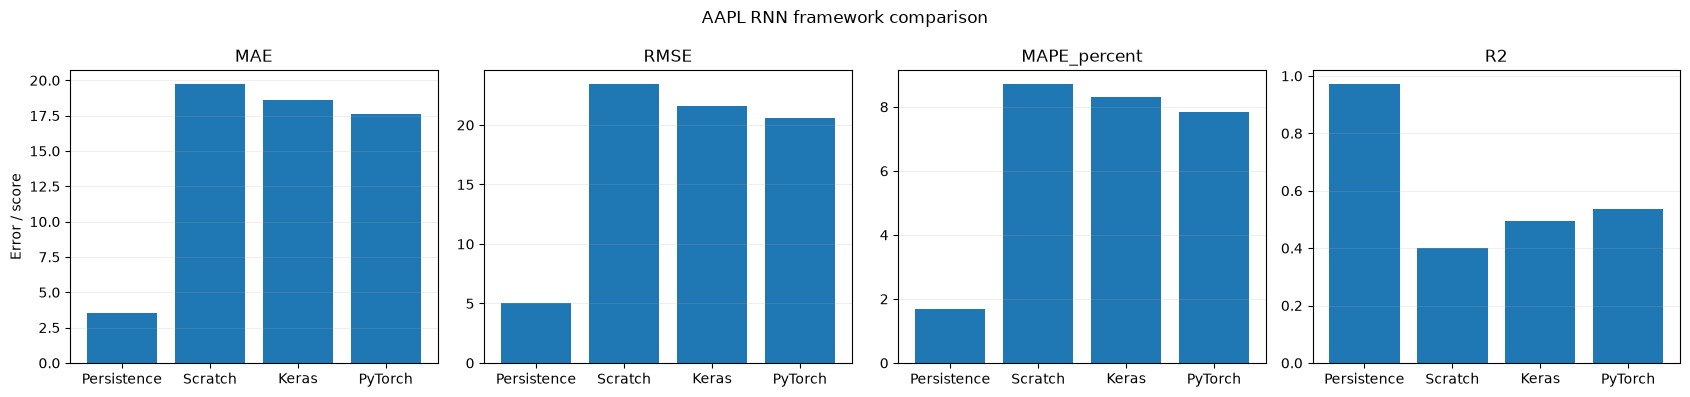

,framework,MAE,RMSE,MAPE_percent,R2,directional_accuracy,MAE_improvement_vs_persistence_%,RMSE_improvement_vs_persistence_%
0,Persistence,3.5394,5.0779,1.69,0.9719,nan%,0.00,0.00
1,Scratch,19.7430,23.4505,8.72,0.4017,46.36%,-457.80,-361.81
2,Keras,18.6268,21.5895,8.30,0.4929,46.36%,-426.27,-325.17
3,PyTorch,17.6274,20.6136,7.83,0.5377,46.52%,-398.03,-305.95


,framework,median_abs_error,p90_abs_error,p95_abs_error
0,Persistence,2.4648,7.3687,9.9974
1,Scratch,17.9828,38.0336,46.3211
2,Keras,17.3586,34.4970,40.2438
3,PyTorch,16.2397,33.4251,38.6034


In [48]:
# Purpose: Assemble stock results for framework comparison.

stock_test_true = scratch_stock_true

stock_results = pd.DataFrame([
    {
        "dataset": "AAPL stock",
        "framework": "Persistence",
        "model": "Last-value baseline",
        "parameters": 0,
        "training_time_s": 0.0,
        "directional_accuracy": np.nan,
        **stock_persistence_metrics,
    },
    {
        "dataset": "AAPL stock",
        "framework": "Scratch",
        "model": "Vanilla RNN",
        "parameters": scratch_parameter_count(scratch_stock_params),
        "training_time_s": scratch_stock_time,
        "directional_accuracy": scratch_stock_directional_acc,
        **scratch_stock_metrics,
    },
    {
        "dataset": "AAPL stock",
        "framework": "Keras",
        "model": "SimpleRNN",
        "parameters": keras_stock_model.count_params(),
        "training_time_s": keras_stock_time,
        "directional_accuracy": keras_stock_directional_acc,
        **keras_stock_metrics,
    },
    {
        "dataset": "AAPL stock",
        "framework": "PyTorch",
        "model": "nn.RNN",
        "parameters": sum(p.numel() for p in torch_stock_model.parameters()),
        "training_time_s": torch_stock_time,
        "directional_accuracy": torch_stock_directional_acc,
        **torch_stock_metrics,
    },
])

display(stock_results.style.format({
    "MAE": "{:.4f}",
    "RMSE": "{:.4f}",
    "MAPE_percent": "{:.2f}",
    "R2": "{:.4f}",
    "directional_accuracy": "{:.2%}",
    "training_time_s": "{:.2f}",
    "parameters": "{:,}",
}))

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "MAPE_percent", "R2"]):
    ax.bar(stock_results["framework"], stock_results[metric])
    ax.set_title(metric)
    ax.grid(axis="y", alpha=0.2)

axes[0].set_ylabel("Error / score")
plt.suptitle("AAPL RNN framework comparison")
plt.tight_layout()
plt.show()

stock_results = add_baseline_improvement(stock_results)

display(
    stock_results[
        [
            "framework",
            "MAE",
            "RMSE",
            "MAPE_percent",
            "R2",
            "directional_accuracy",
            "MAE_improvement_vs_persistence_%",
            "RMSE_improvement_vs_persistence_%",
        ]
    ].style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "MAPE_percent": "{:.2f}",
        "R2": "{:.4f}",
        "directional_accuracy": "{:.2%}",
        "MAE_improvement_vs_persistence_%": "{:.2f}",
        "RMSE_improvement_vs_persistence_%": "{:.2f}",
    })
)

stock_error_quantiles = pd.DataFrame([
    {
        "framework": name,
        "median_abs_error": float(np.median(np.abs(true - pred))),
        "p90_abs_error": float(np.quantile(np.abs(true - pred), 0.90)),
        "p95_abs_error": float(np.quantile(np.abs(true - pred), 0.95)),
    }
    for name, true, pred in [
        ("Persistence", stock_test_true, stock_persistence_pred),
        ("Scratch", stock_test_true, scratch_stock_pred),
        ("Keras", stock_test_true, keras_stock_pred),
        ("PyTorch", stock_test_true, torch_stock_pred),
    ]
])

display(
    stock_error_quantiles.style.format({
        "median_abs_error": "{:.4f}",
        "p90_abs_error": "{:.4f}",
        "p95_abs_error": "{:.4f}",
    })
)

# Part D - Unified technical analysis

## 29. Six-experiment comparison table

A final unified table is the main quantitative summary of the assignment.

A valid interpretation should consider at least four dimensions:

- predictive error in original units;
- normalized error as a percentage where useful;
- goodness-of-fit through $R^2$;
- engineering cost in parameters and training time.


In [49]:
# Purpose: Combine all six RNN experiments into one reproducible summary table.
all_results = pd.concat([ecom_results, stock_results], ignore_index=True)
all_results = all_results.sort_values(["dataset", "framework"]).reset_index(drop=True)

summary_cols = ["dataset", "framework", "model", "parameters", "training_time_s", "MAE", "RMSE", "MAPE_percent", "R2"]
comparison_df = all_results[summary_cols].copy()
display(comparison_df.style.format({
    "parameters":"{:,}", "training_time_s":"{:.2f}",
    "MAE":"{:.4f}", "RMSE":"{:.4f}", "MAPE_percent":"{:.2f}", "R2":"{:.4f}"
}))

comparison_df.to_csv(METRICS_DIR / "all_experiments_summary.csv", index=False)
save_json(comparison_df.to_dict(orient="records"), METRICS_DIR / "all_experiments_summary.json")


,dataset,framework,model,parameters,training_time_s,MAE,RMSE,MAPE_percent,R2
0,AAPL stock,Keras,SimpleRNN,"4,801",26.00,18.6268,21.5895,8.30,0.4929
1,AAPL stock,Persistence,Last-value baseline,0,0.00,3.5394,5.0779,1.69,0.9719
2,AAPL stock,PyTorch,nn.RNN,"4,865",13.26,17.6274,20.6136,7.83,0.5377
3,AAPL stock,Scratch,Vanilla RNN,"4,801",4.29,19.7430,23.4505,8.72,0.4017
4,E-commerce service process,Keras,SimpleRNN,"4,673",9.73,12.1026,26.9987,40.50,-0.1386
5,E-commerce service process,Persistence,Last-value baseline,0,0.00,5.9379,14.1767,25.84,0.6861
6,E-commerce service process,PyTorch,nn.RNN,"4,737",1.51,11.9349,25.2472,49.18,0.0044
7,E-commerce service process,Scratch,Vanilla RNN,"4,673",0.29,12.4748,26.5686,47.32,-0.1026


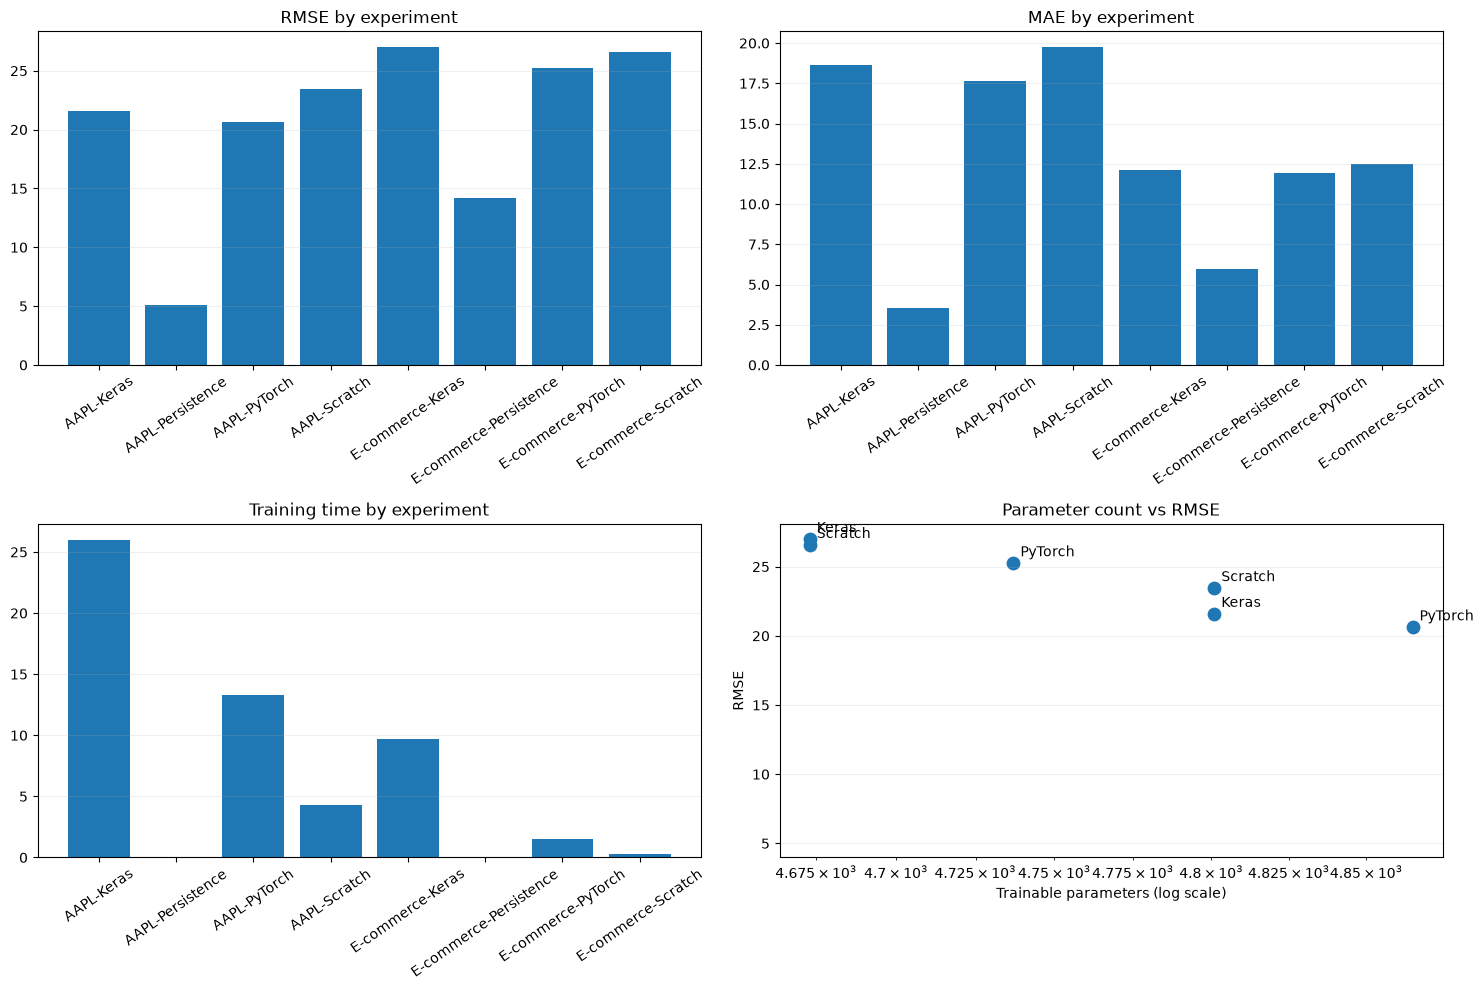

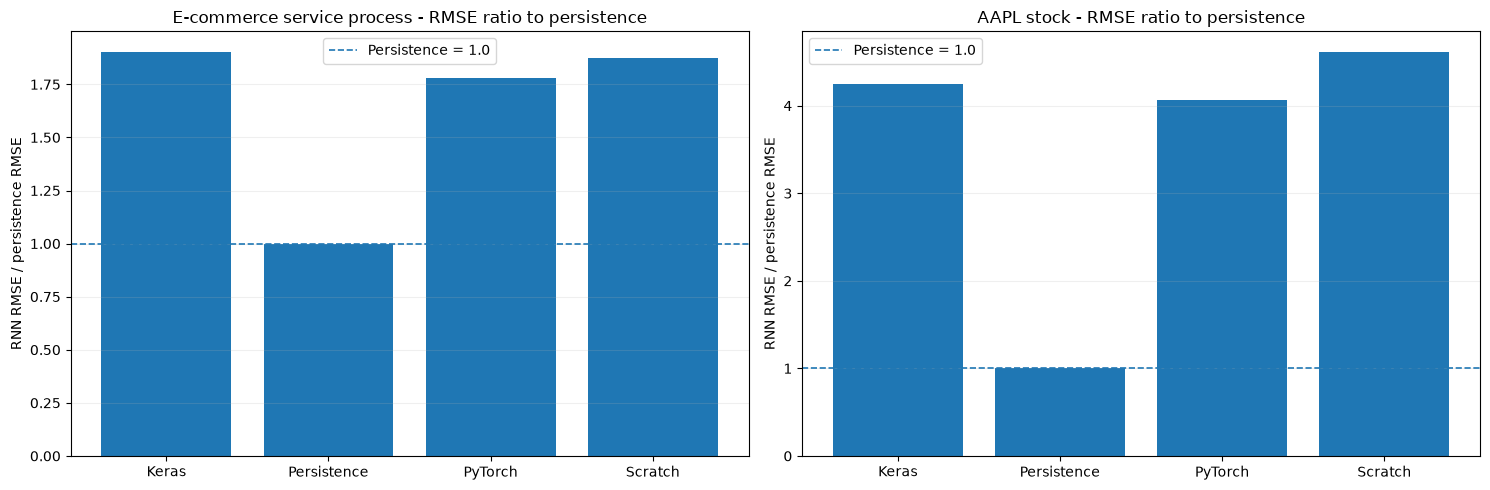

In [50]:
# Purpose: Visualize the six experiments across error, fit quality, runtime, and model size.
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
labels = [f"{r.dataset.split()[0]}-{r.framework}" for r in all_results.itertuples()]

axes[0,0].bar(labels, all_results["RMSE"])
axes[0,0].set_title("RMSE by experiment"); axes[0,0].tick_params(axis="x", rotation=35); axes[0,0].grid(axis="y", alpha=0.2)
axes[0,1].bar(labels, all_results["MAE"])
axes[0,1].set_title("MAE by experiment"); axes[0,1].tick_params(axis="x", rotation=35); axes[0,1].grid(axis="y", alpha=0.2)
axes[1,0].bar(labels, all_results["training_time_s"])
axes[1,0].set_title("Training time by experiment"); axes[1,0].tick_params(axis="x", rotation=35); axes[1,0].grid(axis="y", alpha=0.2)
axes[1,1].scatter(all_results["parameters"], all_results["RMSE"], s=80)
for _, row in all_results.iterrows():
    axes[1,1].annotate(row["framework"], (row["parameters"], row["RMSE"]), xytext=(5,5), textcoords="offset points")
axes[1,1].set_xscale("log")
axes[1,1].set_title("Parameter count vs RMSE")
axes[1,1].set_xlabel("Trainable parameters (log scale)"); axes[1,1].set_ylabel("RMSE"); axes[1,1].grid(alpha=0.2)
plt.tight_layout(); plt.show()


# Baseline-relative RMSE is a scale-free within-dataset view of whether the RNN improved over persistence.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, dataset_name in zip(axes, ["E-commerce service process", "AAPL stock"]):
    sub = all_results[all_results["dataset"].eq(dataset_name)].copy()
    baseline_rmse = float(sub.loc[sub["framework"].eq("Persistence"), "RMSE"].iloc[0])
    sub["RMSE_ratio_vs_persistence"] = sub["RMSE"] / baseline_rmse
    ax.bar(sub["framework"], sub["RMSE_ratio_vs_persistence"])
    ax.axhline(1.0, linestyle="--", linewidth=1.2, label="Persistence = 1.0")
    ax.set_title(dataset_name + " - RMSE ratio to persistence")
    ax.set_ylabel("RNN RMSE / persistence RMSE")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
plt.tight_layout(); plt.show()


## 30. Training-curve comparison

Training curves show information that a single test metric cannot provide.

Typical interpretations include:

- **Train and validation both decrease:** learning is occurring and the current capacity is useful.
- **Train decreases while validation stops improving:** the model may be overfitting or the available temporal signal may be limited.
- **Both remain high:** the model may be underfitting, poorly scaled, or using insufficient temporal context.
- **Strong oscillation:** optimization may be unstable or the learning rate may be too large.

Because the three frameworks may stop at different epochs due to validation-based early stopping, the curves are interpreted by shape rather than by assuming that more epochs are automatically better.


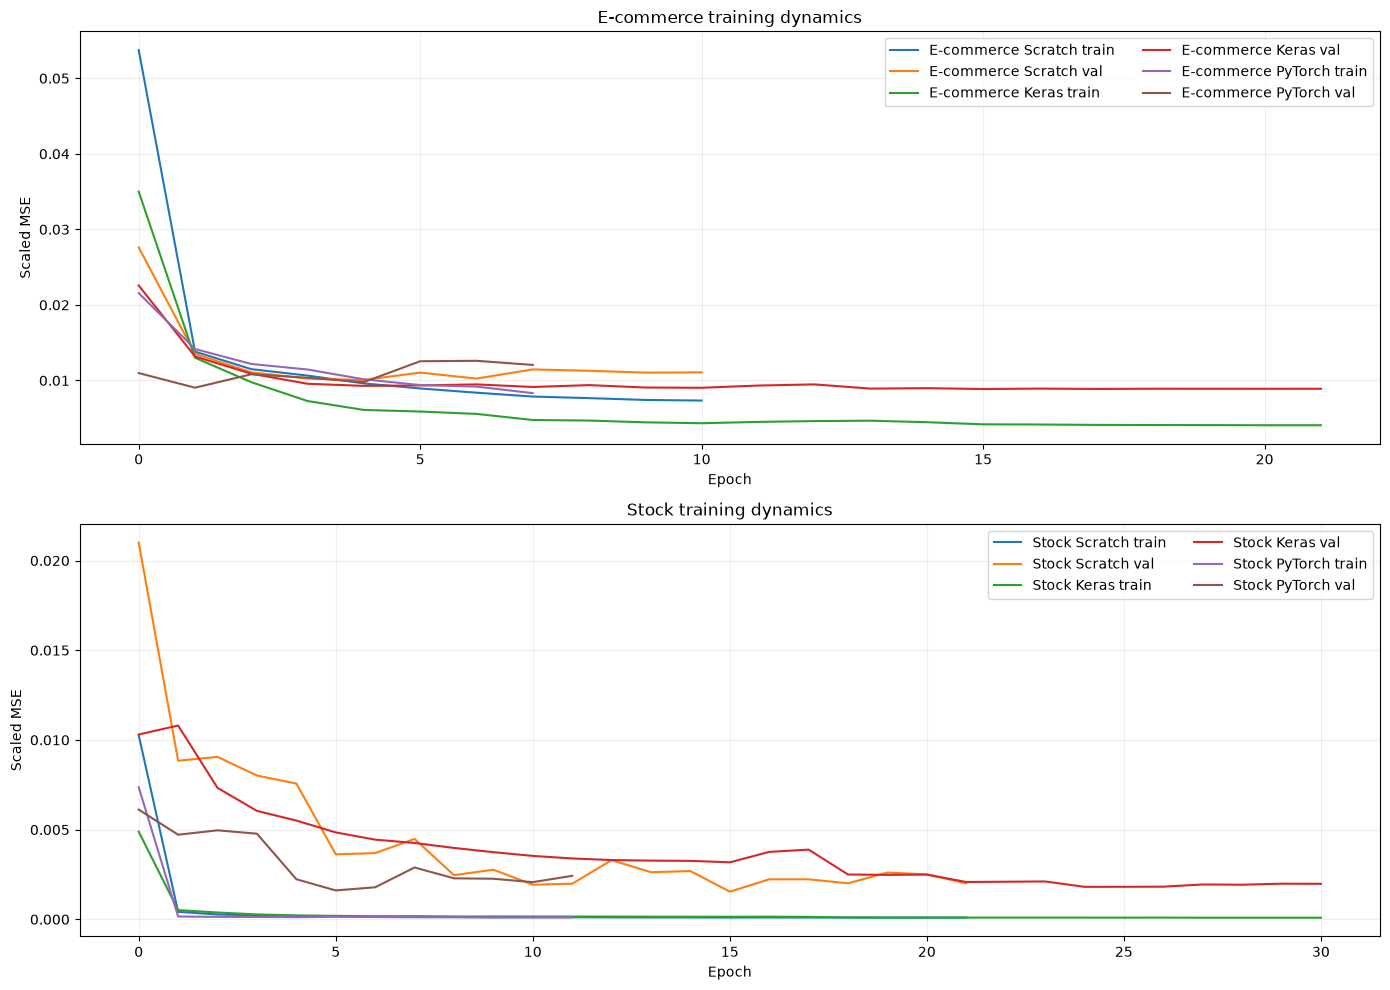

In [51]:
# Purpose: Compare training/validation loss curves across all six experiments.
fig, axes = plt.subplots(2, 1, figsize=(14,10))

axes[0].plot(scratch_ecom_history["train_loss"], label="E-commerce Scratch train")
axes[0].plot(scratch_ecom_history["val_loss"], label="E-commerce Scratch val")
axes[0].plot(keras_ecom_history["loss"], label="E-commerce Keras train")
axes[0].plot(keras_ecom_history["val_loss"], label="E-commerce Keras val")
axes[0].plot(torch_ecom_history["train_loss"], label="E-commerce PyTorch train")
axes[0].plot(torch_ecom_history["val_loss"], label="E-commerce PyTorch val")
axes[0].set_title("E-commerce training dynamics")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Scaled MSE")
axes[0].legend(ncol=2); axes[0].grid(alpha=0.2)

axes[1].plot(scratch_stock_history["train_loss"], label="Stock Scratch train")
axes[1].plot(scratch_stock_history["val_loss"], label="Stock Scratch val")
axes[1].plot(keras_stock_history["loss"], label="Stock Keras train")
axes[1].plot(keras_stock_history["val_loss"], label="Stock Keras val")
axes[1].plot(torch_stock_history["train_loss"], label="Stock PyTorch train")
axes[1].plot(torch_stock_history["val_loss"], label="Stock PyTorch val")
axes[1].set_title("Stock training dynamics")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Scaled MSE")
axes[1].legend(ncol=2); axes[1].grid(alpha=0.2)
plt.tight_layout(); plt.show()


## 31. Regression diagnostics beyond a single score

A model can achieve a reasonable average error while still having systematic problems. The notebook therefore uses:

1. **Actual vs predicted time series** - checks tracking of temporal movement.
2. **Prediction scatter** - checks whether predictions follow the identity line.
3. **Residual distribution** - checks overall bias and spread.
4. **Residuals over time** - checks temporal error drift.
5. **Rolling MAE** - reveals periods in which the model becomes less accurate.
6. **Hidden-state norm** - provides a direct diagnostic of the recurrent representation magnitude.

For stock data, the directional accuracy is also inspected because price direction is a distinct property from absolute price error.


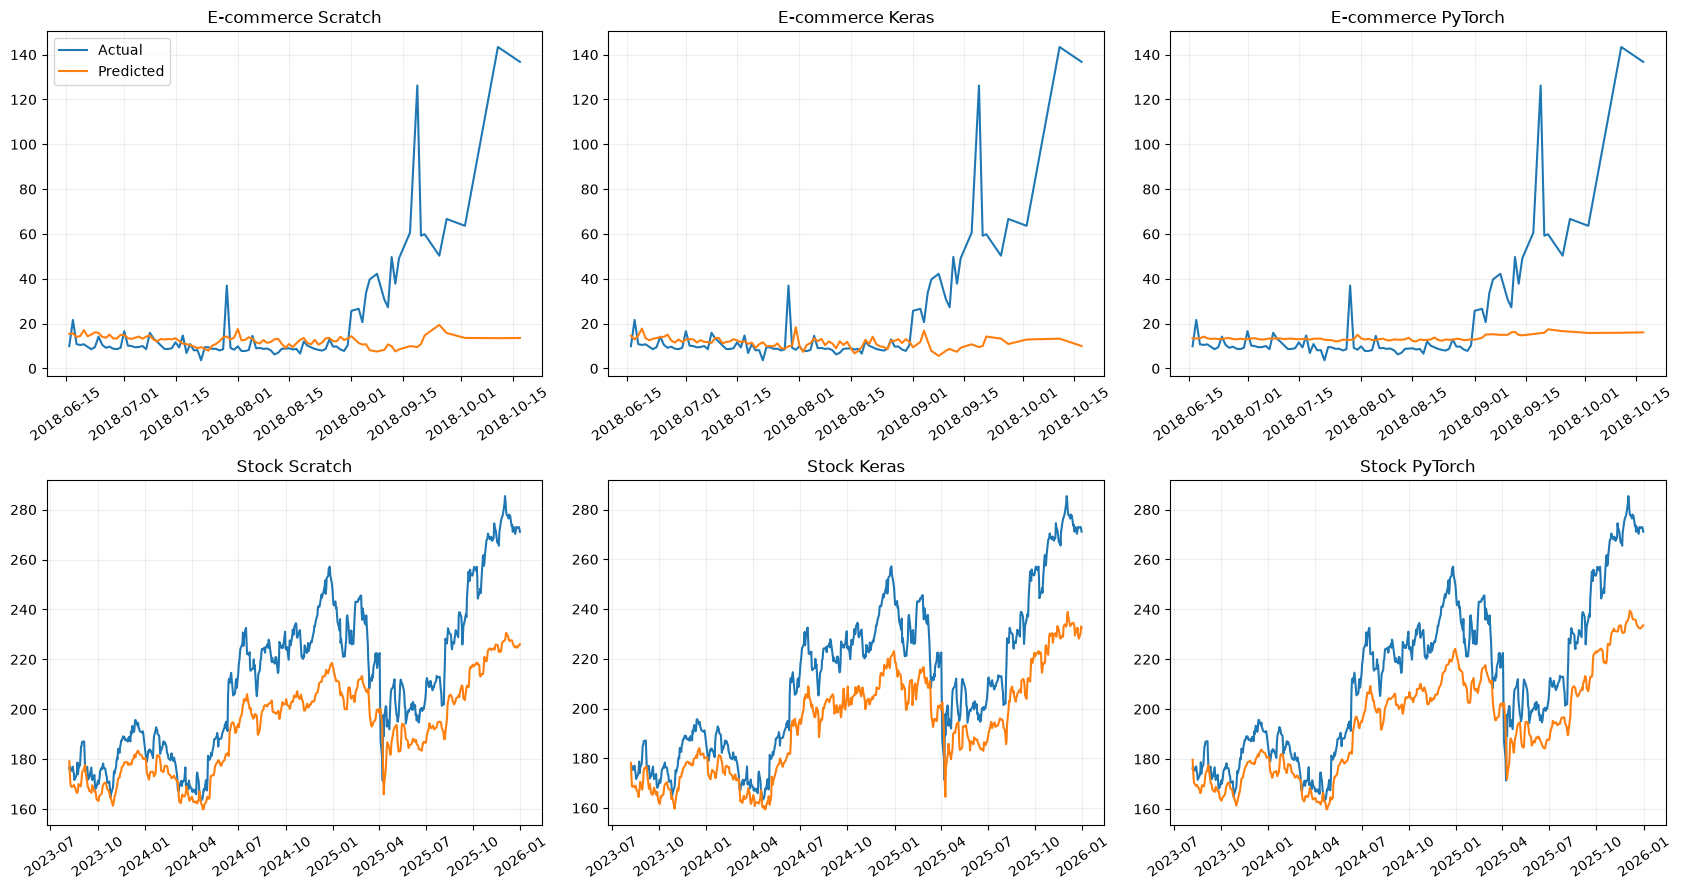

In [52]:
# Purpose: Compare test predictions from every framework in a compact visual dashboard.
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

pred_sets = [
    (ecom_test_dates, scratch_ecom_test_true, scratch_ecom_test_pred, "E-commerce Scratch"),
    (ecom_test_dates, keras_ecom_test_true, keras_ecom_test_pred, "E-commerce Keras"),
    (ecom_test_dates, torch_ecom_test_true, torch_ecom_test_pred, "E-commerce PyTorch"),
    (stock_test_dates, scratch_stock_true, scratch_stock_pred, "Stock Scratch"),
    (stock_test_dates, keras_stock_true, keras_stock_pred, "Stock Keras"),
    (stock_test_dates, torch_stock_true, torch_stock_pred, "Stock PyTorch"),
]

for ax, (dates, true, pred, title) in zip(axes.flat, pred_sets):
    ax.plot(pd.to_datetime(dates), true, label="Actual")
    ax.plot(pd.to_datetime(dates), pred, label="Predicted")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=35)
    ax.grid(alpha=0.2)
axes[0,0].legend()
plt.tight_layout(); plt.show()


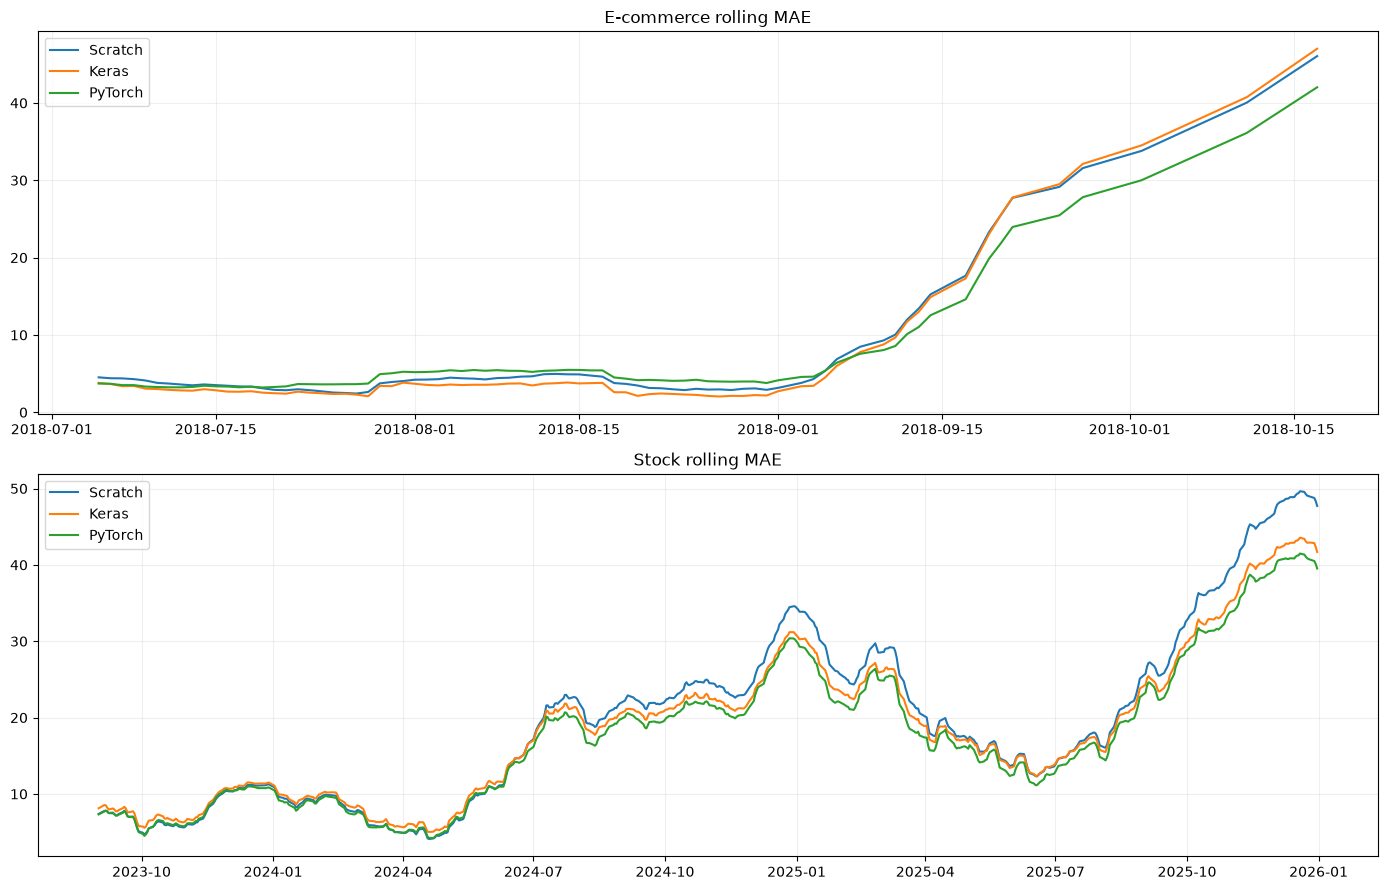

In [53]:
# Purpose: Visualize rolling test-set MAE to detect time-dependent error regimes.
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
axes[0].plot(pd.to_datetime(ecom_test_dates), rolling_mae(scratch_ecom_test_true, scratch_ecom_test_pred), label="Scratch")
axes[0].plot(pd.to_datetime(ecom_test_dates), rolling_mae(keras_ecom_test_true, keras_ecom_test_pred), label="Keras")
axes[0].plot(pd.to_datetime(ecom_test_dates), rolling_mae(torch_ecom_test_true, torch_ecom_test_pred), label="PyTorch")
axes[0].set_title("E-commerce rolling MAE"); axes[0].legend(); axes[0].grid(alpha=0.2)
axes[1].plot(pd.to_datetime(stock_test_dates), rolling_mae(scratch_stock_true, scratch_stock_pred), label="Scratch")
axes[1].plot(pd.to_datetime(stock_test_dates), rolling_mae(keras_stock_true, keras_stock_pred), label="Keras")
axes[1].plot(pd.to_datetime(stock_test_dates), rolling_mae(torch_stock_true, torch_stock_pred), label="PyTorch")
axes[1].set_title("Stock rolling MAE"); axes[1].legend(); axes[1].grid(alpha=0.2)
plt.tight_layout(); plt.show()


## 32. Residual and error analysis

Residuals are defined as:

$$e_t = y_t - \hat y_t$$

A useful residual analysis asks:

- Is the residual distribution centered approximately around zero?
- Are there large tails or isolated outliers?
- Does error magnitude grow with the target value?
- Do errors cluster in particular time periods?

For the stock dataset, nonstationary market regimes can produce periods with larger residuals. For the e-commerce service dataset, operational changes may similarly create shifts in delivery performance.

The purpose of this section is not to label every error as a model problem. A residual can also reflect information that is simply unavailable in the chosen input representation.


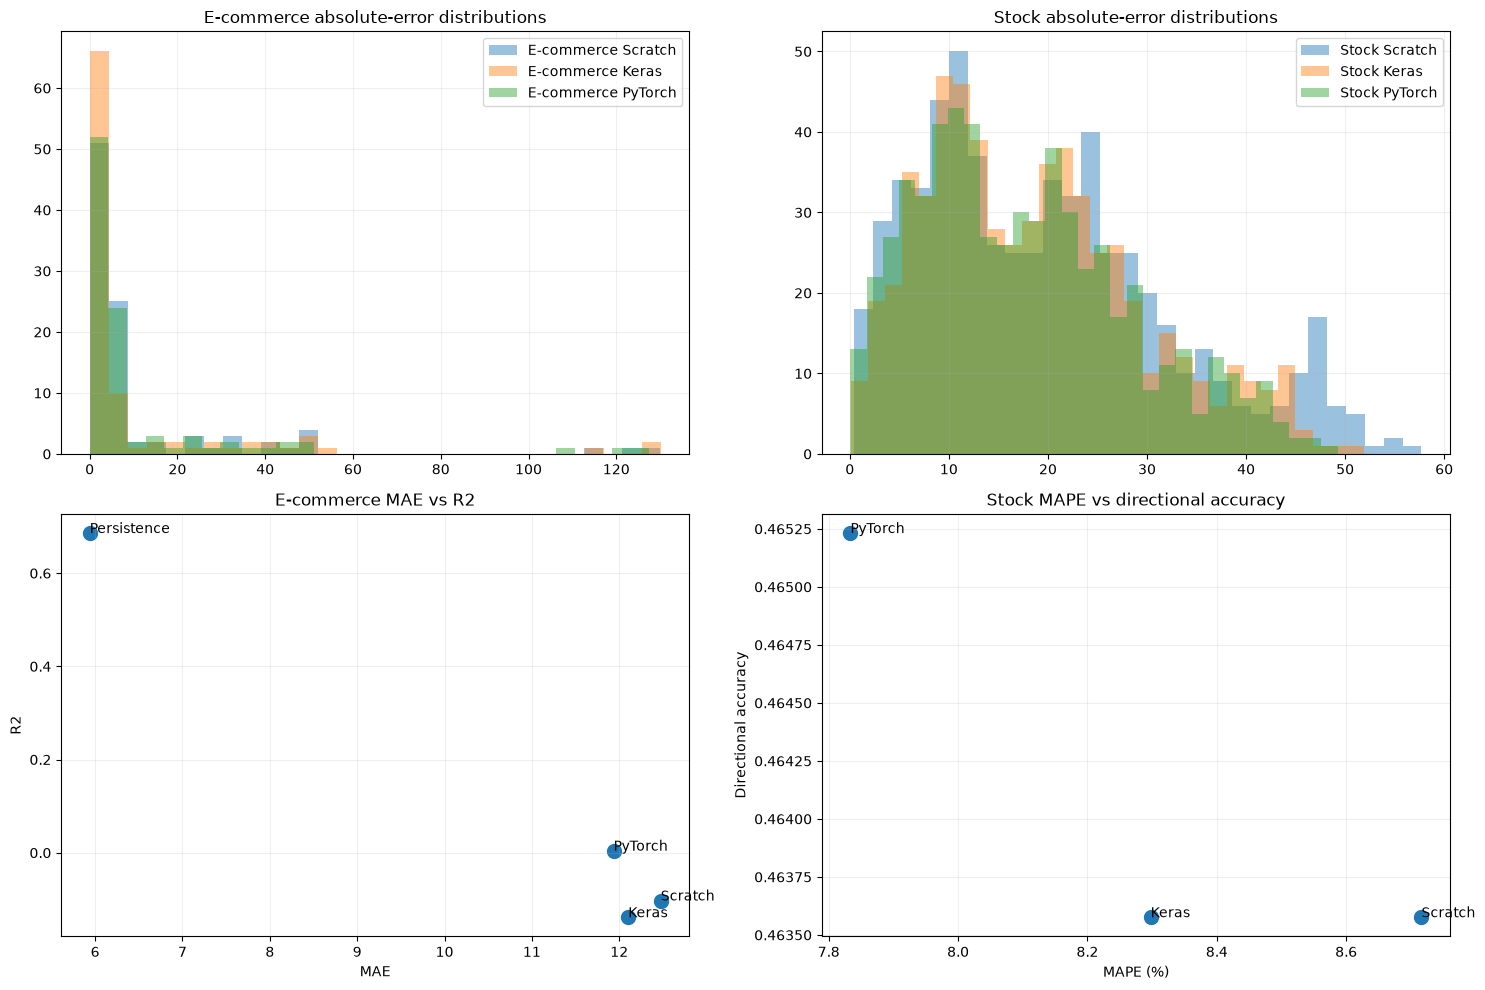

In [54]:
# Purpose: Compare absolute errors and residual distributions across frameworks.
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for values, name in [
    (np.abs(scratch_ecom_test_true - scratch_ecom_test_pred), "E-commerce Scratch"),
    (np.abs(keras_ecom_test_true - keras_ecom_test_pred), "E-commerce Keras"),
    (np.abs(torch_ecom_test_true - torch_ecom_test_pred), "E-commerce PyTorch"),
]:
    axes[0,0].hist(values, bins=30, alpha=0.45, label=name)
axes[0,0].set_title("E-commerce absolute-error distributions"); axes[0,0].legend(); axes[0,0].grid(alpha=0.2)

for values, name in [
    (np.abs(scratch_stock_true - scratch_stock_pred), "Stock Scratch"),
    (np.abs(keras_stock_true - keras_stock_pred), "Stock Keras"),
    (np.abs(torch_stock_true - torch_stock_pred), "Stock PyTorch"),
]:
    axes[0,1].hist(values, bins=30, alpha=0.45, label=name)
axes[0,1].set_title("Stock absolute-error distributions"); axes[0,1].legend(); axes[0,1].grid(alpha=0.2)

axes[1,0].scatter(ecom_results["MAE"], ecom_results["R2"], s=100)
for _, row in ecom_results.iterrows():
    axes[1,0].annotate(row["framework"], (row["MAE"], row["R2"]))
axes[1,0].set_title("E-commerce MAE vs R2")
axes[1,0].set_xlabel("MAE"); axes[1,0].set_ylabel("R2"); axes[1,0].grid(alpha=0.2)

axes[1,1].scatter(stock_results["MAPE_percent"], stock_results["directional_accuracy"], s=100)
for _, row in stock_results.iterrows():
    axes[1,1].annotate(row["framework"], (row["MAPE_percent"], row["directional_accuracy"]))
axes[1,1].set_title("Stock MAPE vs directional accuracy")
axes[1,1].set_xlabel("MAPE (%)"); axes[1,1].set_ylabel("Directional accuracy"); axes[1,1].grid(alpha=0.2)
plt.tight_layout(); plt.show()


## 33. Parameter count and runtime analysis

A technical comparison should not report only accuracy. The architecture also has an engineering cost.

For the vanilla RNN, parameter count grows approximately with:

$$FH + H^2 + 2H + 1$$

The $H^2$ recurrent matrix is important because increasing hidden size changes the recurrent state-to-state transformation quadratically.

The frameworks may report nearly identical parameter counts because they implement the same conceptual architecture. Training time can still differ because the implementations use different tensor kernels, data-loader systems, automatic-differentiation engines, and Python-level overhead.

Therefore:

```text
same parameterization ≠ identical runtime
same runtime     ≠ identical numerical path
```


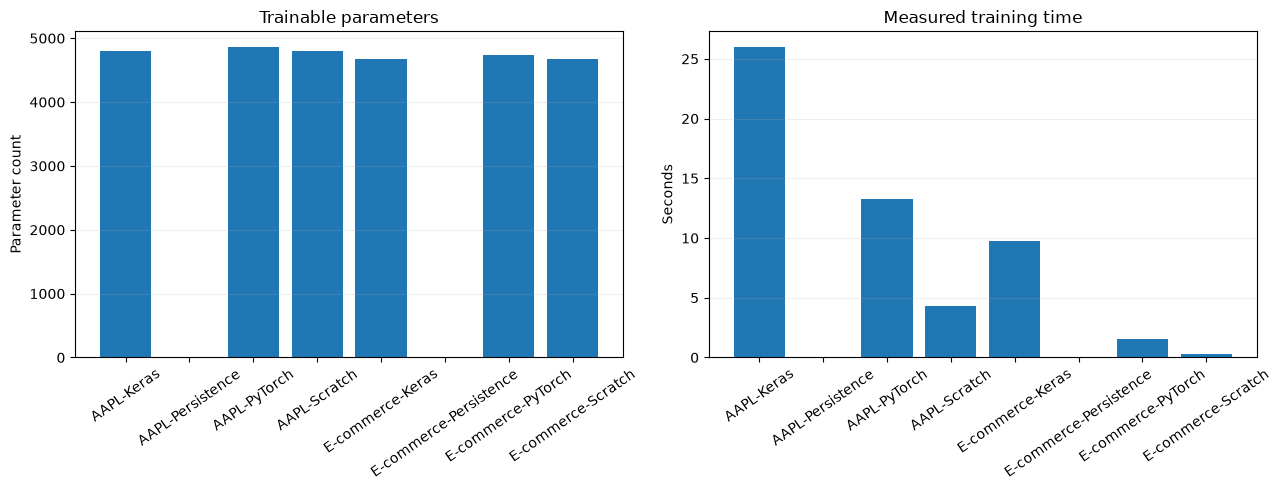

In [55]:
# Purpose: Visualize parameter count and measured training time independently of predictive quality.
fig, axes = plt.subplots(1, 2, figsize=(13,5))
labels = [f"{r.dataset.split()[0]}-{r.framework}" for r in all_results.itertuples()]
axes[0].bar(labels, all_results["parameters"])
axes[0].set_title("Trainable parameters")
axes[0].set_ylabel("Parameter count")
axes[0].tick_params(axis="x", rotation=35)
axes[0].grid(axis="y", alpha=0.2)

axes[1].bar(labels, all_results["training_time_s"])
axes[1].set_title("Measured training time")
axes[1].set_ylabel("Seconds")
axes[1].tick_params(axis="x", rotation=35)
axes[1].grid(axis="y", alpha=0.2)
plt.tight_layout(); plt.show()


## 34. Framework-level comparison: Scratch vs Keras vs PyTorch

The three implementations correspond to three levels of abstraction.

| Component | Scratch | Keras | PyTorch |
|---|---|---|---|
| Recurrent step | explicit NumPy loop | `SimpleRNN` | `nn.RNN` |
| Hidden-state update | manual formula | framework layer | framework module |
| Loss | manual MSE | Keras loss | `nn.MSELoss` |
| Gradient | manual BPTT | automatic differentiation | autograd |
| Gradient clipping | manual norm scaling | optimizer `clipnorm` | `clip_grad_norm_` |
| Optimizer | manual Adam | `Adam` | `Adam` |
| Training loop | manual | `model.fit()` | explicit Python loop |

### What becomes hidden in Keras?

`model.fit()` encapsulates repeated operations such as batch retrieval, forward propagation, loss computation, automatic differentiation, optimizer updates, and validation evaluation.

### What remains visible in PyTorch?

The training loop makes `zero_grad()`, the forward pass, `loss.backward()`, gradient clipping, and `optimizer.step()` explicit.

### What is visible in Scratch?

The scratch implementation shows the actual recurrence, hidden-state storage, BPTT equations, gradient aggregation, gradient clipping, and Adam parameter updates.

The important conclusion is that the frameworks do not change the underlying RNN learning problem. They change **how much of the implementation the programmer has to manage explicitly**.


## 35. Practical model summary

The following table is designed for the report's final discussion. It places predictive error, improvement relative to persistence, parameter count, and training time next to each other. Raw MAE should only be compared within the same dataset because the two targets have different units and scales.

In [56]:
# Purpose: Produce a compact report table combining accuracy, baseline-relative improvement, and engineering cost.
report_summary = all_results.copy()
for base_name in ["E-commerce service process", "AAPL stock"]:
    base_rmse = float(report_summary.loc[(report_summary["dataset"] == base_name) & (report_summary["framework"] == "Persistence"), "RMSE"].iloc[0])
    mask = report_summary["dataset"].eq(base_name)
    report_summary.loc[mask, "RMSE_ratio_vs_persistence"] = report_summary.loc[mask, "RMSE"] / base_rmse

display(report_summary[[
    "dataset", "framework", "parameters", "training_time_s", "MAE", "RMSE",
    "RMSE_ratio_vs_persistence", "R2"
]].style.format({
    "parameters":"{:,}", "training_time_s":"{:.2f}",
    "MAE":"{:.4f}", "RMSE":"{:.4f}",
    "RMSE_ratio_vs_persistence":"{:.3f}", "R2":"{:.4f}"
}))


,dataset,framework,parameters,training_time_s,MAE,RMSE,RMSE_ratio_vs_persistence,R2
0,AAPL stock,Keras,"4,801",26.00,18.6268,21.5895,4.252,0.4929
1,AAPL stock,Persistence,0,0.00,3.5394,5.0779,1.000,0.9719
2,AAPL stock,PyTorch,"4,865",13.26,17.6274,20.6136,4.059,0.5377
3,AAPL stock,Scratch,"4,801",4.29,19.7430,23.4505,4.618,0.4017
4,E-commerce service process,Keras,"4,673",9.73,12.1026,26.9987,1.904,-0.1386
5,E-commerce service process,Persistence,0,0.00,5.9379,14.1767,1.000,0.6861
6,E-commerce service process,PyTorch,"4,737",1.51,11.9349,25.2472,1.781,0.0044
7,E-commerce service process,Scratch,"4,673",0.29,12.4748,26.5686,1.874,-0.1026


## 36. Limitations and responsible interpretation

### 36.1 Vanilla RNN memory limitation

A simple tanh RNN can struggle to preserve information across very long sequences because gradients repeatedly pass through recurrent transformations. More advanced recurrent cells such as LSTM and GRU introduce gating mechanisms to address long-range dependency problems more effectively.

This assignment deliberately keeps the architecture at the **vanilla RNN** level because the stated requirement is to understand the basic recurrent mechanism across Scratch, Keras, and PyTorch.

### 36.2 E-commerce representation limitation

The Olist source is an order-level e-commerce dataset. The notebook converts it into an aggregated operational time series. The resulting model forecasts future service-period performance from past aggregated indicators; it is not a direct simulation of every individual customer-service event.

### 36.3 Stock-market limitation

Historical stock data are non-stationary and strongly affected by external information that is not represented in the input variables. A lower historical test error should therefore not be interpreted as a guarantee of future market performance.

### 36.4 Hyperparameter scope

The assignment emphasizes RNN fundamentals and three implementation frameworks rather than exhaustive hyperparameter optimization. The lookback, hidden size, dropout, and optimizer settings are fixed to create a controlled comparison. A separate study could investigate how lookback length or hidden size changes performance.

### 36.5 Evaluation principle

A model should be interpreted using both aggregate metrics and temporal diagnostics. A single scalar score can hide drift, regime-specific errors, or poor behavior during unusual periods.


## 37. Model artifact export and web-demo preparation

The notebook saves artifacts so the web application can demonstrate the trained models without retraining.

### Saved model types

- Scratch: NumPy parameter dictionary serialized with `np.savez`.
- Keras: `.keras` model file.
- PyTorch: `.pt` state dictionary checkpoint.
- Preprocessing: `joblib` files for feature and target scalers.
- Metrics: JSON and CSV files.
- Demo payload: recent windows, actual/predicted series, model metadata, and metric definitions.

The web application reads these files from the same project root.


In [57]:
# Purpose: Save trained preprocessing objects, scratch parameters, predictions, histories, and web-ready metadata.
for dataset_name, x_scaler, y_scaler in [
    ("ecommerce", ecom_x_scaler, ecom_y_scaler),
    ("stock", stock_x_scaler, stock_y_scaler),
]:
    ds_dir = MODELS_DIR / dataset_name
    ds_dir.mkdir(parents=True, exist_ok=True)
    joblib.dump(x_scaler, ds_dir / "feature_scaler.joblib")
    joblib.dump(y_scaler, ds_dir / "target_scaler.joblib")

np.savez(
    MODELS_DIR / "ecommerce" / "scratch_rnn.npz",
    **scratch_ecom_params,
)
np.savez(
    MODELS_DIR / "stock" / "scratch_rnn.npz",
    **scratch_stock_params,
)

# Save histories in JSON-friendly form.
save_json(scratch_ecom_history, METRICS_DIR / "ecommerce_scratch_history.json")
save_json(keras_ecom_history, METRICS_DIR / "ecommerce_keras_history.json")
save_json(torch_ecom_history, METRICS_DIR / "ecommerce_pytorch_history.json")
save_json(scratch_stock_history, METRICS_DIR / "stock_scratch_history.json")
save_json(keras_stock_history, METRICS_DIR / "stock_keras_history.json")
save_json(torch_stock_history, METRICS_DIR / "stock_pytorch_history.json")

# Save model metadata so the website can load the artifacts without needing notebook variables.
model_metadata = {
    "config": CONFIG,
    "datasets": {
        "ecommerce": {
            "display_name": "E-commerce service process",
            "feature_columns": ecom_feature_cols,
            "target": ecom_target_col,
            "target_transform": "log1p_nonnegative",
            "lookback": LOOKBACK,
            "hidden_size": HIDDEN_SIZE,
            "keras_model": "models/ecommerce/keras_rnn.keras",
            "pytorch_model": "models/ecommerce/pytorch_rnn.pt",
            "scratch_model": "models/ecommerce/scratch_rnn.npz",
            "feature_scaler": "models/ecommerce/feature_scaler.joblib",
            "target_scaler": "models/ecommerce/target_scaler.joblib",
        },
        "stock": {
            "display_name": "AAPL stock",
            "feature_columns": stock_feature_cols,
            "target": stock_target_col,
            "lookback": LOOKBACK,
            "hidden_size": HIDDEN_SIZE,
            "keras_model": "models/stock/keras_rnn.keras",
            "pytorch_model": "models/stock/pytorch_rnn.pt",
            "scratch_model": "models/stock/scratch_rnn.npz",
            "feature_scaler": "models/stock/feature_scaler.joblib",
            "target_scaler": "models/stock/target_scaler.joblib",
        },
    },
}
save_json(model_metadata, METRICS_DIR / "model_metadata.json")

# Persist test predictions for external inspection.
for name, dates, true, pred in [
    ("ecommerce_scratch", ecom_test_dates, scratch_ecom_test_true, scratch_ecom_test_pred),
    ("ecommerce_keras", ecom_test_dates, keras_ecom_test_true, keras_ecom_test_pred),
    ("ecommerce_pytorch", ecom_test_dates, torch_ecom_test_true, torch_ecom_test_pred),
    ("stock_scratch", stock_test_dates, scratch_stock_true, scratch_stock_pred),
    ("stock_keras", stock_test_dates, keras_stock_true, keras_stock_pred),
    ("stock_pytorch", stock_test_dates, torch_stock_true, torch_stock_pred),
]:
    pd.DataFrame({"date": pd.to_datetime(dates), "actual": true, "predicted": pred, "residual": true-pred}).to_csv(
        PREDICTIONS_DIR / f"{name}_test_predictions.csv", index=False
    )

# Forecast windows include the latest fully observed row. Training pairs use x_t -> y_(t+1),
# so excluding the final x row here would accidentally forecast the last known target again.
ecom_web_window = ecom_x_scaler.transform(
    ecom_daily[ecom_feature_cols].to_numpy(dtype=np.float32)[-LOOKBACK:]
).astype(np.float32)
stock_web_window = stock_x_scaler.transform(
    stock[stock_feature_cols].to_numpy(dtype=np.float32)[-LOOKBACK:]
).astype(np.float32)

# Web-ready payload keeps a moderate number of points for responsive browser charts.
def web_series_payload(dates, true, pred, max_points=500):
    dates = pd.to_datetime(dates)
    true = np.asarray(true).reshape(-1)
    pred = np.asarray(pred).reshape(-1)
    if len(dates) > max_points:
        take = np.linspace(0, len(dates)-1, max_points).astype(int)
    else:
        take = np.arange(len(dates))
    return {
        "dates": [str(d.date()) for d in dates[take]],
        "actual": [float(x) for x in true[take]],
        "predicted": [float(x) for x in pred[take]],
        "residual": [float(true[i]-pred[i]) for i in take],
    }

web_payload = {
    "config": CONFIG,
    "ecommerce": {
        "summary": ecom_results.to_dict(orient="records"),
        "latest_date": str(pd.to_datetime(ecom_daily["service_date"].iloc[-1]).date()),
        "latest_observed_target": float(ecom_daily[ecom_target_col].iloc[-1]),
        "next_forecasts": {
            "Scratch": float(inverse_ecommerce_target(ecom_y_scaler, scratch_predict(ecom_web_window.reshape(1, LOOKBACK, -1), scratch_ecom_params)[0])[0]),
            "Keras": float(inverse_ecommerce_target(ecom_y_scaler, keras_ecom_model.predict(ecom_web_window.reshape(1, LOOKBACK, -1), verbose=0)[0][0])[0]),
            "PyTorch": float(inverse_ecommerce_target(ecom_y_scaler, torch_ecom_model(torch.tensor(ecom_web_window.reshape(1, LOOKBACK, -1), dtype=torch.float32, device=TORCH_DEVICE))[0].detach().cpu().numpy())[0]),
        },
        "series": {
            "Scratch": web_series_payload(ecom_test_dates, scratch_ecom_test_true, scratch_ecom_test_pred),
            "Keras": web_series_payload(ecom_test_dates, keras_ecom_test_true, keras_ecom_test_pred),
            "PyTorch": web_series_payload(ecom_test_dates, torch_ecom_test_true, torch_ecom_test_pred),
        },
        "histories": {
            "Scratch": scratch_ecom_history,
            "Keras": keras_ecom_history,
            "PyTorch": torch_ecom_history,
        },
        "features": ecom_feature_cols,
        "last_window": ecom_web_window.tolist(),
        "last_window_dates": [str(pd.to_datetime(d).date()) for d in ecom_daily["service_date"].iloc[-LOOKBACK:]],
        "target_unit": "days",
        "target_transform": "log1p_nonnegative",
        "forecast_horizon": "1 next observed service step",
    },
    "stock": {
        "summary": stock_results.to_dict(orient="records"),
        "latest_date": str(pd.to_datetime(stock["Date"].iloc[-1]).date()),
        "latest_observed_target": float(stock[stock_target_col].iloc[-1]),
        "next_forecasts": {
            "Scratch": float(inverse_target(stock_y_scaler, scratch_predict(stock_web_window.reshape(1, LOOKBACK, -1), scratch_stock_params)[0])[0]),
            "Keras": float(inverse_target(stock_y_scaler, keras_stock_model.predict(stock_web_window.reshape(1, LOOKBACK, -1), verbose=0)[0][0])[0]),
            "PyTorch": float(inverse_target(stock_y_scaler, torch_stock_model(torch.tensor(stock_web_window.reshape(1, LOOKBACK, -1), dtype=torch.float32, device=TORCH_STOCK_DEVICE))[0].detach().cpu().numpy())[0]),
        },
        "series": {
            "Scratch": web_series_payload(stock_test_dates, scratch_stock_true, scratch_stock_pred),
            "Keras": web_series_payload(stock_test_dates, keras_stock_true, keras_stock_pred),
            "PyTorch": web_series_payload(stock_test_dates, torch_stock_true, torch_stock_pred),
        },
        "histories": {
            "Scratch": scratch_stock_history,
            "Keras": keras_stock_history,
            "PyTorch": torch_stock_history,
        },
        "features": stock_feature_cols,
        "last_window": stock_web_window.tolist(),
        "last_window_dates": [str(pd.to_datetime(d).date()) for d in stock["Date"].iloc[-LOOKBACK:]],
        "target_unit": "price units",
        "forecast_horizon": "1 next trading step",
    },
    "metric_definitions": {
        "MAE": "Mean Absolute Error: average absolute prediction error in original target units.",
        "RMSE": "Root Mean Squared Error: square-root mean squared prediction error; larger errors receive more weight.",
        "MAPE_percent": "Mean Absolute Percentage Error, reported in percent for positive targets.",
        "R2": "Coefficient of determination; 1 is perfect fit and values below 0 can occur when the model is worse than the evaluated mean baseline.",
        "directional_accuracy": "Supplementary stock metric: fraction of test days for which predicted and actual price-change directions match.",
    },
}

save_json(web_payload, METRICS_DIR / "web_payload.json")
print("Export complete.")


Export complete.


## Web demonstration

Run the demo from the project root with:

```bash
cd web
python app.py
```

Then open the local address printed by Flask.

The website is designed to expose the technical results clearly:

```text
Dashboard
├── Dataset selector
├── Model selector
├── Latest forecast card
├── MAE / RMSE / MAPE / R2 metrics
├── Actual vs predicted chart
├── Residual-over-time chart
├── Error-distribution chart
├── Model comparison table
├── RNN architecture and input-window panel
├── Parameter/runtime information
└── Metric definitions and interpretation notes
```

The website loads notebook-generated JSON results and saved model metadata/prediction artifacts. The browser does not retrain the RNNs; it visualizes the exported next-step forecasts and evaluation artifacts.


## 38. Final technical conclusion

This assignment demonstrates the same recurrent learning idea through three implementation levels and two time-series applications.

The core computational chain is:

$$X_{t-L+1:t} \rightarrow Embedding\text{-like numeric representation} \rightarrow h_1 \rightarrow h_2 \rightarrow \cdots \rightarrow h_L \rightarrow \hat y_{t+1}$$

More explicitly:

```text
Historical feature window
        ↓
Repeated recurrent state updates
        ↓
Final hidden representation
        ↓
Linear regression head
        ↓
Next-step forecast
```

The scratch model exposes the mathematics directly. Keras provides a higher-level recurrent layer and training API. PyTorch provides an explicit model module with an equally explicit optimization loop.

The final model comparison should be written from the observed evidence produced by the notebook. The appropriate question is not simply "Which implementation is best?" but rather:

- How large is the predictive error on each dataset?
- How stable are validation and test behaviors?
- How does the model compare with the persistence baseline?
- What is the parameter and runtime cost?
- What implementation details are hidden or exposed by each framework?
- Which limitations of the chosen data representation remain visible in the residual analysis?

### Core takeaway

> **An RNN learns from ordered data by repeatedly updating a hidden state that carries information from earlier time steps into later computations.**

The framework changes the programming abstraction, but the recurrent learning principle remains the same.


## 39. Submission checklist and references

### Assignment requirement mapping

| Requirement | Notebook coverage |
|---|---|
| 1. Fully understand RNN concepts, functions, operators | Sections 3-8 and scratch numerical demonstrations |
| 2. Two time-related datasets | E-commerce service process + AAPL stock |
| 3. RNN scratch for both datasets | Sections 14-15 and 25 |
| 4. RNN Keras for both datasets | Sections 16-17 and 26 |
| 5. RNN PyTorch for both datasets | Sections 18-19 and 27 |
| Technical evaluation | MAE, RMSE, MAPE, R2 + stock directional accuracy |
| Rich visualization | EDA, time-series plots, correlation matrices, training curves, residuals, rolling MAE, hidden-state norms, comparisons |
| Model comparison | E-commerce, stock, and unified six-experiment tables |
| Web demo | `web/` Flask application |
| Reproducibility | fixed seeds, fixed stock date range, cached data, train-only scaling, exported metadata |

### Primary references

1. Keras `SimpleRNN` API: https://keras.io/2/api/layers/recurrent_layers/simple_rnn/
2. TensorFlow time-series forecasting tutorial: https://www.tensorflow.org/tutorials/structured_data/time_series
3. PyTorch `torch.nn.RNN` documentation: https://docs.pytorch.org/docs/main/generated/torch.nn.RNN.html
4. Olist Brazilian E-Commerce Public Dataset: https://www.kaggle.com/olistbr/brazilian-ecommerce
5. Yahoo Finance historical data: https://help.yahoo.com/kb/finance/certain-amounts-sln2311.html
6. `yfinance.download` API: https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html
7. scikit-learn `MinMaxScaler`: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html
8. scikit-learn regression metrics: https://scikit-learn.org/stable/modules/model_evaluation.html
9. Christopher Olah, *Understanding LSTM Networks*: https://colah.github.io/posts/2015-08-Understanding-LSTMs/

### Final reproducibility note

The notebook should be executed from top to bottom in a clean kernel after placing or downloading the two datasets. Long-running cells are the six training experiments. The final cells export the artifacts consumed by the web demo.


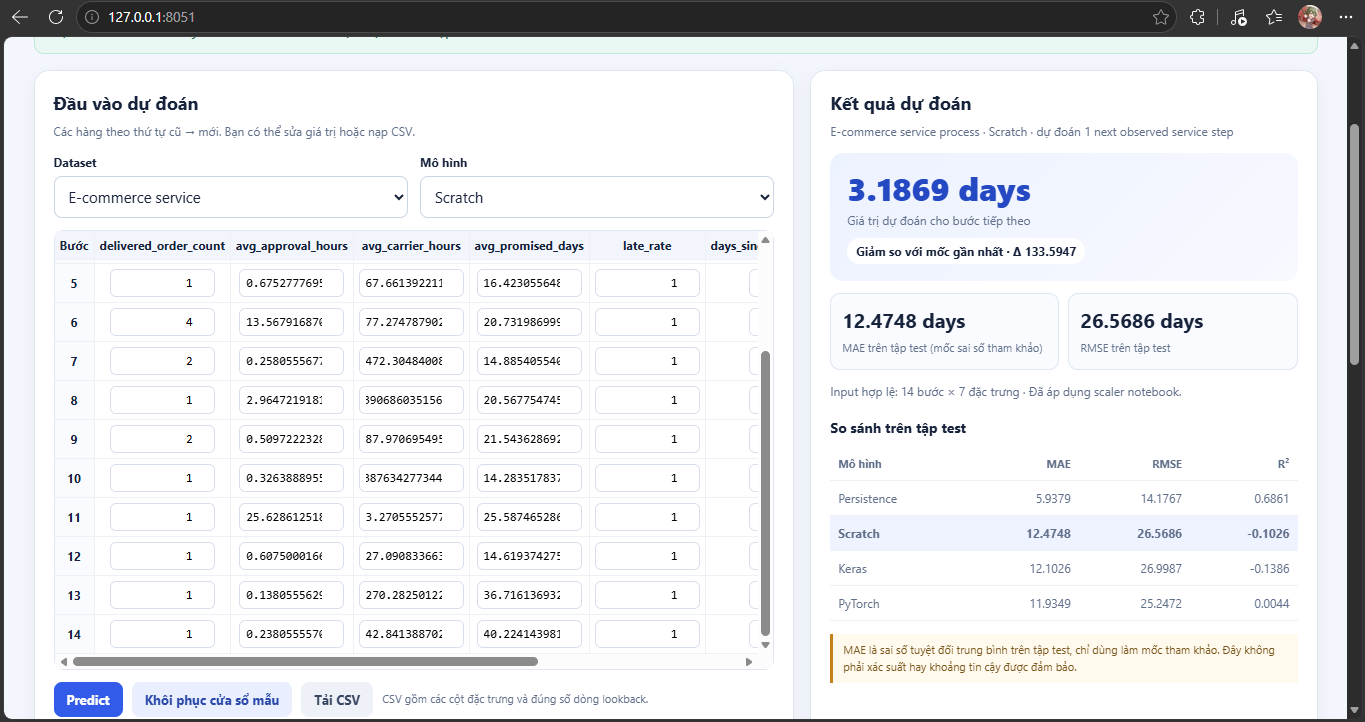
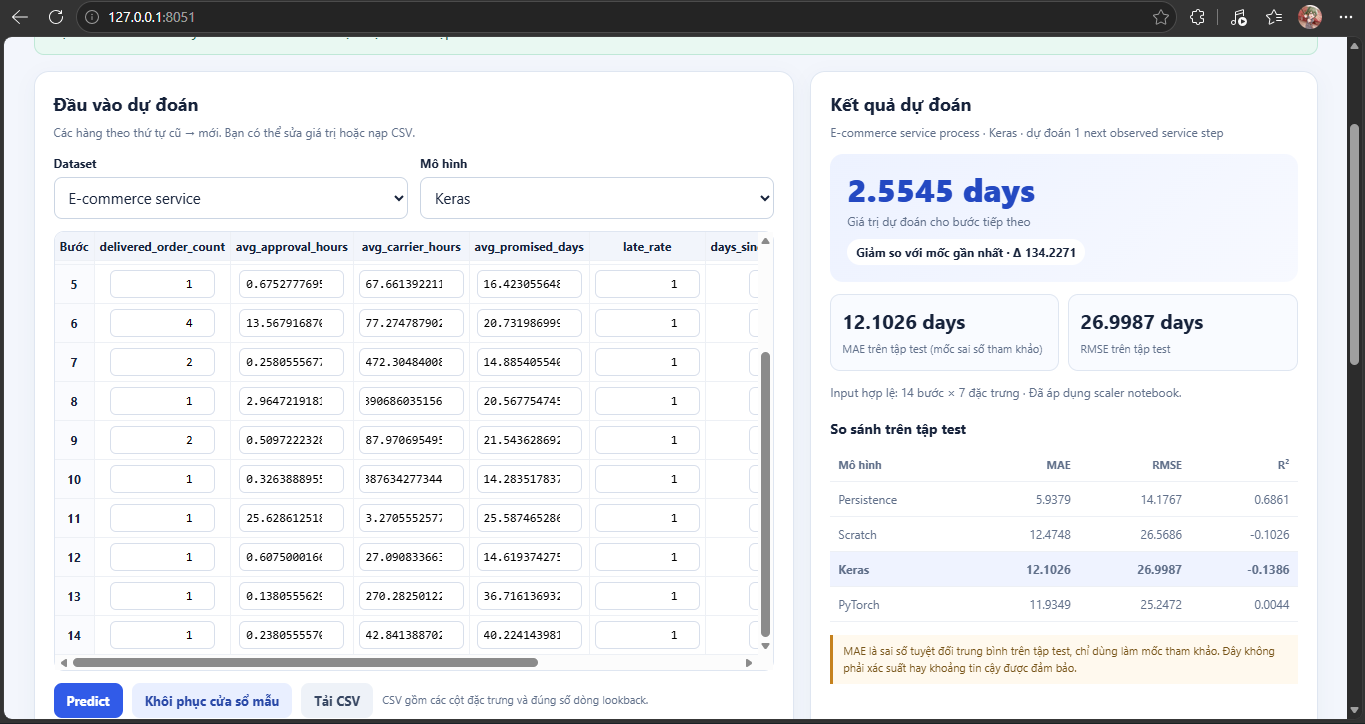
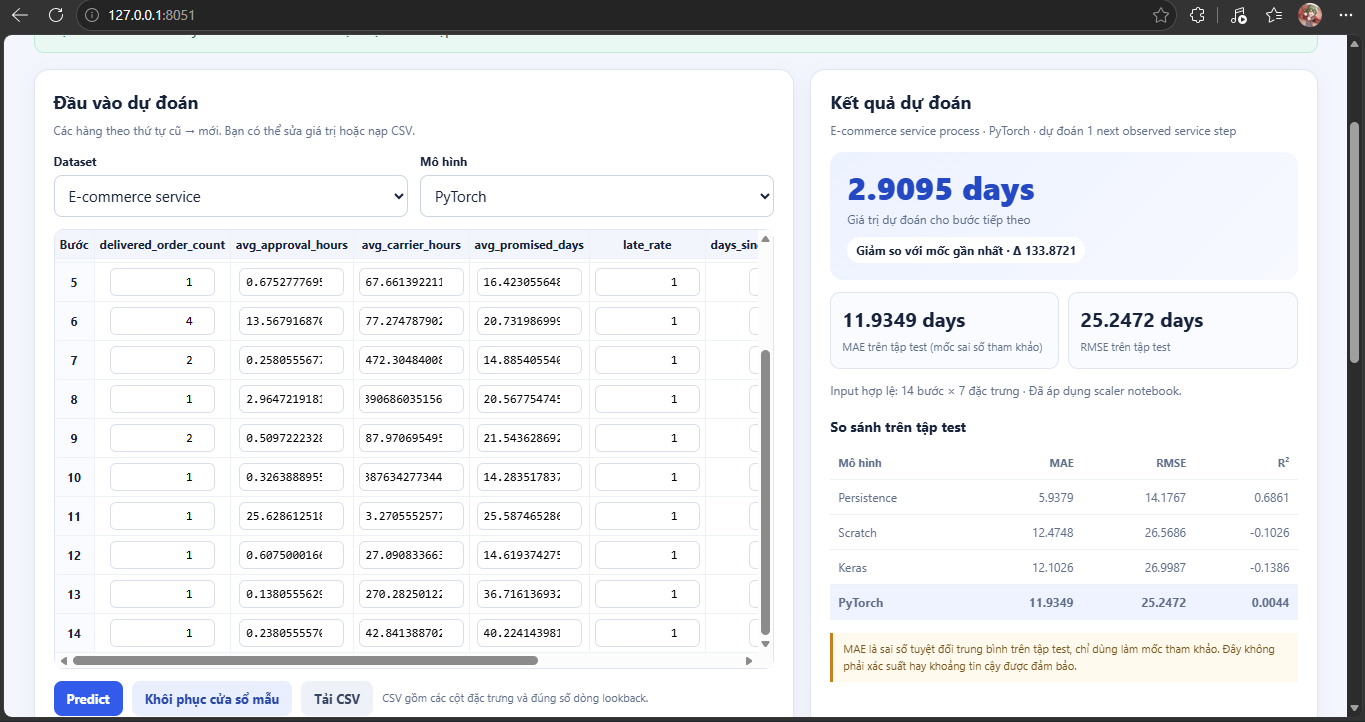
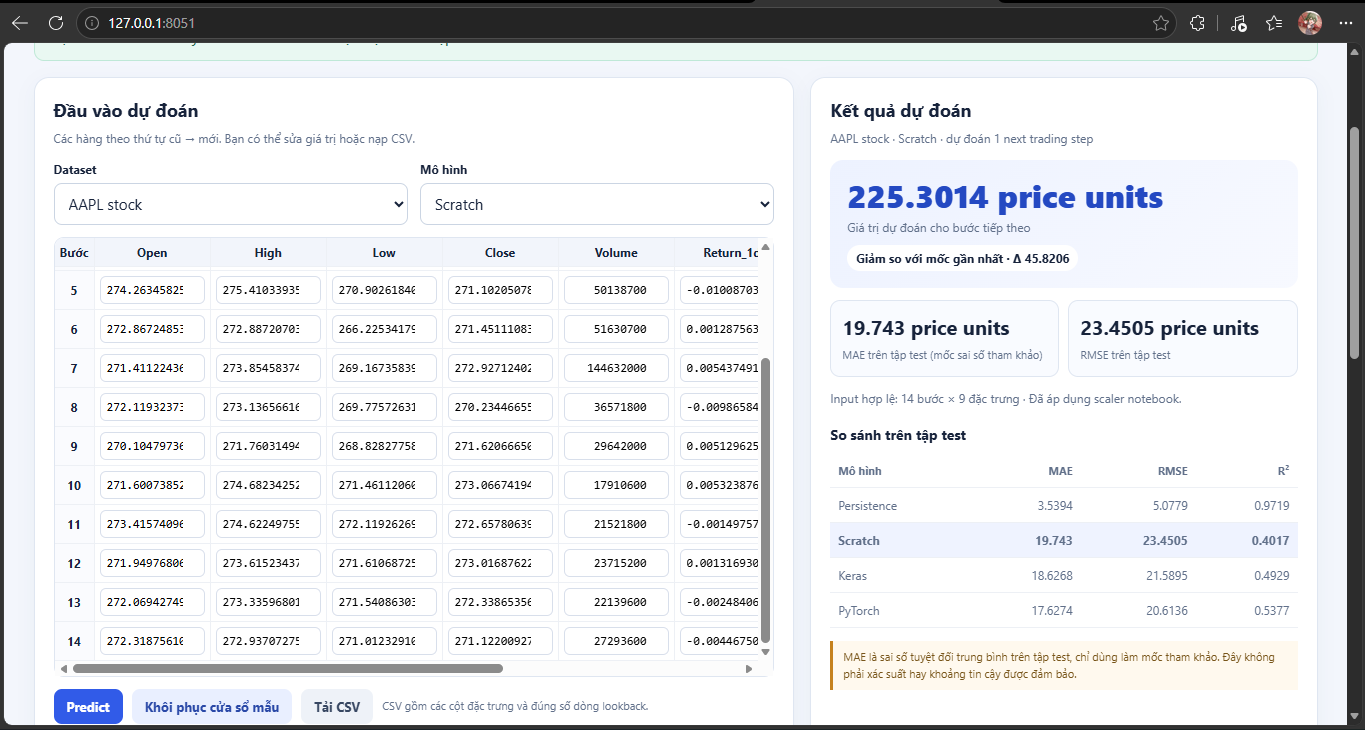
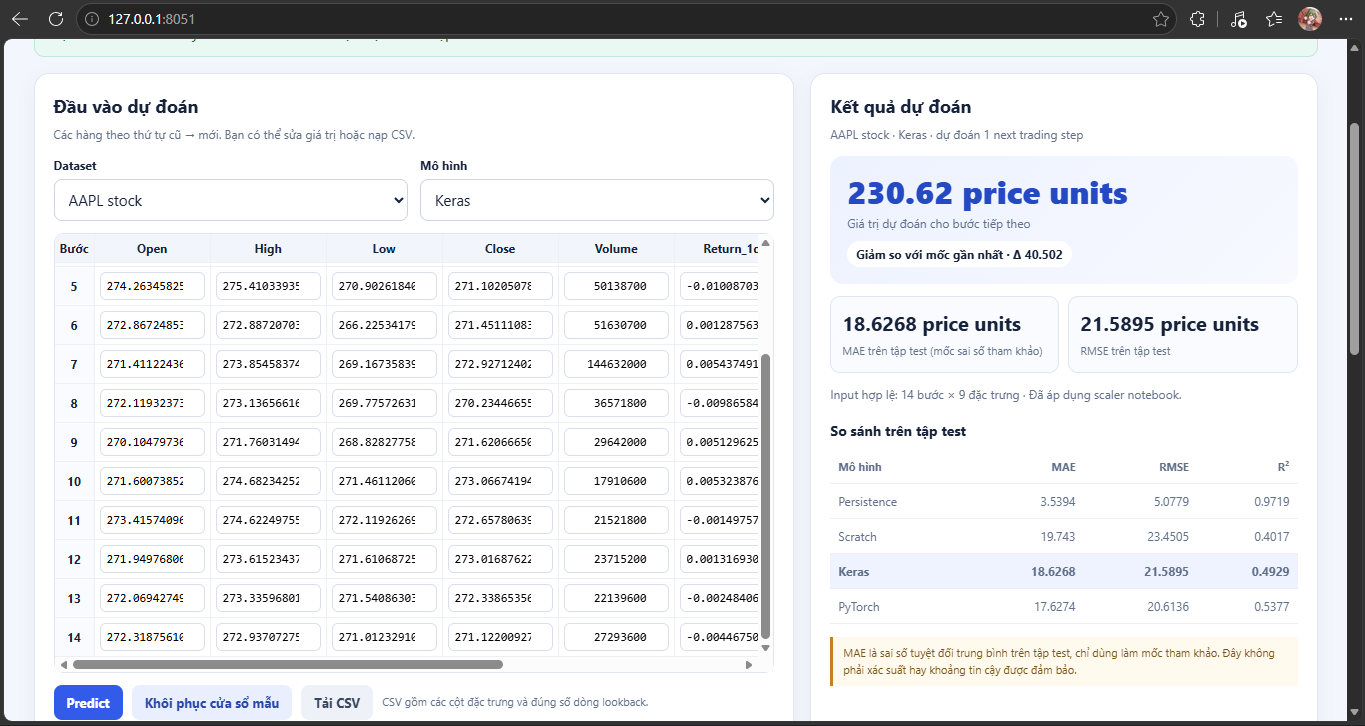
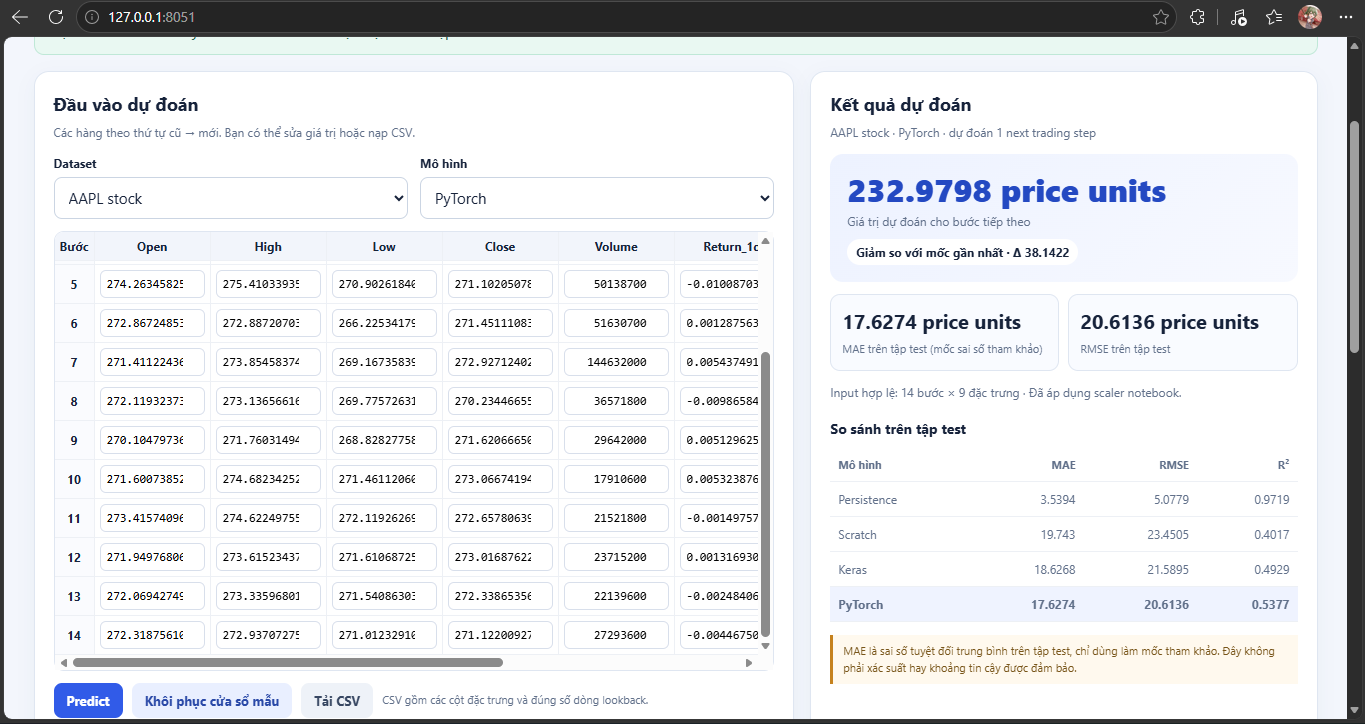